# Dataset Elegido:

## Diabetes 130-US Hospitals for Years 1999-2008

El conjunto de datos abarca diez años (1999-2008) de atención clínica en **130 hospitales y redes integradas de prestación de servicios sanitarios de EE. UU**. Cada fila corresponde a los historiales hospitalarios de pacientes diagnosticados con diabetes, a los que se les realizaron análisis de laboratorio, se les **administraron medicamentos y permanecieron ingresados hasta 14 días**. El objetivo es **determinar el reingreso precoz del paciente en los 30 días siguientes al alta**. El problema es importante por las siguientes razones. A pesar de que existen pruebas de alta calidad que demuestran una mejora en los resultados clínicos de los pacientes diabéticos que reciben diversas intervenciones preventivas y terapéuticas, **muchos pacientes no las reciben**. Esto puede atribuirse en parte a un tratamiento arbitrario de la diabetes en el ámbito hospitalario, que no presta la atención necesaria al control glucémico. La falta de una atención adecuada de la diabetes no solo aumenta los costes de gestión para los hospitales (al producirse **reingresos de los pacientes**), sino que también repercute en la morbilidad y la mortalidad de los pacientes, que pueden sufrir complicaciones asociadas a la diabetes.

Información adicional

El dataset representa diez años (1999–2008) de atención clínica en 130 hospitales y redes integradas de salud de Estados Unidos. Incluye más de 50 variables que representan resultados de pacientes y hospitales. La información fue extraída de la base de datos para los encuentros (episodios de atención) que cumplían con los siguientes criterios:

1. Es un encuentro de internación (una admisión hospitalaria).
2. Es un encuentro diabético, es decir, uno durante el cual se registró en el sistema algún tipo de diabetes como diagnóstico.
3. La duración de la internación fue de al menos 1 día y como máximo 14 días.
4. Se realizaron análisis de laboratorio durante el encuentro.
5. Se administraron medicamentos durante el encuentro.

Los datos contienen atributos como número de paciente, raza, género, edad, tipo de admisión, tiempo en el hospital, especialidad médica del médico que admitió al paciente, cantidad de análisis de laboratorio realizados, resultado del test de HbA1c, diagnóstico, cantidad de medicamentos, medicamentos para la diabetes, cantidad de visitas ambulatorias, de internación y de emergencia en el año previo a la hospitalización, etc.

## Diccionario de variables

Descripción de las 50 columnas del dataset, agrupadas por tema. Fuente: [UCI Machine
Learning Repository](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008)
y Tabla 1 de Strack et al. (2014), *"Impact of HbA1c Measurement on Hospital
Readmission Rates"*, BioMed Research International.

### Identificadores

| Variable | Descripción |
|---|---|
| `encounter_id` | Identificador único de un encuentro (una internación) |
| `patient_nbr` | Identificador único de un paciente |

### Demográficas

| Variable | Descripción |
|---|---|
| `race` | Valores: Caucasian, Asian, African American, Hispanic, y other |
| `gender` | Valores: male, female, y unknown/invalid |
| `age` | Agrupada en intervalos de 10 años: [0,10), [10,20), ..., [90,100) |
| `weight` | Peso en libras (con ~97% de faltantes) |

### Datos de la internación

| Variable | Descripción |
|---|---|
| `admission_type_id` | Código entero, 8 valores presentes en este dataset: por ejemplo emergencia, urgente, electiva, recién nacido, no disponible |
| `discharge_disposition_id` | Código entero, 26 valores presentes en este dataset: por ejemplo alta a domicilio, fallecido, no disponible |
| `admission_source_id` | Código entero, 17 valores presentes en este dataset: por ejemplo derivación médica, guardia, transferencia desde otro hospital |
| `time_in_hospital` | Cantidad de días entre la admisión y el alta |
| `payer_code` | Código del pagador/obra social (con muchos faltantes) |
| `medical_specialty` | Especialidad médica del profesional que admitió al paciente |

### Actividad clínica durante la internación

| Variable | Descripción |
|---|---|
| `num_lab_procedures` | Cantidad de análisis de laboratorio realizados durante la internación |
| `num_procedures` | Cantidad de procedimientos (no de laboratorio) realizados |
| `num_medications` | Cantidad de medicamentos distintos administrados |
| `number_diagnoses` | Cantidad de diagnósticos registrados |
| `diag_1`, `diag_2`, `diag_3` | Diagnóstico primario, secundario y terciario (códigos ICD-9) |
| `max_glu_serum` | Resultado del test de glucosa en sangre (>200, >300, Normal, o no medido) |
| `A1Cresult` | Resultado del test de HbA1c (>7, >8, Normal, o no medido) |

### Historial previo (año anterior a la internación)

| Variable | Descripción |
|---|---|
| `number_outpatient` | Cantidad de visitas ambulatorias en el año previo |
| `number_emergency` | Cantidad de visitas de urgencia en el año previo |
| `number_inpatient` | Cantidad de internaciones previas en el año previo |

### Medicamentos (23 columnas, una por droga)

`metformin`, `repaglinide`, `nateglinide`, `chlorpropamide`, `glimepiride`, `acetohexamide`,
`glipizide`, `glyburide`, `tolbutamide`, `pioglitazone`, `rosiglitazone`, `acarbose`,
`miglitol`, `troglitazone`, `tolazamide`, `examide`, `citoglipton`, `insulin`,
`glyburide-metformin`, `glipizide-metformin`, `glimepiride-pioglitazone`,
`metformin-rosiglitazone`, `metformin-pioglitazone`

Cada una indica si esa droga fue recetada y si la dosis fue: **Up** (aumentada),
**Down** (disminuida), **Steady** (sin cambios) o **No** (no recetada).

### Resumen y variable objetivo

| Variable | Descripción |
|---|---|
| `change` | Si hubo algún cambio en la medicación para diabetes (Ch / No) |
| `diabetesMed` | Si se recetó algún medicamento para diabetes (Yes / No) |
| `readmitted` | **Variable objetivo**: NO (no reingresó), >30 (reingresó después de 30 días), <30 (reingresó antes de 30 días) |

---
# EDA
### Diabetes 130-US Hospitals — Predicción de reingreso hospitalario

## Nota sobre el orden de este notebook

Esta versión reorganiza el trabajo alrededor de una única pregunta, aplicada celda por celda:

> **¿Este número lo necesito para *diseñar* el split, o es una decisión de *modelado*?**

Esa pregunta parte el análisis exploratorio en dos bloques con reglas distintas:

| | **EDA estructural** (sección 1) | **EDA analítico** (sección 3) |
|---|---|---|
| **Cuándo** | Antes del split | Después del split, **solo sobre train** |
| **Qué incluye** | Dimensiones, `dtypes`, cómo vienen codificados los faltantes, % de nulos, cardinalidad, duplicados, estructura de identificadores, errores de carga | Distribuciones, momentos, umbrales de outliers, entropía, correlaciones, y **todas** las medidas de asociación contra el target |
| **Por qué ahí** | El split **depende** de esto: no se puede elegir agrupar por `patient_nbr` sin haber descubierto antes que `patient_nbr` se repite | Son estimaciones muestrales que alimentan decisiones de modelado; calcularlas con test adentro sesga esas decisiones (*data snooping*) |

El principio que ordena todo el pipeline es más estricto que "no tocar test": **ningún estadístico que después se use para transformar los datos —moda de imputación, umbral de winsorización, media/desvío de escalado, medias de target encoding, componentes de PCA— se ajusta con datos de test**, y además ninguna *decisión* de preprocesamiento se toma mirando un número que haya visto test.

## El segundo criterio: la selección de variables va antes de codificar

Por indicación de la cátedra, **Chi², ANOVA F e información mutua se calculan después del split
pero antes del encoding**, para descartar variables enteras aunque se pierda algo de granularidad.
Eso ubica la selección (sección 6) **antes** de la codificación (sección 7), y tiene tres
consecuencias que se desarrollan en la sección 6:

1. Cada criterio se aplica al tipo de variable que le corresponde — Chi² sobre tablas de
   contingencia reales, ANOVA F sobre numéricas, información mutua sobre ambas.
2. La unidad de decisión es la **variable**, no la columna codificada: no se conservan tres dummies
   sueltas de una variable descartando las otras quince.
3. Se acepta explícitamente el costo en granularidad a cambio de un modelo más simple de explicar.

Como PCA necesita una matriz numérica, la **extracción** de features (sección 8) sí queda después
de codificar y escalar. Las dos técnicas de reducción de dimensionalidad que pide la consigna
—selección y extracción— quedan así separadas, cada una en el punto del pipeline donde corresponde.

**Estructura resultante:** 1 EDA estructural → 2 problema y split → 3 EDA analítico → 4
preprocesamiento → 5 feature engineering → **6 selección de variables** → 7 codificación, escalado
y balance → 8 PCA → 9 conclusiones → 10 modelado.

Al final se agregan dos secciones fuera del alcance literal de la consigna (conclusiones y modelado predictivo de referencia) a modo de cierre.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mtick
import seaborn as sns
import missingno as msno
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr, kendalltau, f_oneway
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold, cross_validate,
                                     train_test_split as tts_muestra)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, chi2, mutual_info_classif
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# 1. EDA estructural (antes del split)

Este bloque cubre exclusivamente lo que hay que saber **para poder diseñar el split**: cuántas
filas y columnas hay, de qué tipo es cada variable, cómo vienen codificados los faltantes,
cuánta cardinalidad tiene cada categórica, si hay duplicados y —el punto decisivo— **cómo se
estructuran los identificadores**.

Ninguno de estos números es un estadístico que alimente una decisión de modelado: son
propiedades del archivo (conteos, tipos, unicidad) o reglas fijas de calidad de datos. Las
distribuciones, los umbrales de outliers y todo lo que cruza contra el target quedan para la
sección 3, ya con el split hecho.

## 1.1 Carga del dataset

In [2]:
data_set_path = "diabetic_data.csv"
data_set = pd.read_csv(data_set_path)

print(f"Dimensiones del dataset: {data_set.shape[0]} filas x {data_set.shape[1]} columnas")
data_set.head()

Dimensiones del dataset: 101766 filas x 50 columnas


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1.2 Observaciones, variables y tipos de datos

En este dataset los valores faltantes **no** están representados como `NaN` sino con el string
`"?"` (una decisión de diseño de quien lo cargó). Se detectan y convierten para que Pandas no 
reporte cero nulos y todo el análisis posterior parta de una premisa falsa.

In [3]:
data_set = data_set.replace(r"^\s*\?\s*$", np.nan, regex=True)

print(f"Número de observaciones: {data_set.shape[0]}")
print(f"Número de variables: {data_set.shape[1]}")
print()
data_set.info()

Número de observaciones: 101766
Número de variables: 50

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  nu

In [4]:
data_set.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

101.766 observaciones (encuentros hospitalarios) y 50 variables. La mayoría llega
como `object` (texto) o `int64`, pero varias de las `int64` son en realidad **códigos
categóricos** (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) y no
cantidades: promediarlos no tendría sentido médico.

### Recodificación determinística de tipos

Se aplican los mapeos **fijos** (diccionario código → significado, tipado nominal/ordinal) de
las variables codificadas como números o texto libre. Ninguno usa un estadístico calculado
sobre los datos: son correspondencias tomadas del diccionario de variables del dataset, por lo
que el resultado sería idéntico si se aplicaran por separado sobre train y test. Por eso pueden
ir antes del split sin riesgo alguno.

In [5]:
cols_texto = data_set.select_dtypes(include=["object", "string"]).columns.tolist()
for c in cols_texto:
    data_set[c] = data_set[c].str.strip()

cols_enteras = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
for c in cols_enteras:
    data_set[c] = data_set[c].astype(int)

for c in cols_texto:
    data_set[c] = data_set[c].astype("category")

print("Valores únicos de 'race':", sorted(data_set["race"].dropna().unique()))
print("Valores únicos de 'gender':", sorted(data_set["gender"].dropna().unique()))
data_set.dtypes.value_counts()

Valores únicos de 'race': ['AfricanAmerican', 'Asian', 'Caucasian', 'Hispanic', 'Other']
Valores únicos de 'gender': ['Female', 'Male', 'Unknown/Invalid']


int64       13
category    13
category     7
category     2
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

In [6]:
mapa_admission_type = {
    1: "Emergency", 2: "Urgent", 3: "Elective", 4: "Newborn",
    5: "Not Available", 6: "NULL", 7: "Trauma Center", 8: "Not Mapped",
}
data_set["admission_type_id"] = pd.Categorical(
    data_set["admission_type_id"].astype(int).map(mapa_admission_type), ordered=False
)

mapa_discharge_disposition = {
    1: "Discharged to home", 2: "Discharged/transferred to another short term hospital",
    3: "Discharged/transferred to SNF", 4: "Discharged/transferred to ICF",
    5: "Discharged/transferred to another type of inpatient care institution",
    6: "Discharged/transferred to home with home health service", 7: "Left AMA",
    8: "Discharged/transferred to home under care of Home IV provider",
    9: "Admitted as an inpatient to this hospital",
    10: "Neonate discharged to another hospital for neonatal aftercare",
    11: "Expired", 12: "Still patient or expected to return for outpatient services",
    13: "Hospice / home", 14: "Hospice / medical facility",
    15: "Discharged/transferred within this institution to Medicare approved swing bed",
    16: "Discharged/transferred/referred another institution for outpatient services",
    17: "Discharged/transferred/referred to this institution for outpatient services",
    18: "NULL", 19: "Expired at home. Medicaid only, hospice.",
    20: "Expired in a medical facility. Medicaid only, hospice.",
    21: "Expired, place unknown. Medicaid only, hospice.",
    22: "Discharged/transferred to another rehab fac including rehab units of a hospital",
    23: "Discharged/transferred to a long term care hospital",
    24: "Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare",
    25: "Not Mapped", 26: "Unknown/Invalid",
    27: "Discharged/transferred to a federal health care facility",
    28: "Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital",
    29: "Discharged/transferred to a Critical Access Hospital (CAH)",
}
data_set["discharge_disposition_id"] = pd.Categorical(
    data_set["discharge_disposition_id"].astype(int).map(mapa_discharge_disposition), ordered=False
)

mapa_admission_source = {
    1: "Physician Referral", 2: "Clinic Referral", 3: "HMO Referral",
    4: "Transfer from a hospital", 5: "Transfer from a Skilled Nursing Facility (SNF)",
    6: "Transfer from another health care facility", 7: "Emergency Room",
    8: "Court/Law Enforcement", 9: "Not Available",
    10: "Transfer from a critical access hospital", 11: "Normal Delivery",
    12: "Premature Delivery", 13: "Sick Baby", 14: "Extramural Birth",
    15: "Not Available", 17: "NULL", 18: "Transfer From Another Home Health Agency",
    19: "Readmission to Same Home Health Agency", 20: "Not Mapped",
    21: "Unknown/Invalid",
    22: "Transfer from hospital inpt/same facility resulting in a separate claim",
    23: "Born inside this hospital", 24: "Born outside this hospital",
    25: "Transfer from Ambulatory Surgery Center", 26: "Transfer from Hospice",
}
data_set["admission_source_id"] = pd.Categorical(
    data_set["admission_source_id"].astype(int).map(mapa_admission_source), ordered=False
)

orden_age = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
             "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
data_set["age"] = pd.Categorical(data_set["age"], categories=orden_age, ordered=True)

data_set["max_glu_serum"] = pd.Categorical(data_set["max_glu_serum"],
                                           categories=["Norm", ">200", ">300"], ordered=True)
data_set["A1Cresult"] = pd.Categorical(data_set["A1Cresult"],
                                       categories=["Norm", ">7", ">8"], ordered=True)

def agrupar_diag(codigo):
    codigo = str(codigo)
    if codigo == "nan":
        return np.nan
    if codigo.startswith("V"):
        return "Factores de salud"
    if codigo.startswith("E"):
        return "Causas externas"
    try:
        c = float(codigo)
    except ValueError:
        return "Otro"
    if 390 <= c <= 459: return "Circulatorio"
    if 460 <= c <= 519: return "Respiratorio"
    if 520 <= c <= 579: return "Digestivo"
    if 250 <= c < 251: return "Diabetes"
    if 800 <= c <= 999: return "Lesiones/cirugia traumatologica"
    if 580 <= c <= 629: return "Genitourinario"
    if 710 <= c <= 739: return "Musculoesqueletico"
    if 140 <= c <= 239: return "Neoplasias"
    return "Otro"

for c in ["diag_1", "diag_2", "diag_3"]:
    data_set[c] = pd.Categorical(data_set[c].apply(agrupar_diag))

data_set["readmitted"] = data_set["readmitted"].astype("category")

print("dtypes finales (muestra):")
data_set[["admission_type_id", "discharge_disposition_id", "age", "diag_1", "readmitted"]].dtypes

dtypes finales (muestra):


admission_type_id           category
discharge_disposition_id    category
age                         category
diag_1                      category
readmitted                  category
dtype: object

Nota: `max_glu_serum` y `A1Cresult` se registran por ahora **sin** la categoría "No medido" —
agregarla es *tratamiento* de faltantes y va en la sección 4.1. Acá sólo se fija el orden real
entre sus valores medidos (`Norm` < `>200`/`>7` < `>300`/`>8`).

## 1.3 Inventario de valores faltantes y su mecanismo (MCAR / MAR / MNAR / estructural)

Contar nulos es una propiedad del archivo, no un estadístico de modelado: `weight` falta en el
97% de las filas independientemente de qué partición se mire. Clasificar el mecanismo es un
juicio de dominio. Ambas cosas pertenecen al bloque estructural, y además condicionan qué
columnas van a sobrevivir al preprocesamiento.

In [7]:
nulos = data_set.isnull().sum()
nulos_pct = (nulos / len(data_set) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "% nulos": nulos_pct})
resumen_nulos = resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("% nulos", ascending=False)
resumen_nulos

,nulos,% nulos
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


| Columna | % Faltante | Mecanismo probable | Justificación |
|---|---|---|---|
| `weight` | ~97% | **MNAR / estructural** | No se pesa de rutina a un paciente internado salvo indicación médica puntual. La ausencia depende del propio dato (si pesar era relevante clínicamente). |
| `max_glu_serum`, `A1Cresult` | ~95% / ~83% | **MNAR / estructural** | Son análisis que sólo se piden según criterio médico o protocolo del hospital; su ausencia está ligada a la decisión clínica, no al azar. |
| `medical_specialty` | ~49% | **MAR** | Depende de si el hospital registra la especialidad del médico tratante (varía por institución/época), algo relacionado con otras variables observadas más que con el valor en sí. |
| `payer_code` | ~40% | **MAR** | Vinculado a procesos administrativos del hospital, no al estado clínico del paciente. |
| `race` | ~2% | **MCAR (aprox.)** | Proporción baja y sin patrón evidente; probablemente omisión aleatoria al completar el formulario. |
| `diag_1/2/3` | <2% | **MCAR** | Muy pocos casos, probablemente errores de carga puntuales. |

### Evidencia visual de los patrones de faltantes (`missingno`)

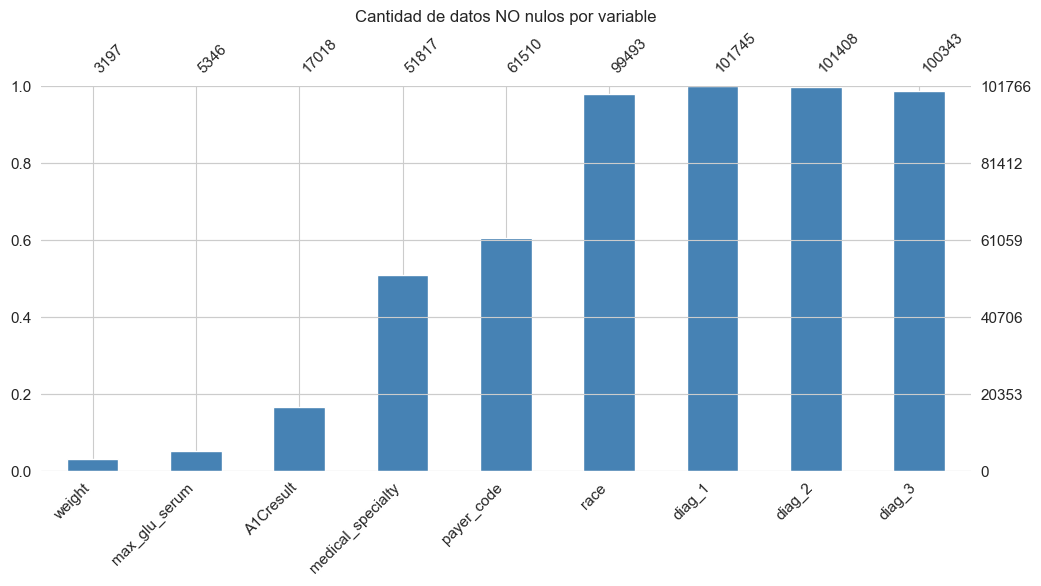

In [8]:
cols_con_faltantes = ["weight", "max_glu_serum", "A1Cresult", "medical_specialty",
                      "payer_code", "race", "diag_1", "diag_2", "diag_3"]

msno.bar(data_set[cols_con_faltantes], fontsize=11, figsize=(12, 5), color="steelblue")
plt.title("Cantidad de datos NO nulos por variable")
plt.show()

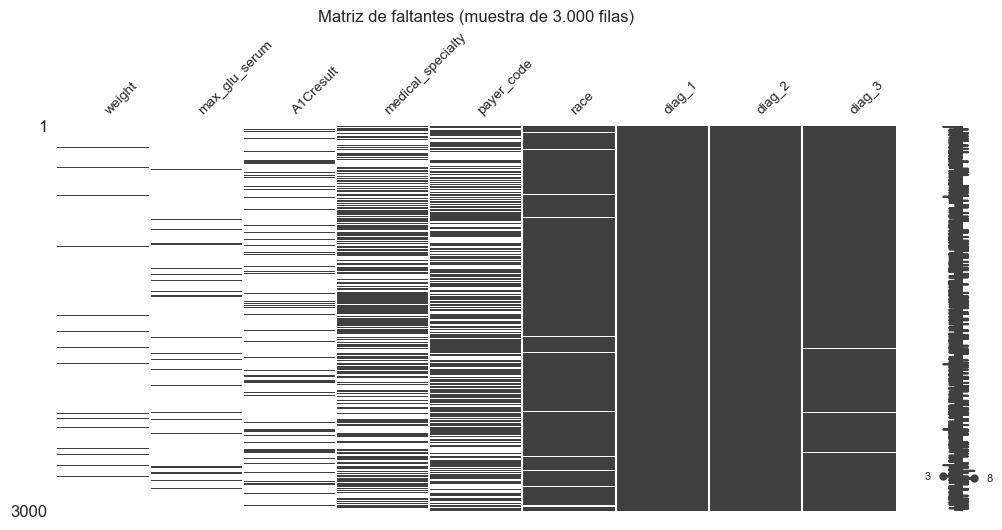

In [9]:
muestra = data_set[cols_con_faltantes].sample(3000, random_state=RANDOM_STATE)
msno.matrix(muestra, figsize=(12, 5), fontsize=10)
plt.title("Matriz de faltantes (muestra de 3.000 filas)")
plt.show()

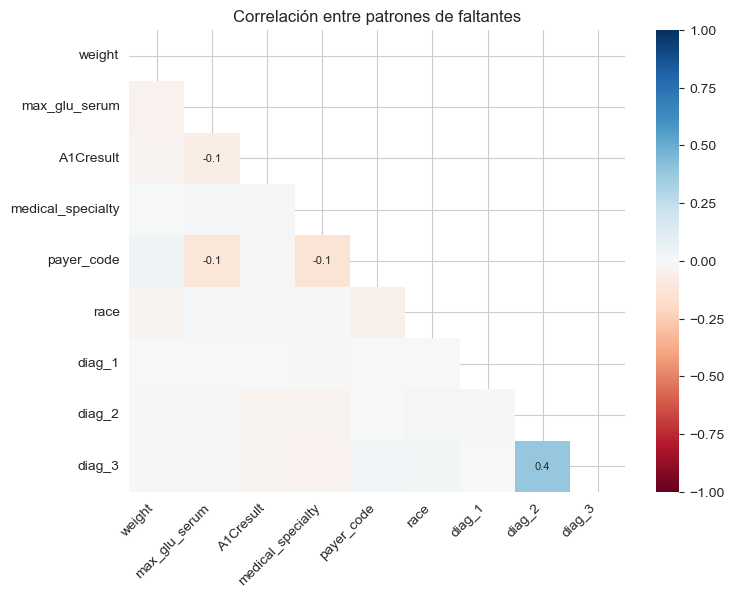

In [10]:
msno.heatmap(data_set[cols_con_faltantes], fontsize=10, figsize=(8, 6))
plt.title("Correlación entre patrones de faltantes")
plt.show()

El heatmap de correlación de nulos no muestra pares fuertemente correlacionados
(todos los valores cercanos a 0), consistente con la clasificación de la tabla: `weight`,
`max_glu_serum`/`A1Cresult`, `medical_specialty`/`payer_code` y `race` faltan por **motivos
independientes entre sí** (decisión clínica, proceso administrativo, omisión aleatoria) y no por
un único proceso subyacente que afecte a varias columnas a la vez.

## 1.4 Cardinalidad de las variables categóricas

La cardinalidad es una propiedad estructural (cuántos valores distintos admite la columna) y es
lo que va a determinar la **estrategia de codificación** de la sección 7: las nominales con **10 o
más categorías** van a target encoding y las de menos de 10 a one-hot. Conviene tenerla a la vista
desde el principio para poder justificar después dónde cae ese corte.

In [11]:
cols_categoricas = data_set.select_dtypes(include=["category"]).columns.tolist()
card = (pd.DataFrame({
            "n_categorias": [data_set[c].nunique(dropna=True) for c in cols_categoricas],
            "% nulos": [data_set[c].isna().mean() * 100 for c in cols_categoricas],
        }, index=cols_categoricas)
        .round(2)
        .sort_values("n_categorias", ascending=False))
card.head(20)

,n_categorias,% nulos
medical_specialty,72,49.08
discharge_disposition_id,26,0.00
admission_source_id,17,0.00
payer_code,17,39.56
diag_1,11,0.02
diag_2,11,0.35
diag_3,11,1.40
age,10,0.00
weight,9,96.86
admission_type_id,8,0.00


La cardinalidad no se reparte de forma continua, se reparte en **dos grupos
separados por un hueco**. Arriba están `medical_specialty` (72 categorías),
`discharge_disposition_id` (26), `admission_source_id` (17), `payer_code` (17) y los tres
diagnósticos (11 cada uno) — todas nominales que un one-hot haría explotar. Abajo, `race` (5), las
23 columnas de droga y el resto de las categóricas tienen 2-5 categorías. **No hay ninguna variable
nominal entre 6 y 10 categorías**, y ese hueco es el que va a permitir fijar el umbral de la
sección 7 sin elegirlo a medida. `age` (10) y `weight` (9) caen en el medio pero no compiten en esa
decisión: `age` es ordinal y `weight` se elimina por faltantes. Esta tabla se retoma tal cual en la
sección 7.

## 1.5 Duplicados y estructura de identificadores

**Este es el punto que determina cómo hay que partir el dataset**, y por eso tiene que resolverse
antes del split y no después. Dos preguntas:

1. ¿Hay filas repetidas? Si las hubiera y se eliminaran *después* de partir, una copia podría
   quedar en train y otra en test.
2. ¿Un mismo paciente aparece en más de una fila? Si es así, un split aleatorio por fila
   repartiría encuentros del mismo paciente entre ambas particiones, y el modelo podría
   "reconocerlo" en test — fuga de información a nivel paciente.

In [12]:
print(f"Encuentros (filas) duplicados por encounter_id: {data_set['encounter_id'].duplicated().sum()}")
print(f"Filas totalmente duplicadas (todas las columnas iguales): {data_set.duplicated().sum()}")
print()
print(f"Filas totales:                {data_set.shape[0]}")
print(f"Pacientes únicos:             {data_set['patient_nbr'].nunique()}")
print(f"Filas con patient_nbr repetido: {data_set['patient_nbr'].duplicated().sum()}")
print()
enc_por_paciente = data_set["patient_nbr"].value_counts()
print("Distribución de encuentros por paciente:")
print(enc_por_paciente.value_counts().sort_index().head(10).rename("cantidad de pacientes"))
print(f"\nMáximo de encuentros de un mismo paciente: {enc_por_paciente.max()}")

Encuentros (filas) duplicados por encounter_id: 0
Filas totalmente duplicadas (todas las columnas iguales): 0

Filas totales:                101766
Pacientes únicos:             71518
Filas con patient_nbr repetido: 30248

Distribución de encuentros por paciente:
count
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: cantidad de pacientes, dtype: int64

Máximo de encuentros de un mismo paciente: 40


**Lectura y consecuencia directa sobre el diseño del split:** no hay `encounter_id` repetidos ni
filas 100% idénticas, así que **no hay duplicados por eliminar**. Pero unos 30.000 registros
corresponden a pacientes que ya aparecen en otra fila: los `patient_nbr` repetidos **no son
duplicados**, son internaciones distintas del mismo paciente a lo largo de 10 años.

Esto descarta `train_test_split` simple y obliga a un **split agrupado por `patient_nbr`**
(sección 2). Es exactamente el tipo de decisión que el EDA estructural tiene que habilitar: sin
esta celda, la sección 2 no tendría fundamento.

## 1.6 Errores e inconsistencias — limpieza general

Última pieza estructural: valores que no corresponden a ninguna categoría válida. Es una regla
fija de calidad de datos (no depende de ningún estadístico), y **define el universo del estudio**,
por lo que tiene que aplicarse antes de partir el dataset.

In [13]:
print("Casos con gender inválido ('Unknown/Invalid'):", (data_set["gender"] == "Unknown/Invalid").sum())

print("Filas antes:", data_set.shape[0])
data_set = data_set[data_set["gender"] != "Unknown/Invalid"].copy()
data_set["gender"] = data_set["gender"].cat.remove_unused_categories()
print("Filas después:", data_set.shape[0])

Casos con gender inválido ('Unknown/Invalid'): 3
Filas antes: 101766
Filas después: 101763


# 2. Problema de ML supervisado y split del dataset

## 2.1 Planteo del problema

**Tipo de problema:** clasificación supervisada (binaria).

**Variable target:** `readmitted`, que en el dataset original tiene 3 clases (`NO`, `>30`, `<30`).
Siguiendo el objetivo clínico planteado por los autores del dataset —anticipar el **reingreso
temprano (dentro de los 30 días del alta)**, que es el que más impacto tiene en costos y en la
salud del paciente— se recodifica como problema **binario**:

- `1` → el paciente reingresó dentro de los 30 días (`<30`)
- `0` → no reingresó o reingresó después de 30 días (`NO` o `>30`)

**Features:** el resto de las variables clínicas y administrativas, excluyendo identificadores
sin valor predictivo (`encounter_id`, `patient_nbr`).

**Por qué se plantea acá y no después:** la recodificación es una regla fija (`readmitted == "<30"`),
no un estadístico, y hace falta tener el target definido **antes** de partir para poder verificar
que la proporción de clase positiva quede comparable entre train y test.

**Por qué es razonable como problema de ML:** anticipar el riesgo de reingreso permite priorizar
el seguimiento post-alta en los pacientes de mayor riesgo. La sección 3 va a mostrar que ninguna
variable aislada separa fuerte al target, que es justamente el escenario donde un modelo
multivariado aporta más que una regla simple.

In [14]:
data_set["readmitted_temprano"] = (data_set["readmitted"] == "<30").astype(int)

print(data_set["readmitted"].value_counts())
print()
print("Variable target binaria 'readmitted_temprano':")
data_set["readmitted_temprano"].value_counts(normalize=True).round(3)

readmitted
NO     54861
>30    35545
<30    11357
Name: count, dtype: int64

Variable target binaria 'readmitted_temprano':


readmitted_temprano
0    0.888
1    0.112
Name: proportion, dtype: float64

## 2.2 Split train / test (agrupado por paciente)

Como se estableció en 1.5, un mismo `patient_nbr` tiene varios encuentros. Se usa
`GroupShuffleSplit` agrupando por paciente para garantizar que **ningún paciente aparezca en
ambas particiones**.

`GroupShuffleSplit` no soporta estratificar por clase de forma nativa, así que se verifica
manualmente que la proporción de clase positiva quede razonablemente similar entre train y test.

A partir de esta celda, **el conjunto de test queda congelado**: no se lo grafica, no se calculan
estadísticos sobre él, y no vuelve a aparecer hasta la evaluación final de la sección 8.

In [15]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
idx_train_split, idx_test_split = next(gss.split(data_set, groups=data_set["patient_nbr"]))

encounter_ids_train = set(data_set.iloc[idx_train_split]["encounter_id"])
data_set["_es_train"] = data_set["encounter_id"].isin(encounter_ids_train)

pacientes_train = set(data_set.loc[data_set["_es_train"], "patient_nbr"])
pacientes_test = set(data_set.loc[~data_set["_es_train"], "patient_nbr"])
encounters_train = set(data_set.loc[data_set["_es_train"], "encounter_id"])
encounters_test = set(data_set.loc[~data_set["_es_train"], "encounter_id"])

assert len(pacientes_train & pacientes_test) == 0, "Hay pacientes repetidos entre train y test"
assert len(encounters_train & encounters_test) == 0, "Hay encuentros repetidos entre train y test"
assert len(encounters_train) + len(encounters_test) == data_set.shape[0], "Se perdieron o duplicaron filas"

print("Pacientes en ambas particiones (debe ser 0):", len(pacientes_train & pacientes_test))
print("Encuentros en ambas particiones (debe ser 0):", len(encounters_train & encounters_test))
print(f"Filas train: {data_set['_es_train'].sum()} ({data_set['_es_train'].mean()*100:.1f}%)")
print(f"Filas test:  {(~data_set['_es_train']).sum()} ({(~data_set['_es_train']).mean()*100:.1f}%)")

tasa_train = data_set.loc[data_set["_es_train"], "readmitted_temprano"].mean()
tasa_test = data_set.loc[~data_set["_es_train"], "readmitted_temprano"].mean()
print(f"\nTasa de reingreso <30d - train: {tasa_train*100:.2f}%  test: {tasa_test*100:.2f}%")

Pacientes en ambas particiones (debe ser 0): 0
Encuentros en ambas particiones (debe ser 0): 0
Filas train: 71583 (70.3%)
Filas test:  30180 (29.7%)

Tasa de reingreso <30d - train: 11.27%  test: 10.91%


In [16]:
# A partir de acá, TODO el analisis exploratorio de la seccion 3 usa unicamente df_train.
df_train = data_set[data_set["_es_train"]].copy()

print(f"df_train: {df_train.shape[0]} filas x {df_train.shape[1]} columnas")
print(f"Pacientes distintos en train: {df_train['patient_nbr'].nunique()}")

df_train: 71583 filas x 52 columnas
Pacientes distintos en train: 50060


# 3. EDA analítico (después del split, solo sobre train)

Todo lo que sigue son **estimaciones muestrales**: momentos, límites de outliers, entropías,
correlaciones y medidas de asociación contra el target. Cambian según qué filas se miren, y
alimentan decisiones concretas de modelado (qué variables winsorizar, cuáles discretizar, cuáles
descartar por redundancia). Por eso se calculan exclusivamente sobre `df_train`.

Cubre lo que la consigna pide en sus puntos "patrones generales y distribuciones", "identificar
outliers" y toda la sección de visualización.

## 3.1 Variables numéricas: estadística descriptiva y forma de la distribución

In [17]:
cols_numericas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                  "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

resumen = pd.DataFrame({
    "media": df_train[cols_numericas].mean(),
    "mediana": df_train[cols_numericas].median(),
    "desvio_std": df_train[cols_numericas].std(),
    "MAD": df_train[cols_numericas].apply(lambda s: stats.median_abs_deviation(s)),
    "asimetria": df_train[cols_numericas].apply(lambda s: stats.skew(s)),
    "curtosis": df_train[cols_numericas].apply(lambda s: stats.kurtosis(s)),
}).round(2)
resumen

,media,mediana,desvio_std,MAD,asimetria,curtosis
time_in_hospital,4.39,4.0,2.98,2.0,1.14,0.87
num_lab_procedures,43.18,44.0,19.64,13.0,-0.24,-0.25
num_procedures,1.33,1.0,1.70,1.0,1.33,0.89
num_medications,16.00,15.0,8.11,5.0,1.32,3.45
number_outpatient,0.37,0.0,1.28,0.0,8.74,144.09
number_emergency,0.20,0.0,0.99,0.0,24.48,1259.94
number_inpatient,0.65,0.0,1.30,0.0,3.71,21.77
number_diagnoses,7.43,8.0,1.93,1.0,-0.87,-0.08


**Lectura:** `num_lab_procedures` y `number_diagnoses` son las más simétricas del grupo (asimetría
negativa leve). `num_procedures`, `num_medications` y `time_in_hospital` muestran asimetría
positiva moderada. En cambio `number_outpatient`, `number_emergency` y `number_inpatient`
presentan **asimetría positiva muy fuerte**: la mayoría de los pacientes en 0 y una cola larga de
pocos pacientes con muchas visitas previas.

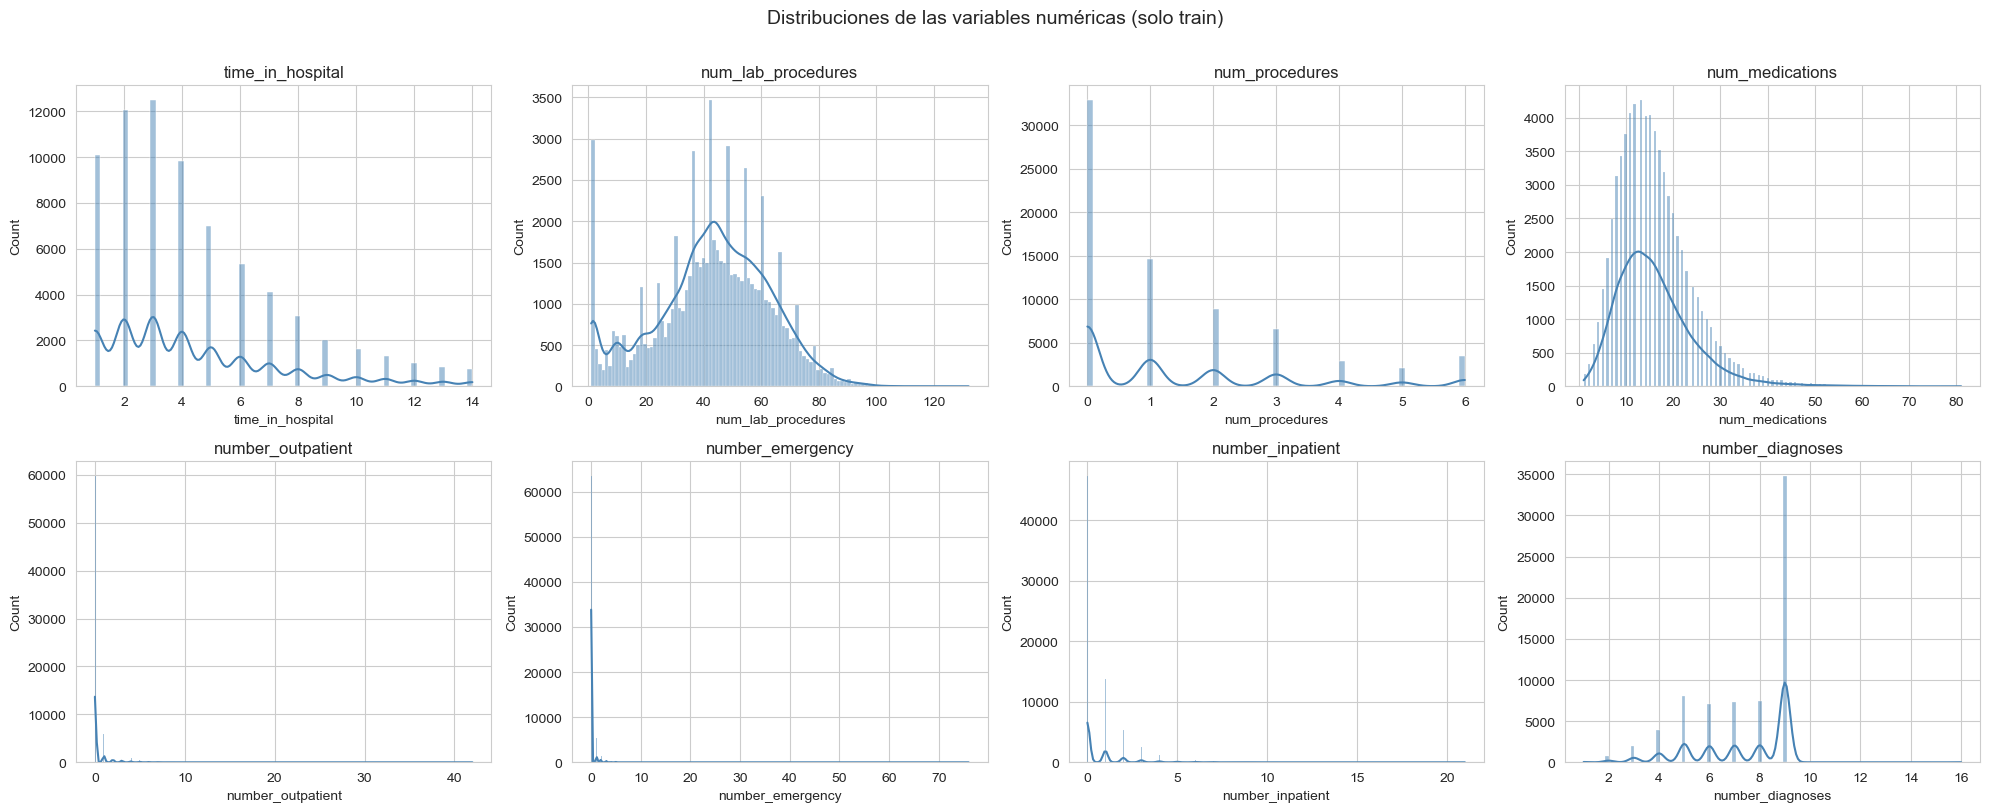

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, cols_numericas):
    sns.histplot(df_train[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
fig.suptitle("Distribuciones de las variables numéricas (solo train)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [19]:
df_train[cols_numericas].describe(percentiles=[.1, .25, .5, .75, .9, .95]).round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00
mean,4.39,43.18,1.33,16.00,0.37,0.20,0.65,7.43
std,2.98,19.64,1.70,8.11,1.28,0.99,1.30,1.93
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
10%,1.00,14.00,0.00,7.00,0.00,0.00,0.00,5.00
25%,2.00,32.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
90%,9.00,67.00,4.00,26.00,1.00,1.00,2.00,9.00
95%,11.00,73.00,5.00,31.00,2.00,1.00,3.00,9.00


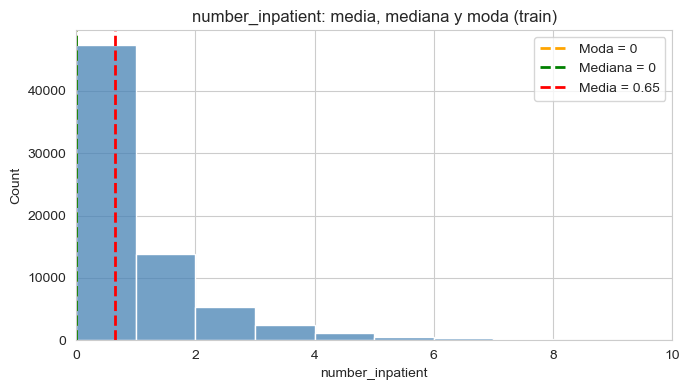

In [20]:
col = "number_inpatient"
media, mediana, moda = df_train[col].mean(), df_train[col].median(), df_train[col].mode()[0]

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df_train[col], bins=range(0, 12), ax=ax, color="steelblue")
ax.axvline(moda, color="orange", ls="--", lw=2, label=f"Moda = {moda:.0f}")
ax.axvline(mediana, color="green", ls="--", lw=2, label=f"Mediana = {mediana:.0f}")
ax.axvline(media, color="red", ls="--", lw=2, label=f"Media = {media:.2f}")
ax.set_xlim(0, 10)
ax.set_title("number_inpatient: media, mediana y moda (train)")
ax.legend()
plt.tight_layout()
plt.show()

Mediana y moda coinciden en 0, mientras que la media queda desplazada hacia la
derecha por la cola de pacientes con varias internaciones previas — caso típico donde la mediana
representa mejor al paciente "promedio".

## 3.2 Identificación de outliers (IQR, solo train)

El criterio de rango intercuartílico usa Q1 y Q3, que **son estadísticos muestrales**: por eso
esta celda pertenece al bloque analítico y se calcula sobre train. Los límites que salen de acá
son los que después justifican el tratamiento de la sección 4.2 (winsorización) y la
discretización de la 5.1.

In [21]:
def resumen_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]
    return lim_inf, lim_sup, len(outliers), len(outliers) / len(serie) * 100

cols_outliers_interes = ["num_lab_procedures", "number_emergency", "number_inpatient", "num_medications"]
for col in cols_outliers_interes:
    lim_inf, lim_sup, n_out, pct_out = resumen_outliers_iqr(df_train[col])
    print(f"{col:22s} límites=({lim_inf:6.1f}, {lim_sup:6.1f})  "
          f"outliers={n_out:6d} ({pct_out:5.2f}%)  max={df_train[col].max()}")

num_lab_procedures     límites=(  -5.5,   94.5)  outliers=   147 ( 0.21%)  max=132
number_emergency       límites=(   0.0,    0.0)  outliers=  8075 (11.28%)  max=76
number_inpatient       límites=(  -1.5,    2.5)  outliers=  5094 ( 7.12%)  max=21
num_medications        límites=(  -5.0,   35.0)  outliers=  1780 ( 2.49%)  max=81


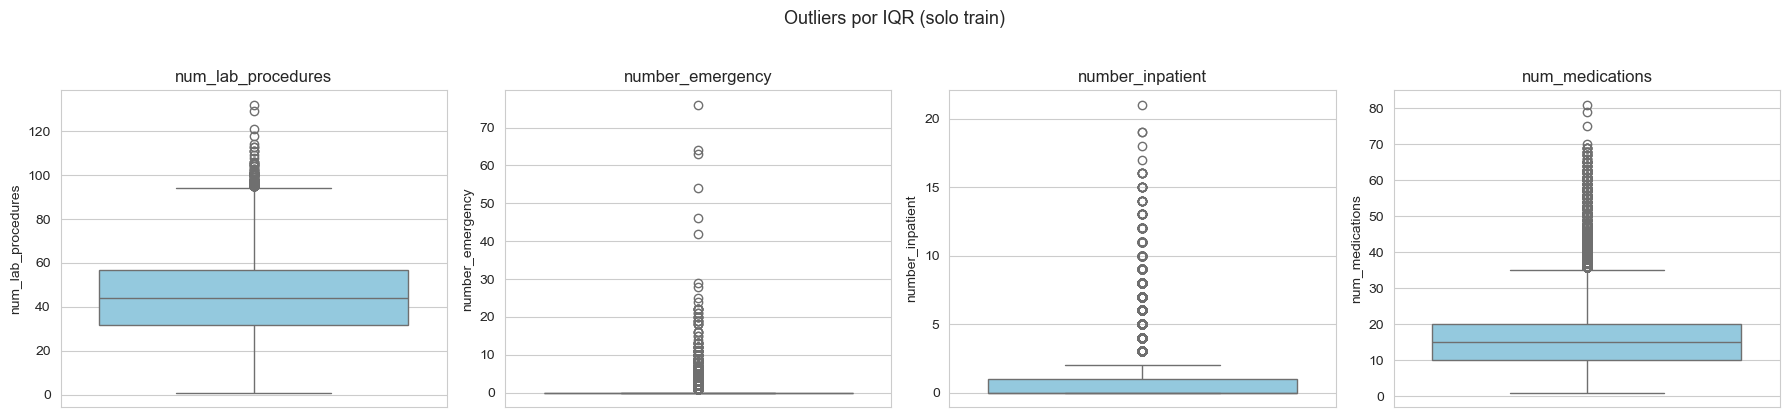

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols_outliers_interes):
    sns.boxplot(y=df_train[col], ax=ax, color="skyblue")
    ax.set_title(col)
fig.suptitle("Outliers por IQR (solo train)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

**Interpretación clínica (identificación, sin tratar todavía):**

- `num_lab_procedures`: el máximo observado es plausible en una internación larga con múltiples estudios.
- `number_emergency` y `number_inpatient`: la mayoría de los pacientes tiene 0 visitas previas, así
  que IQR marca como "outlier" a *cualquier valor positivo*. Es un artefacto de una distribución
  muy asimétrica, no un error de carga — son justamente los pacientes de alto riesgo, la población
  que más interesa para el problema de reingreso. **Esta observación es la que motiva discretizarlas
  en la sección 5.1.**
- `num_medications`: asimetría más moderada; los valores altos reflejan polimedicación clínicamente relevante.
- Ninguno parece un **error** de carga: son valores clínicamente posibles. El tratamiento se
  decide y aplica en la sección 4.2.

### 3.2.1 Verificación: ¿cambia algo por haber calculado esto sobre train en vez de sobre todo el dataset?

La sección 3 se calcula únicamente sobre train porque son estimaciones muestrales. Cabe la
pregunta inversa: ¿esa restricción metodológica cambia algo en la práctica, o el 70% de los
datos ya alcanza para estimar bien estos estadísticos? Se compara acá con los mismos cálculos
sobre el dataset completo, usado únicamente para esta verificación.

In [23]:
comparacion_iqr = []
for col in cols_outliers_interes:
    li_tr, ls_tr, _, _ = resumen_outliers_iqr(df_train[col])
    li_full, ls_full, _, _ = resumen_outliers_iqr(data_set[col])
    comparacion_iqr.append({
        "variable": col,
        "lim_inf (train)": round(li_tr, 2), "lim_inf (completo)": round(li_full, 2),
        "lim_sup (train)": round(ls_tr, 2), "lim_sup (completo)": round(ls_full, 2),
    })
display(pd.DataFrame(comparacion_iqr))

corr_train = df_train[cols_numericas].corr()
corr_full = data_set[cols_numericas].corr()
dif_max = (corr_train - corr_full).abs().values.max()
print(f"\nDiferencia máxima absoluta entre las matrices de correlación (train vs. completo): {dif_max:.4f}")

,variable,lim_inf (train),lim_inf (completo),lim_sup (train),lim_sup (completo)
0,num_lab_procedures,-5.5,-8.0,94.5,96.0
1,number_emergency,0.0,0.0,0.0,0.0
2,number_inpatient,-1.5,-1.5,2.5,2.5
3,num_medications,-5.0,-5.0,35.0,35.0



Diferencia máxima absoluta entre las matrices de correlación (train vs. completo): 0.0136


## 3.3 Variables categóricas: cardinalidad y entropía de Shannon

La entropía mide qué tan "repartidas" están las observaciones entre categorías: cerca de 0 = una
categoría domina casi todo; cerca del máximo = distribución equilibrada. Es una métrica calculada
sobre frecuencias observadas, así que va acá y no en la sección 1.

In [24]:
def entropia_shannon(serie):
    counts = serie.value_counts(dropna=True)
    probs = counts / counts.sum()
    h = stats.entropy(probs, base=2)
    h_max = np.log2(len(counts))
    return counts.shape[0], h, h_max, (h / h_max if h_max > 0 else np.nan)

cols_categoricas_interes = ["race", "gender", "age", "admission_type_id",
                            "discharge_disposition_id", "admission_source_id",
                            "medical_specialty", "payer_code", "diag_1", "diag_2", "diag_3",
                            "max_glu_serum", "A1Cresult", "readmitted"]

filas = []
for c in cols_categoricas_interes:
    n_cat, h, h_max, h_norm = entropia_shannon(df_train[c])
    filas.append([c, n_cat, round(h, 2), round(h_max, 2), round(h_norm, 2)])

pd.DataFrame(filas, columns=["variable", "n_categorias", "entropia", "entropia_max", "entropia_normalizada"])

,variable,n_categorias,entropia,entropia_max,entropia_normalizada
0,race,5,1.01,2.32,0.44
1,gender,2,1.00,1.00,1.00
2,age,10,2.66,3.32,0.80
3,admission_type_id,8,1.84,3.00,0.61
4,discharge_disposition_id,26,2.10,4.70,0.45
5,admission_source_id,17,1.70,4.09,0.42
6,medical_specialty,72,3.57,6.17,0.58
7,payer_code,17,2.46,4.09,0.60
8,diag_1,11,2.90,3.46,0.84
9,diag_2,11,2.72,3.46,0.79


`gender` y `age` tienen entropía normalizada alta (categorías balanceadas). `race` y
`admission_source_id` están dominadas por 1-2 categorías. `medical_specialty`, con 70+ categorías,
tiene alta cardinalidad pero baja entropía relativa. El propio target, `readmitted`, tiene entropía
normalizada baja: ya se ve acá que las 3 clases **no están balanceadas** — se retoma en 7.5.

## 3.4 Visualizaciones univariadas

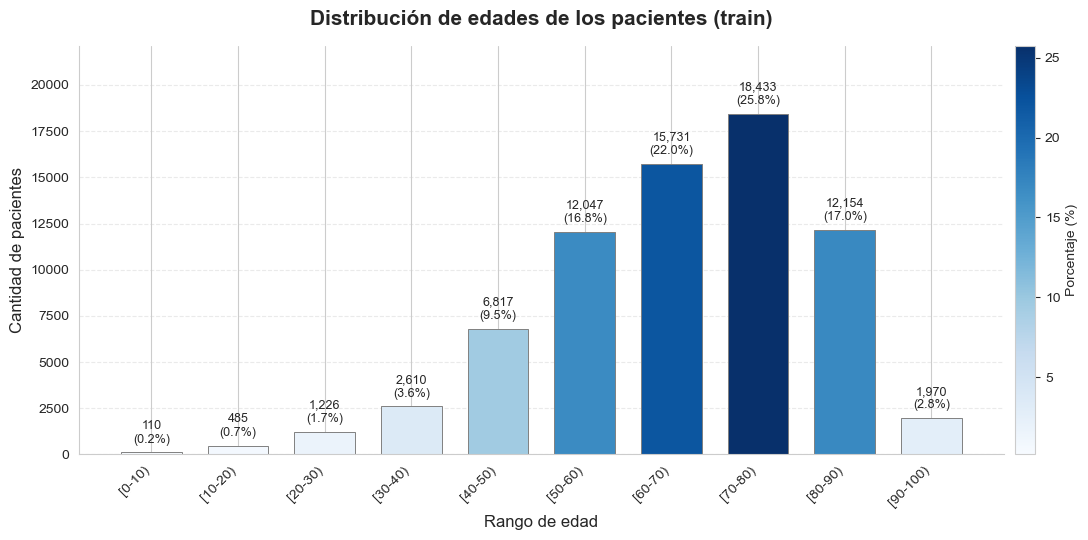

In [25]:
counts = df_train["age"].value_counts().sort_index()
total = counts.sum()
pcts = counts.values / total * 100

norm = mpl.colors.Normalize(vmin=pcts.min(), vmax=pcts.max())
cmap = mpl.colormaps["Blues"]
colores = [cmap(norm(p)) for p in pcts]

fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=colores,
              edgecolor="gray", linewidth=0.7, width=0.7)
for bar, valor, pct in zip(bars, counts.values, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, valor + total * 0.005,
            f"{valor:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)

ax.set_xlabel("Rango de edad", fontsize=12)
ax.set_ylabel("Cantidad de pacientes", fontsize=12)
ax.set_title("Distribución de edades de los pacientes (train)", fontsize=15, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_ylim(0, counts.max() * 1.2)

smap = mpl.cm.ScalarMappable(cmap=cmap, norm=norm); smap.set_array([])
cbar = fig.colorbar(smap, ax=ax, pad=0.01); cbar.set_label("Porcentaje (%)", fontsize=10)
plt.tight_layout()
plt.show()

**Gráfico :** barras (categórica ordinal con pocas categorías), con
una escala de color que refuerza el porcentaje de cada barra.

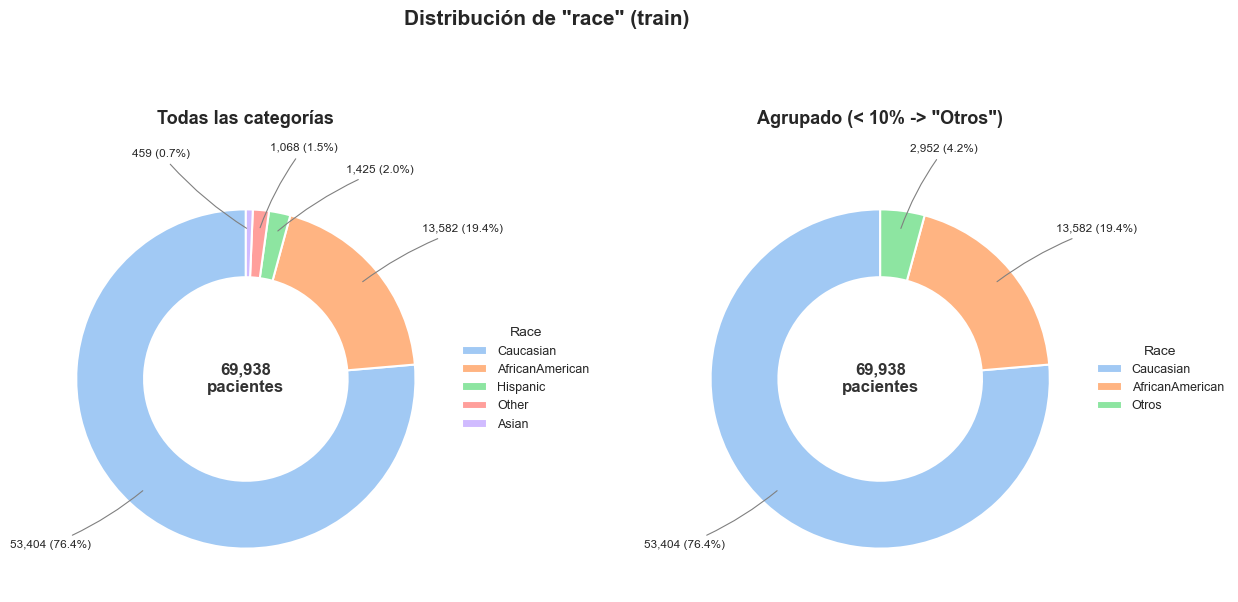

In [26]:
def plot_donut(data, column, group_others=False, threshold=0.10, title=None,
               palette="pastel", ax=None, radius=0.85, min_gap=20,
               radio_texto_mult=1.35, fontsize=8.5, title_pad=30):
    counts = data[column].value_counts()
    if group_others:
        pct = counts / counts.sum()
        major = counts[pct >= threshold].copy()
        minor = counts[pct < threshold]
        if len(minor) > 0:
            major["Otros"] = minor.sum()
        counts = major.sort_values(ascending=False)
    else:
        counts = counts.sort_values(ascending=False)

    total = counts.sum()
    colores = sns.color_palette(palette, len(counts))
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5.5))

    wedges, _ = ax.pie(counts.values, startangle=90, colors=colores, radius=radius,
                       wedgeprops=dict(width=0.4 * radius, edgecolor="white", linewidth=1.5))

    angulos_true = np.array([(w.theta2 + w.theta1) / 2 for w in wedges])
    angulos_disp = angulos_true.copy()
    for _ in range(500):
        cambiado = False
        for i in range(1, len(angulos_disp)):
            gap = angulos_disp[i] - angulos_disp[i - 1]
            if gap < min_gap:
                falta = (min_gap - gap) / 2
                angulos_disp[i] += falta; angulos_disp[i - 1] -= falta
                cambiado = True
        if not cambiado:
            break

    radio_texto = radius * radio_texto_mult
    for i, wedge in enumerate(wedges):
        ang_true, ang_disp = angulos_true[i], angulos_disp[i]
        x_true, y_true = np.cos(np.radians(ang_true)), np.sin(np.radians(ang_true))
        x_disp, y_disp = np.cos(np.radians(ang_disp)), np.sin(np.radians(ang_disp))
        alineacion = "right" if x_disp < 0 else "left"
        valor = counts.values[i]; pct = valor / total * 100
        ax.annotate(f"{valor:,} ({pct:.1f}%)",
                    xy=(x_true * radius * 0.88, y_true * radius * 0.88),
                    xytext=(x_disp * radio_texto, y_disp * radio_texto),
                    horizontalalignment=alineacion, fontsize=fontsize,
                    arrowprops=dict(arrowstyle="-", color="gray", lw=0.8,
                                    connectionstyle="arc3,rad=0.08"))

    ax.text(0, 0, f"{total:,}\npacientes", ha="center", va="center",
            fontsize=12, fontweight="bold", color="#333333")
    ax.legend(wedges, counts.index, title=column.capitalize(), loc="center left",
              bbox_to_anchor=(1.05, 0.5), frameon=False, fontsize=9)
    ax.set_title(title if title else f'Distribución de "{column}"',
                 fontsize=13, fontweight="bold", pad=title_pad)
    ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.1, 2.1); ax.axis("equal")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.subplots_adjust(wspace=0.7, top=0.76, bottom=0.05)
plot_donut(df_train, "race", group_others=False, title="Todas las categorías", ax=axes[0])
plot_donut(df_train, "race", group_others=True, threshold=0.10,
           title='Agrupado (< 10% -> "Otros")', ax=axes[1])
fig.suptitle('Distribución de "race" (train)', fontsize=15, fontweight="bold", y=1.02)
plt.show()

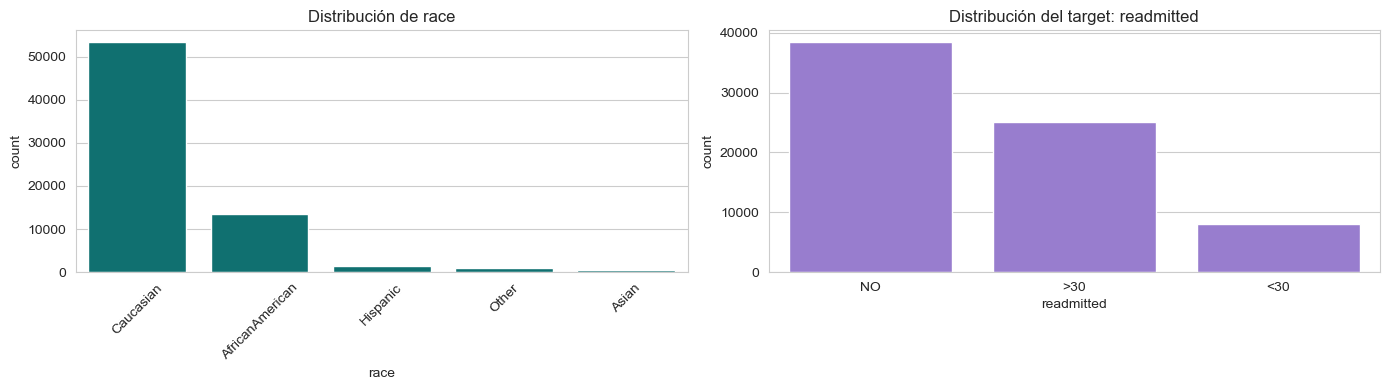

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df_train, x="race", order=df_train["race"].value_counts().index,
              ax=axes[0], color="teal")
axes[0].set_title("Distribución de race"); axes[0].tick_params(axis="x", rotation=45)
sns.countplot(data=df_train, x="readmitted", order=["NO", ">30", "<30"],
              ax=axes[1], color="mediumpurple")
axes[1].set_title("Distribución del target: readmitted")
plt.tight_layout()
plt.show()

**Gráfico :** dona/torta para `race` (categórica nominal, interesa la composición
proporcional del total) y barras para el conteo por categoría. Se ve a simple vista que
`readmitted` está desbalanceado — se cuantifica en 7.5.

## 3.5 Visualizaciones bivariadas contra el target

#### `age` vs `readmitted`

In [28]:
tabla_cruzada = pd.crosstab(df_train["age"], df_train["readmitted"], normalize="index") * 100
tabla_cruzada = tabla_cruzada[["NO", ">30", "<30"]]
tabla_cruzada.round(1)

readmitted,NO,>30,<30
age,,,
[0-10),81.8,17.3,0.9
[10-20),60.6,32.6,6.8
[20-30),53.1,31.2,15.7
[30-40),58.2,30.5,11.3
[40-50),55.9,33.7,10.5
[50-60),55.9,34.8,9.4
[60-70),53.7,35.0,11.3
[70-80),51.4,36.5,12.0
[80-90),51.5,36.3,12.2


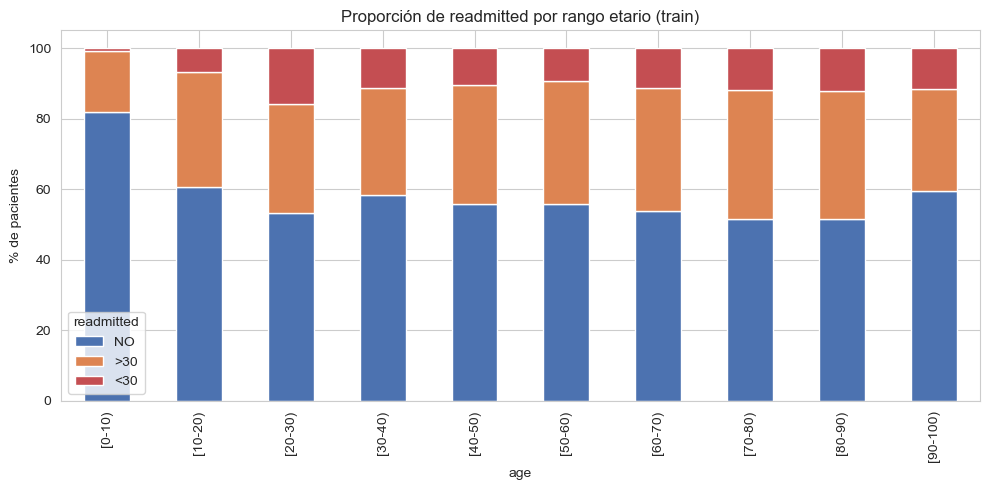

In [29]:
tabla_cruzada.plot(kind="bar", stacked=True, figsize=(10, 5),
                   color=["#4C72B0", "#DD8452", "#C44E52"])
plt.ylabel("% de pacientes")
plt.title("Proporción de readmitted por rango etario (train)")
plt.legend(title="readmitted")
plt.tight_layout()
plt.show()

**Gráfico :** barras apiladas (categórica ordinal × categórica nominal, para ver composición dentro de cada rango).
No es un crecimiento monótono con la edad. El reingreso temprano (`<30`) es bajo en
niños, pica en adultos jóvenes, baja hacia la mediana edad y vuelve a subir gradualmente en
adultos mayores sin recuperar el pico. 

#### `discharge_disposition_id` vs `readmitted`

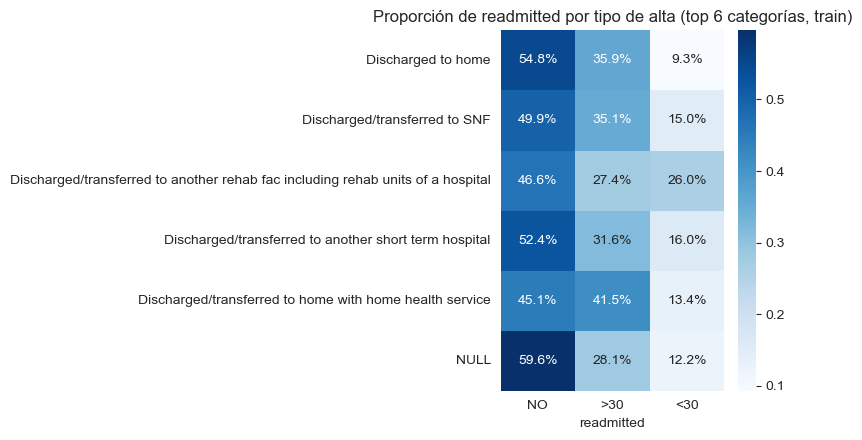

In [30]:
top_disposition = df_train["discharge_disposition_id"].value_counts().head(6).index
subset = df_train[df_train["discharge_disposition_id"].isin(top_disposition)].copy()

cross_tab_disp = pd.crosstab(subset["discharge_disposition_id"], subset["readmitted"],
                             normalize="index")
cross_tab_disp = cross_tab_disp.loc[cross_tab_disp.index.isin(top_disposition), ["NO", ">30", "<30"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(cross_tab_disp, annot=True, fmt=".1%", cmap="Blues", ax=ax)
ax.set_title("Proporción de readmitted por tipo de alta (top 6 categorías, train)")
ax.set_xlabel("readmitted"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Gráfico :** heatmap (categórica de cardinalidad media × categórica, para comparar muchas categorías de forma compacta).
El alta a domicilio es la que menos reingresos tempranos genera. Las altas con
seguimiento posterior tienen proporciones más altas, y la transferencia a **rehabilitación se
destaca claramente** — varias veces la tasa del alta a domicilio. 

## 3.6 Medidas de asociación contra el target

Todas calculadas sobre train. Se elige la medida según el **par de tipos** involucrado

#### Chi-cuadrado de independencia y V de Cramér (categórica – categórica)

In [31]:
def chi2_cramers_v(col, target="readmitted", data=None):
    data = df_train if data is None else data
    tabla = pd.crosstab(data[col], data[target])
    chi2_stat, p, dof, _ = chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2_stat / (n * k)) if k > 0 else np.nan
    return chi2_stat, p, v

vars_categoricas_test = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id",
                         "admission_source_id", "payer_code", "medical_specialty",
                         "diag_1", "diag_2", "diag_3", "A1Cresult", "max_glu_serum",
                         "insulin", "diabetesMed", "change"]

resultados = []
for c in vars_categoricas_test:
    chi2_stat, p, v = chi2_cramers_v(c)
    resultados.append([c, round(chi2_stat, 1), p, round(v, 3)])

cramer_target = (pd.DataFrame(resultados, columns=["variable", "chi2", "p_valor", "V_de_Cramer"])
                 .sort_values("V_de_Cramer", ascending=False)
                 .reset_index(drop=True))
cramer_target

,variable,chi2,p_valor,V_de_Cramer
0,discharge_disposition_id,2532.3,0.000000e+00,0.133
1,medical_specialty,833.8,9.988253e-101,0.107
2,admission_source_id,782.1,3.392260e-145,0.074
3,payer_code,375.5,3.076640e-60,0.066
4,diabetesMed,261.6,1.555116e-57,0.060
5,diag_1,440.1,3.921706e-82,0.055
6,insulin,392.4,1.184070e-81,0.052
7,change,161.3,9.403756e-36,0.047
8,admission_type_id,283.2,3.687357e-52,0.044
9,age,263.4,1.510369e-45,0.043


Con un tamaño muestral tan grande, prácticamente todas las variables dan
estadísticamente asociadas (p << 0.05), pero **el p-valor no dice nada sobre la fuerza**: para eso
está la V de Cramér. `discharge_disposition_id` se destaca claramente, seguida por
`admission_source_id`. `race`, `gender`, `A1Cresult` y `max_glu_serum` son las que menos
discriminan.

#### Coeficiente Phi (binaria – binaria)

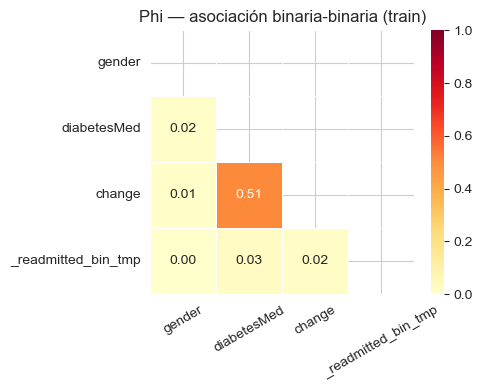

In [32]:
df_train["_readmitted_bin_tmp"] = (df_train["readmitted"] == "<30").astype(int)

def phi(x, y):
    tabla = pd.crosstab(x, y)
    chi2_stat = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2_stat / n)

vars_binarias = ["gender", "diabetesMed", "change", "_readmitted_bin_tmp"]
phi_mat = pd.DataFrame(index=vars_binarias, columns=vars_binarias, dtype=float)
for c1 in vars_binarias:
    for c2 in vars_binarias:
        phi_mat.loc[c1, c2] = 1.0 if c1 == c2 else phi(df_train[c1], df_train[c2])

mask_upper = np.triu(np.ones_like(phi_mat, dtype=bool))
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(phi_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, mask=mask_upper, ax=ax)
ax.set_title("Phi — asociación binaria-binaria (train)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

#### Punto Biserial (numérica – binaria)

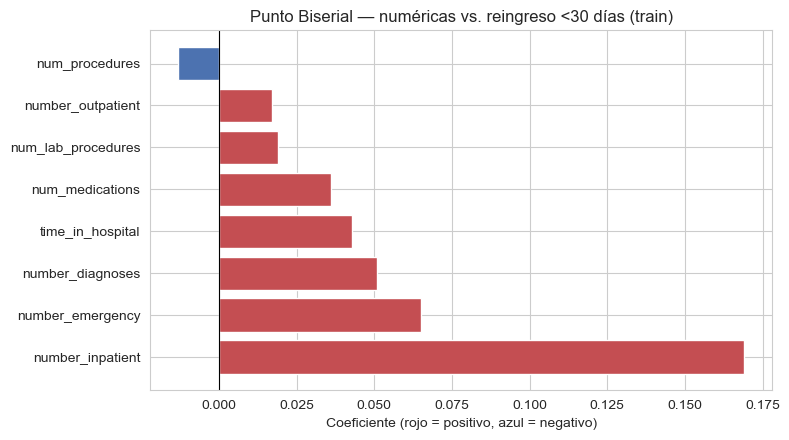

,variable,punto_biserial,p_valor
6,number_inpatient,0.169,0.000000e+00
5,number_emergency,0.065,1.196679e-68
7,number_diagnoses,0.051,6.448453e-42
0,time_in_hospital,0.043,4.837101e-30
3,num_medications,0.036,1.513032e-21
1,num_lab_procedures,0.019,4.973228e-07
4,number_outpatient,0.017,8.211182e-06
2,num_procedures,-0.013,3.135943e-04


In [33]:
resultados_pb = []
for col in cols_numericas:
    r, p = pointbiserialr(df_train["_readmitted_bin_tmp"], df_train[col])
    resultados_pb.append([col, round(r, 3), p])

pb_df = pd.DataFrame(resultados_pb, columns=["variable", "punto_biserial", "p_valor"])
pb_df = pb_df.sort_values("punto_biserial", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ["#C44E52" if v > 0 else "#4C72B0" for v in pb_df["punto_biserial"]]
ax.barh(pb_df["variable"], pb_df["punto_biserial"], color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Punto Biserial — numéricas vs. reingreso <30 días (train)")
ax.set_xlabel("Coeficiente (rojo = positivo, azul = negativo)")
plt.tight_layout()
plt.show()
pb_df

#### Kendall Tau-b (numérica – ordinal): `age` vs. numéricas

In [34]:
age_orden_local = list(df_train["age"].cat.categories)
age_codes = df_train["age"].map({cat: i for i, cat in enumerate(age_orden_local)})

resultados_tau = []
for col in cols_numericas:
    tau, p = kendalltau(age_codes, df_train[col], variant="b")
    resultados_tau.append([col, round(tau, 3), p])

pd.DataFrame(resultados_tau, columns=["variable", "kendall_tau_b", "p_valor"]) \
    .sort_values("kendall_tau_b", key=abs, ascending=False)

,variable,kendall_tau_b,p_valor
7,number_diagnoses,0.162,0.000000e+00
0,time_in_hospital,0.090,5.912821e-218
5,number_emergency,-0.057,1.035502e-67
2,num_procedures,-0.046,4.697923e-52
1,num_lab_procedures,0.022,9.588342e-16
4,number_outpatient,0.022,2.113731e-11
3,num_medications,0.019,3.924786e-12
6,number_inpatient,0.016,4.140835e-07


#### Eta cuadrado (numérica – categórica de 3 clases)

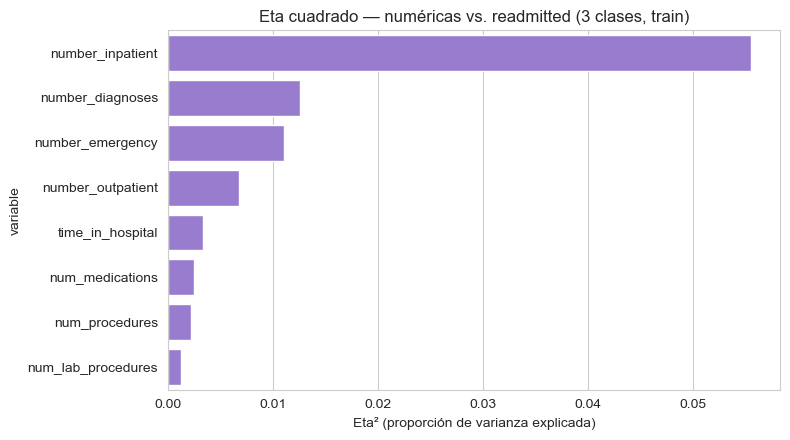

,variable,eta_cuadrado,p_valor
6,number_inpatient,0.0555,0.000000e+00
7,number_diagnoses,0.0126,1.852638e-197
5,number_emergency,0.0111,6.449392e-174
4,number_outpatient,0.0068,1.015036e-106
0,time_in_hospital,0.0034,9.638959e-54
3,num_medications,0.0025,1.738889e-39
2,num_procedures,0.0022,3.132795e-35
1,num_lab_procedures,0.0013,4.673295e-21


In [35]:
def eta_squared(continua, categorica):
    grupos = [g.to_numpy() for _, g in continua.groupby(categorica, observed=True)]
    F, p = f_oneway(*grupos)
    media_total = continua.mean()
    ss_total = ((continua - media_total) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - media_total) ** 2 for g in grupos)
    return ss_between / ss_total, p, F

resultados_eta = []
for col in cols_numericas:
    eta2v, p, F = eta_squared(df_train[col], df_train["readmitted"])
    resultados_eta.append([col, round(eta2v, 4), p])

eta_df = (pd.DataFrame(resultados_eta, columns=["variable", "eta_cuadrado", "p_valor"])
          .sort_values("eta_cuadrado", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=eta_df, y="variable", x="eta_cuadrado", color="mediumpurple", ax=ax)
ax.set_title("Eta cuadrado — numéricas vs. readmitted (3 clases, train)")
ax.set_xlabel("Eta² (proporción de varianza explicada)")
plt.tight_layout()
plt.show()
eta_df

Consistente con Punto Biserial, `number_inpatient` concentra la mayor proporción de
varianza explicada, seguido de `number_diagnoses` y `number_emergency`. Refuerza que **ninguna
variable aislada explica el reingreso**.

#### Distribución de numéricas por clase

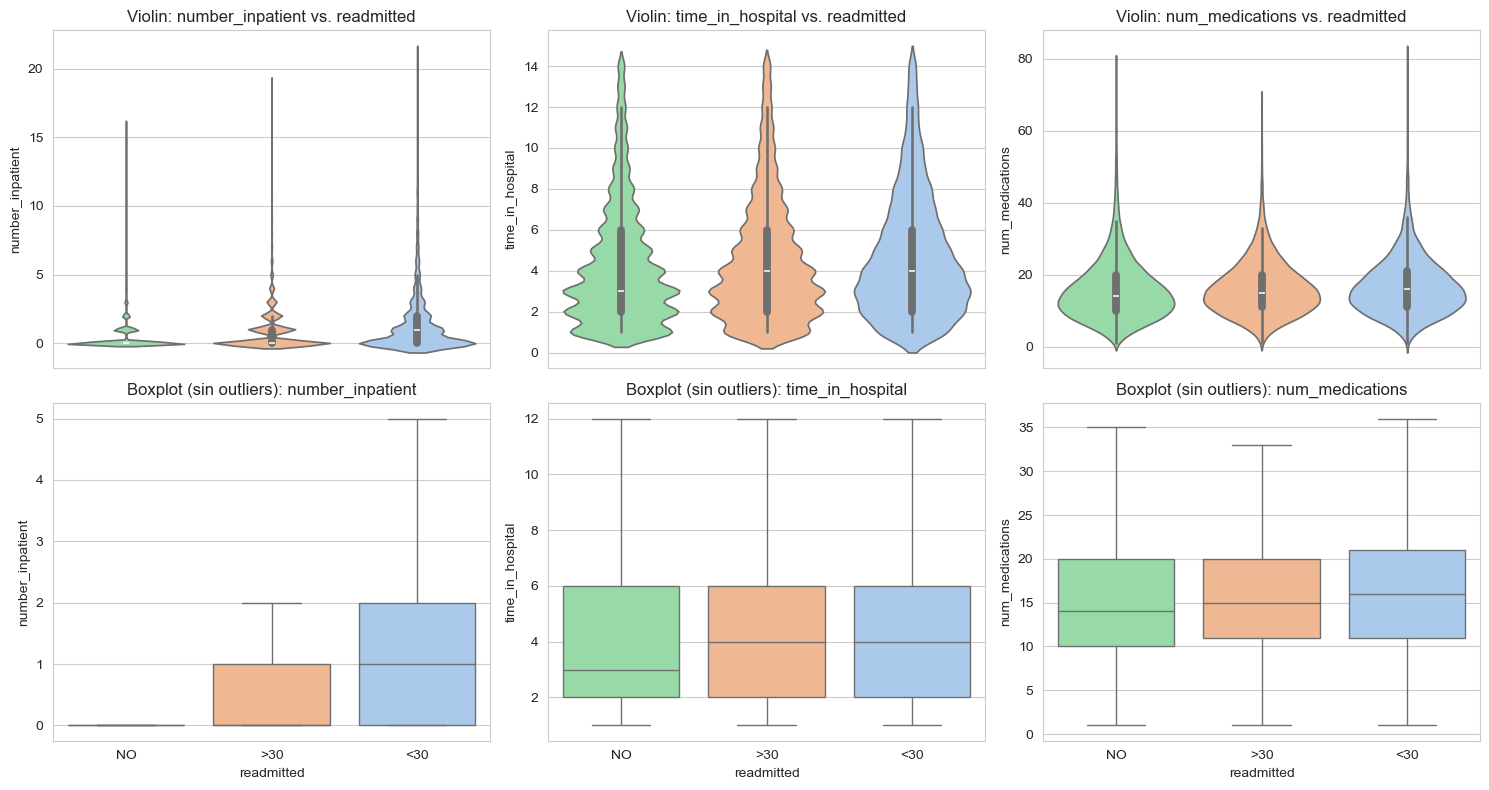

In [36]:
vars_a_graficar = ["number_inpatient", "time_in_hospital", "num_medications"]

fig, axes = plt.subplots(2, len(vars_a_graficar), figsize=(15, 8), sharex="col")
for j, col in enumerate(vars_a_graficar):
    sns.violinplot(data=df_train, x="readmitted", y=col, hue="readmitted",
                   order=["NO", ">30", "<30"], palette="pastel", legend=False, ax=axes[0, j])
    axes[0, j].set_title(f"Violin: {col} vs. readmitted")
    sns.boxplot(data=df_train, x="readmitted", y=col, hue="readmitted",
                order=["NO", ">30", "<30"], palette="pastel", legend=False,
                showfliers=False, ax=axes[1, j])
    axes[1, j].set_title(f"Boxplot (sin outliers): {col}")
plt.tight_layout()
plt.show()

In [37]:
df_train = df_train.drop(columns=["_readmitted_bin_tmp"])

## 3.7 Correlación entre variables numéricas

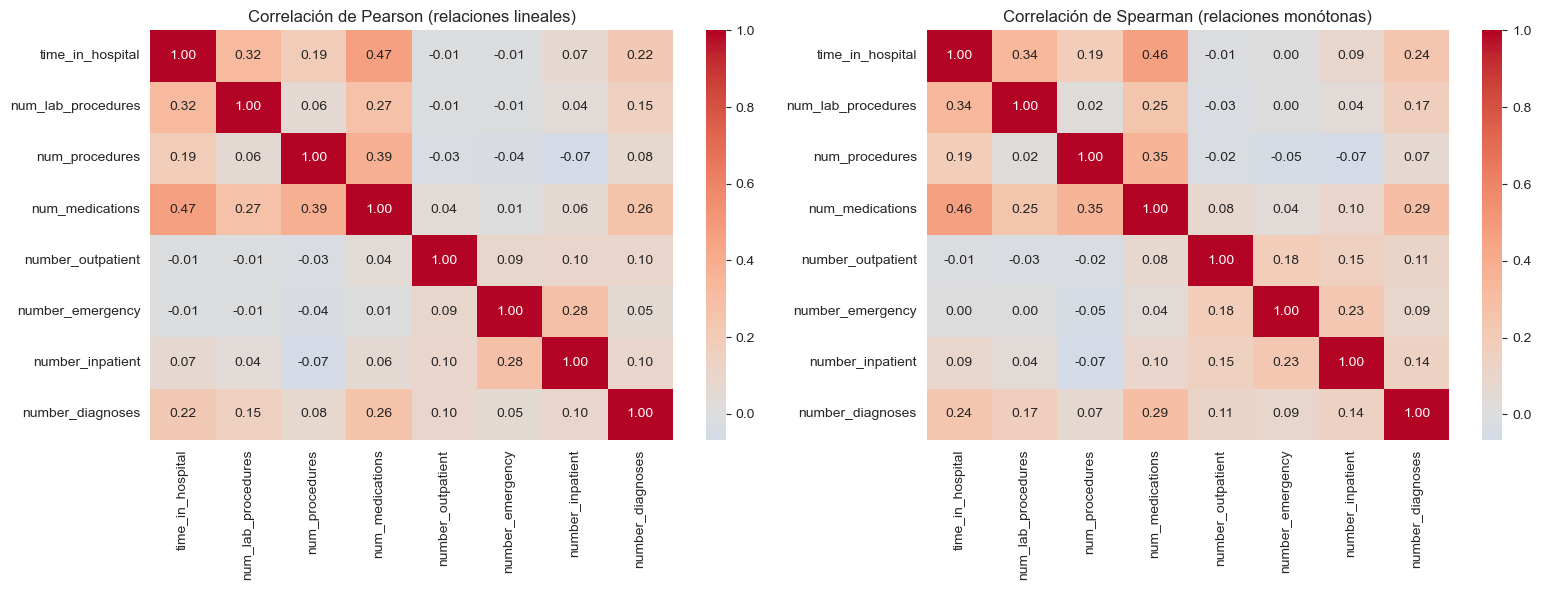

In [38]:
corr_pearson = df_train[cols_numericas].corr(method="pearson")
corr_spearman = df_train[cols_numericas].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlación de Pearson (relaciones lineales)")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlación de Spearman (relaciones monótonas)")
plt.tight_layout()
plt.show()

Se usan ambos coeficientes porque Pearson sólo capta relaciones lineales y varias de
estas variables (conteos muy asimétricos) tienen relaciones monótonas no lineales. En general las
correlaciones son bajas-moderadas —no hay multicolinealidad fuerte—, salvo relaciones moderadas
esperables entre `num_medications` y `time_in_hospital`, `num_procedures` y `num_lab_procedures`.

**Interpretación consolidada de la sección 3:** el reingreso temprano es un fenómeno
**multifactorial** —ninguna variable aislada lo explica con fuerza—, donde
`discharge_disposition_id` y el historial reciente de internaciones/urgencias
(`number_inpatient`, `number_emergency`) son las señales individuales más fuertes. Esto valida el
planteo de la sección 2: hace falta un modelo multivariado, no una regla simple sobre una sola
variable.

# 4. Preprocesamiento y limpieza

La limpieza general (eliminación de `gender` inválido) ya se hizo en 1.6, porque define el
universo del estudio y tenía que preceder al split. Queda el tratamiento de faltantes y de
outliers.

A partir de acá, **todo estadístico que se calcule sobre los datos** (moda para imputar, umbral de
winsorización, media/desvío de escalado) se obtiene **únicamente del conjunto de entrenamiento** y
se aplica igual sobre train y test.

## 4.1 Tratamiento de valores faltantes

Se decide qué hacer con cada variable identificada en 1.3. Para `race` —la única imputación que
depende de un estadístico calculado sobre los datos (la moda)— se usa **únicamente la moda de
train**, aplicada igual sobre ambas particiones.

In [39]:
# --- weight: se elimina la columna (97% vacía = no aporta información explotable) ---
data_set = data_set.drop(columns=["weight"])

# --- max_glu_serum / A1Cresult: el faltante ES informacion (no se pidio el analisis).
#     Se agrega la categoria "No medido" (regla fija, no depende de train/test) ---
for c in ["max_glu_serum", "A1Cresult"]:
    data_set[c] = data_set[c].cat.add_categories(["No medido"]).fillna("No medido")
    orden_nuevo = ["No medido"] + [cat for cat in data_set[c].cat.categories if cat != "No medido"]
    data_set[c] = data_set[c].cat.reorder_categories(orden_nuevo, ordered=True)

# --- medical_specialty / payer_code: alta cardinalidad + muchos NaN -> categoria "Faltante" ---
for c in ["medical_specialty", "payer_code"]:
    data_set[c] = data_set[c].astype("object").fillna("Faltante").astype("category")

# --- race: baja proporcion de nulos, categorica nominal -> imputar con la MODA DE TRAIN ---
moda_race = data_set.loc[data_set["_es_train"], "race"].mode()[0]
data_set["race"] = data_set["race"].astype("object").fillna(moda_race).astype("category")
print("Moda de 'race' calculada SOLO con train:", moda_race)

# --- diag_1/2/3: muy pocos nulos -> categoria "Sin_diagnostico" (regla fija) ---
for c in ["diag_1", "diag_2", "diag_3"]:
    data_set[c] = data_set[c].astype("object").fillna("Sin_diagnostico").astype("category")

print("\nNulos restantes:", int(data_set.isnull().sum().sum()))
print("Nueva forma del dataset:", data_set.shape)

Moda de 'race' calculada SOLO con train: Caucasian

Nulos restantes: 0
Nueva forma del dataset: (101763, 51)


**Justificación general:** para variables numéricas se hubiera usado media/mediana según la
simetría de la distribución, pero en este dataset **todos los faltantes son categóricos**. Por eso
se optó por: (a) eliminar la columna cuando la pérdida de información es casi total (`weight`), o
(b) crear una categoría explícita de "faltante/no medido" cuando el hecho de que falte el dato es
en sí mismo informativo (que no se haya pedido A1C), evitando el sesgo de imputar con la moda en
variables de alta cardinalidad. La única imputación que usa un estadístico (`race`) se calculó
exclusivamente con train.

## 4.2 Detección y manejo de outliers

Siguiendo lo identificado en 3.2: no se eliminan outliers (son pacientes clínicamente relevantes),
pero se aplica **winsorización suave al percentil 99, calculado sólo con train**, para evitar que
valores extremos aislados distorsionen el escalado.

Nota de alcance: `number_emergency` y `number_inpatient` van además a discretizarse en 5.1 en
buckets `0/1/2/3 o más`, y son las versiones discretizadas las que entran al modelo. Para esas dos
la winsorización no tiene efecto sobre las features finales; sí lo tiene sobre
`num_lab_procedures` y `num_medications`, que entran al modelo como numéricas.

In [40]:
cols_winsor = ["num_lab_procedures", "number_emergency", "number_inpatient", "num_medications"]
for col in cols_winsor:
    p99 = data_set.loc[data_set["_es_train"], col].quantile(0.99)
    data_set[col] = np.where(data_set[col] > p99, p99, data_set[col])
    print(f"{col:22s} umbral p99 (train) = {p99}")

data_set[cols_winsor].describe().round(2)

num_lab_procedures     umbral p99 (train) = 85.0
number_emergency       umbral p99 (train) = 3.0
number_inpatient       umbral p99 (train) = 6.0
num_medications        umbral p99 (train) = 43.0


,num_lab_procedures,number_emergency,number_inpatient,num_medications
count,101763.00,101763.00,101763.00,101763.00
mean,43.04,0.16,0.62,15.94
std,19.53,0.53,1.14,7.80
min,1.00,0.00,0.00,1.00
25%,31.00,0.00,0.00,10.00
50%,44.00,0.00,0.00,15.00
75%,57.00,0.00,1.00,20.00
max,85.00,3.00,6.00,43.00


#### Alternativa considerada: transformación logarítmica

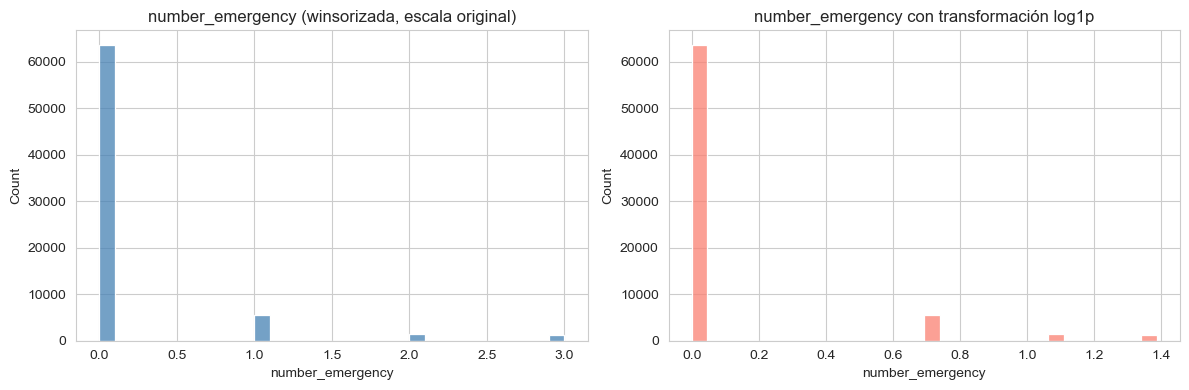

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data_set.loc[data_set["_es_train"], "number_emergency"], bins=30,
             ax=axes[0], color="steelblue")
axes[0].set_title("number_emergency (winsorizada, escala original)")
sns.histplot(np.log1p(data_set.loc[data_set["_es_train"], "number_emergency"]), bins=30,
             ax=axes[1], color="salmon")
axes[1].set_title("number_emergency con transformación log1p")
plt.tight_layout()
plt.show()

La transformación logarítmica comprime la cola, pero se **descarta**: (1) más del 90%
de los valores son 0, y `log1p` los sigue dejando en 0; (2) para los modelos candidatos la escala
no es tan crítica como para justificar la pérdida de interpretabilidad directa. Se mantiene la
winsorización y, en 5.1, la discretización.

# 5. Feature engineering

## 5.1 Nuevos features

### `patient_nbr_ordinal`: cantidad de encuentros previos por paciente

`patient_nbr` es un identificador sin orden real, así que no se usa directamente. En cambio se
deriva una variable con sentido clínico: la **cantidad de encuentros (internaciones) PREVIOS** que tuvo cada
paciente antes de la fila actual.

**Justificación:** un paciente con varios encuentros previos es, a priori, de mayor
complejidad/riesgo. Es importante contar sólo encuentros *previos* (no el total del paciente en
todo el dataset): usar el total incluiría encuentros *futuros* respecto de la fila actual, lo que
sería fuga temporal. Se usa `encounter_id` (estrictamente creciente dentro de cada paciente) como
proxy cronológico. El cálculo es **local a cada paciente**, y cada paciente cae entero en train o
en test (sección 2.2), así que no cruza información entre particiones.

In [42]:
data_set = data_set.sort_values(["patient_nbr", "encounter_id"]).reset_index(drop=True)
data_set["num_encuentros_previos"] = data_set.groupby("patient_nbr").cumcount()

def bucketizar(x):
    return str(x) if x <= 4 else "5 o mas"

orden_pnbr = ["0", "1", "2", "3", "4", "5 o mas"]
data_set["patient_nbr_ordinal"] = pd.Categorical(
    data_set["num_encuentros_previos"].apply(bucketizar), categories=orden_pnbr, ordered=True
)
data_set["patient_nbr_ordinal"].value_counts(normalize=True).reindex(orden_pnbr).mul(100).round(2)

patient_nbr_ordinal
0          70.28
1          16.48
2           6.23
3           2.96
4           1.56
5 o mas     2.49
Name: proportion, dtype: float64

### Familias farmacológicas

Las 23 columnas de medicamentos son difíciles de analizar por separado: la mayoría tiene muy poca
variabilidad. **Justificación:** se agrupan por familia farmacológica (clasificación médica
estándar) y se colapsa cada familia en una sola variable con la misma escala original (`No`,
`Steady`, `Up`, `Down`), pasando de 23 columnas dispersas a 6 variables manejables.

| Familia | Columnas que la integran |
|---|---|
| Biguanidas | `metformin` |
| Sulfonilureas | `chlorpropamide`, `glimepiride`, `acetohexamide`, `glipizide`, `glyburide`, `tolbutamide`, `tolazamide` |
| Meglitinidas | `repaglinide`, `nateglinide` |
| Glitazonas | `pioglitazone`, `rosiglitazone`, `troglitazone` |
| Alfa-glucosidasa | `acarbose`, `miglitol` |
| Insulina | `insulin` |

Las combinaciones de dos drogas aportan a las dos familias que combinan. `examide` y `citoglipton`
se excluyen (varianza cero). Cuando una familia tiene más de una droga informada para el mismo
paciente, se toma el estado de mayor intensidad (`Up > Down > Steady > No`).

In [43]:
mapa_familias = {
    "metformin": ["Biguanidas"], "repaglinide": ["Meglitinidas"], "nateglinide": ["Meglitinidas"],
    "chlorpropamide": ["Sulfonilureas"], "glimepiride": ["Sulfonilureas"], "acetohexamide": ["Sulfonilureas"],
    "glipizide": ["Sulfonilureas"], "glyburide": ["Sulfonilureas"], "tolbutamide": ["Sulfonilureas"],
    "pioglitazone": ["Glitazonas"], "rosiglitazone": ["Glitazonas"], "acarbose": ["Alfa_glucosidasa"],
    "miglitol": ["Alfa_glucosidasa"], "troglitazone": ["Glitazonas"], "tolazamide": ["Sulfonilureas"],
    "examide": [], "citoglipton": [], "insulin": ["Insulina"],
    "glyburide-metformin": ["Sulfonilureas", "Biguanidas"], "glipizide-metformin": ["Sulfonilureas", "Biguanidas"],
    "glimepiride-pioglitazone": ["Sulfonilureas", "Glitazonas"], "metformin-rosiglitazone": ["Biguanidas", "Glitazonas"],
    "metformin-pioglitazone": ["Biguanidas", "Glitazonas"],
}
familias = ["Biguanidas", "Sulfonilureas", "Meglitinidas", "Glitazonas", "Alfa_glucosidasa", "Insulina"]
prioridad = {"Up": 3, "Down": 2, "Steady": 1, "No": 0}

for familia in familias:
    cols_familia = [droga for droga, fams in mapa_familias.items() if familia in fams]
    nombre_col = f"familia_{familia.lower()}"
    data_set[nombre_col] = pd.Categorical(
        data_set[cols_familia].apply(lambda fila: max(fila, key=lambda v: prioridad.get(v, 0)), axis=1)
    )

cols_familias_nuevas = [f"familia_{f.lower()}" for f in familias]
resumen_familias = pd.DataFrame(
    {col: data_set[col].value_counts(normalize=True).round(3) for col in cols_familias_nuevas}
).fillna(0).T.reindex(columns=["No", "Steady", "Up", "Down"]).fillna(0)
resumen_familias

,No,Steady,Up,Down
familia_biguanidas,0.797,0.187,0.011,0.006
familia_sulfonilureas,0.716,0.253,0.019,0.013
familia_meglitinidas,0.978,0.020,0.001,0.001
familia_glitazonas,0.866,0.128,0.004,0.002
familia_alfa_glucosidasa,0.997,0.003,0.000,0.000
familia_insulina,0.466,0.303,0.111,0.120


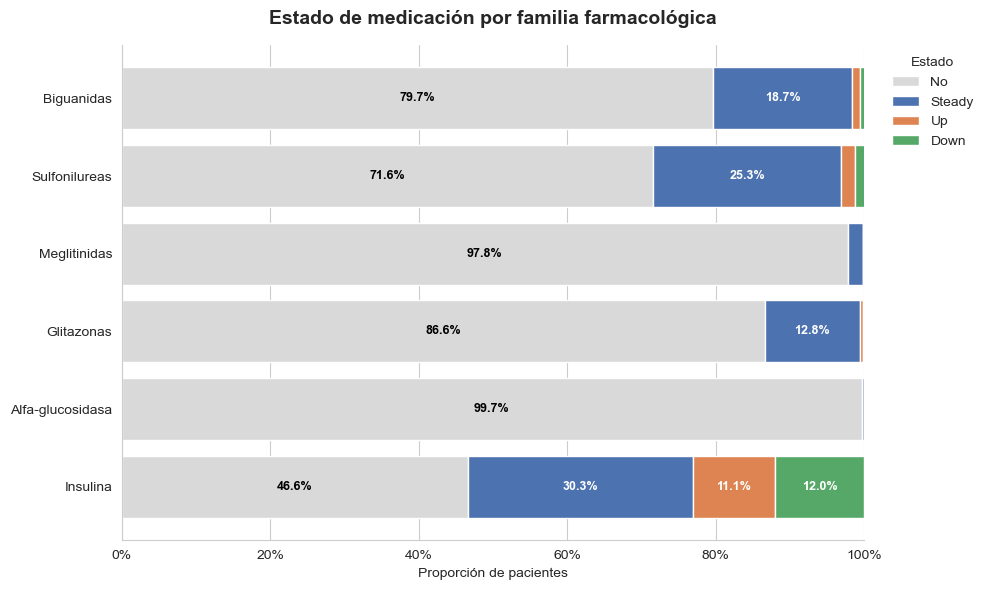

In [44]:
etiquetas_familias = {"familia_biguanidas": "Biguanidas", "familia_sulfonilureas": "Sulfonilureas",
                      "familia_meglitinidas": "Meglitinidas", "familia_glitazonas": "Glitazonas",
                      "familia_alfa_glucosidasa": "Alfa-glucosidasa", "familia_insulina": "Insulina"}
resumen_grafico = resumen_familias.rename(index=etiquetas_familias)
colores_estado = {"No": "#d9d9d9", "Steady": "#4C72B0", "Up": "#DD8452", "Down": "#55A868"}

fig, ax = plt.subplots(figsize=(10, 6))
izquierda = pd.Series(0.0, index=resumen_grafico.index)
for estado in ["No", "Steady", "Up", "Down"]:
    valores = resumen_grafico[estado]
    ax.barh(resumen_grafico.index, valores, left=izquierda, color=colores_estado[estado],
            label=estado, edgecolor="white")
    for i, (v, l) in enumerate(zip(valores, izquierda)):
        if v > 0.02:
            ax.text(l + v / 2, i, f"{v * 100:.1f}%", ha="center", va="center", fontsize=9,
                    color="white" if estado != "No" else "black", fontweight="bold")
    izquierda = izquierda + valores

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Proporción de pacientes")
ax.set_title("Estado de medicación por familia farmacológica", fontsize=14, fontweight="bold", pad=15)
ax.legend(title="Estado", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.invert_yaxis()
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

### Discretización de `number_emergency` / `number_inpatient`

**Justificación:** en 3.2 se vio que estas dos
variables tienen tanta masa puntual en 0 que el criterio IQR marca como "outlier" a cualquier valor
positivo. Ni la winsorización ni el `log1p` resuelven del todo el problema. La técnica más
apropiada es discretizarlas en una categórica ordinal con bins clínicos: `"0"`, `"1"`, `"2"`,
`"3 o más"`.

Los puntos de corte se definen **por criterio clínico, no por un cuantil calculado sobre los
datos**, así que no dependen de la partición. Esto es deliberado: usar cuantiles habría exigido
calcularlos sólo con train, agregando una dependencia innecesaria.

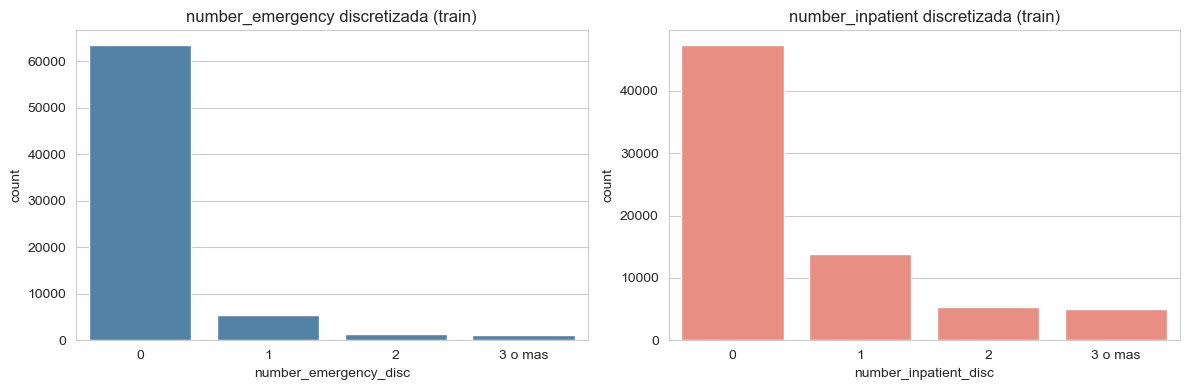

In [45]:
def discretizar_conteo(serie):
    def bin_conteo(x):
        if x == 0: return "0"
        elif x == 1: return "1"
        elif x == 2: return "2"
        else: return "3 o mas"
    return pd.Categorical(serie.apply(bin_conteo), categories=["0", "1", "2", "3 o mas"], ordered=True)

data_set["number_emergency_disc"] = discretizar_conteo(data_set["number_emergency"])
data_set["number_inpatient_disc"] = discretizar_conteo(data_set["number_inpatient"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=data_set.loc[data_set["_es_train"], "number_emergency_disc"],
              order=["0", "1", "2", "3 o mas"], ax=axes[0], color="steelblue")
axes[0].set_title("number_emergency discretizada (train)")
sns.countplot(x=data_set.loc[data_set["_es_train"], "number_inpatient_disc"],
              order=["0", "1", "2", "3 o mas"], ax=axes[1], color="salmon")
axes[1].set_title("number_inpatient discretizada (train)")
plt.tight_layout()
plt.show()

## 5.2 Separación de features (X) y target (y)

Se separan features y target reutilizando el split de la sección 2.2. **Todavía no se codifica
nada**: la codificación se aplica recién en la sección 7, y sólo sobre las variables que
sobrevivan a la selección de la sección 6.

In [46]:
id_cols = ["encounter_id", "patient_nbr"]
target_col = "readmitted_temprano"
cols_droga_individual = list(mapa_familias.keys())
drop_cols = id_cols + ["readmitted", target_col, "_es_train", "num_encuentros_previos"] + cols_droga_individual

X = data_set.drop(columns=drop_cols)
y = data_set[target_col]

mask_train = data_set["_es_train"].to_numpy()
X_train = X.loc[mask_train].reset_index(drop=True)
X_test = X.loc[~mask_train].reset_index(drop=True)
y_train_final = y.loc[mask_train].reset_index(drop=True)
y_test_final = y.loc[~mask_train].reset_index(drop=True)
y_train, y_test = y_train_final, y_test_final
grupos_train = data_set.loc[data_set["_es_train"], "patient_nbr"].reset_index(drop=True)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Proporción de clase positiva - train:", round(float(y_train_final.mean()), 3),
      " test:", round(float(y_test_final.mean()), 3))
print("\nVariables candidatas (sin codificar):", X_train.shape[1])

Train: (71583, 32)  Test: (30180, 32)
Proporción de clase positiva - train: 0.113  test: 0.109

Variables candidatas (sin codificar): 32


# 6. Reducción de dimensionalidad — selección de variables

**Momento del pipeline: después del split, antes de la codificación.** Es un criterio explícito de
la cátedra y tiene tres consecuencias metodológicas concretas:

1. **Chi² se calcula como corresponde.** Su definición es sobre una **tabla de contingencia** entre
   dos variables categóricas. Aplicado después del encoding termina corriendo
   sobre columnas de target encoding que son probabilidades en [0,1] — como "frecuencia", un valor
   de 0.13 no significa nada y el estadístico resultante no es interpretable. Sobre las variables
   originales, Chi² recupera su sentido estadístico.
2. **Se descartan variables, no columnas sueltas.** Seleccionar sobre la matriz codificada lleva a
   resultados incoherentes: quedarse con `payer_code_MC` y `payer_code_BC` pero descartar las otras
   16 dummies de la misma variable no es una decisión interpretable — no se puede explicar
   clínicamente ni implementar en producción (habría que pedir el dato completo igual). Acá la
   unidad de decisión es la variable.
3. **Se paga en granularidad.** Es el costo aceptado: si una variable tiene una sola categoría muy
   predictiva pero el resto es ruido, la medida agregada la puede subestimar y la variable entera
   cae. A cambio se gana un modelo con menos variables, más simple de explicar.

**Qué medida corresponde a cada tipo** — esto es lo que obliga a hacerlo antes de codificar, porque
después del one-hot todas las columnas parecen numéricas y la distinción se pierde:

| Criterio | Se aplica a | Qué mide |
|---|---|---|
| **ANOVA F** (`f_classif`) | numéricas | Si la media de la variable difiere entre las clases del target |
| **Chi²** (`chi2_contingency`) | categóricas | Dependencia entre la variable y el target en la tabla de contingencia |
| **Información mutua** (`mutual_info_classif`) | **ambas** | Reducción de incertidumbre sobre el target; no asume forma de relación |

La información mutua es el único criterio que cruza los dos tipos, así que además de aportar su
propio ranking sirve como **denominador común** para comparar una numérica contra una categórica —
y como criterio de desempate cuando dos variables resultan redundantes entre sí (sección 6.2).

In [47]:
num_orig = [c for c in cols_numericas if c in X_train.columns]
cat_orig = [c for c in X_train.columns if str(X_train[c].dtype) == "category"]

print(f"Variables numéricas  ({len(num_orig)}): {num_orig}")
print()
print(f"Variables categóricas ({len(cat_orig)}):")
for c in cat_orig:
    print(f"   {c:26s} {X_train[c].nunique():3d} categorías")
print(f"\nTotal de variables candidatas: {len(num_orig) + len(cat_orig)}")

Variables numéricas  (8): ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Variables categóricas (24):
   race                         5 categorías
   gender                       2 categorías
   age                         10 categorías
   admission_type_id            8 categorías
   discharge_disposition_id    26 categorías
   admission_source_id         16 categorías
   payer_code                  18 categorías
   medical_specialty           70 categorías
   diag_1                      11 categorías
   diag_2                      12 categorías
   diag_3                      12 categorías
   max_glu_serum                4 categorías
   A1Cresult                    4 categorías
   change                       2 categorías
   diabetesMed                  2 categorías
   patient_nbr_ordinal          6 categorías
   familia_biguanidas           4 categorías
   familia_sulfonil

## 6.1 Relevancia contra el target

### 6.1.1 ANOVA F — variables numéricas

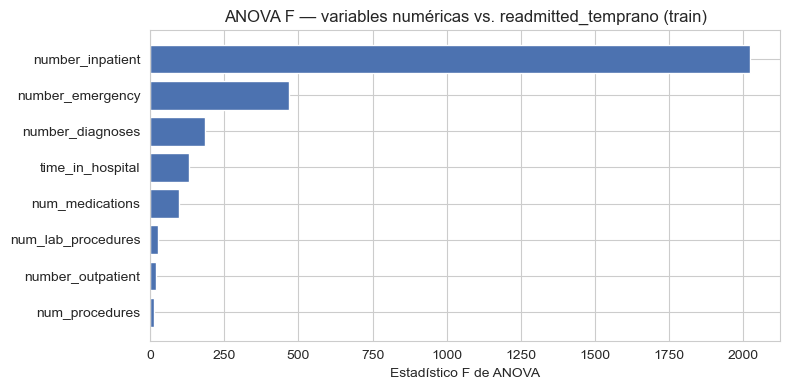

,variable,F,p_valor
0,number_inpatient,2023.4196,0.0000
1,number_emergency,469.1225,0.0000
2,number_diagnoses,184.2502,0.0000
3,time_in_hospital,129.7892,0.0000
4,num_medications,98.0593,0.0000
5,num_lab_procedures,26.0042,0.0000
6,number_outpatient,19.8910,0.0000
7,num_procedures,12.9887,0.0003


In [48]:
f_stat, p_val = f_classif(X_train[num_orig], y_train_final)
anova_df = (pd.DataFrame({"variable": num_orig, "F": f_stat, "p_valor": p_val})
            .sort_values("F", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(anova_df["variable"][::-1], anova_df["F"][::-1], color="#4C72B0")
ax.set_xlabel("Estadístico F de ANOVA")
ax.set_title("ANOVA F — variables numéricas vs. readmitted_temprano (train)")
plt.tight_layout()
plt.show()
anova_df.round(4)

`number_inpatient` domina ampliamente. Con 71.583 observaciones casi todos los
p-valores dan significativos, así que **el p-valor no sirve para ordenar**: lo que discrimina es la
magnitud del estadístico F. Es el mismo fenómeno que se vio en 3.6 con Chi²: con muestras grandes,
significancia estadística y relevancia práctica son cosas distintas.

### 6.1.2 Chi² — variables categóricas

Se calcula sobre la **tabla de contingencia** de cada variable contra el target. Se reporta también
la **V de Cramér**, que es el estadístico Chi² normalizado por el tamaño muestral y por la
cardinalidad: el Chi² crudo crece con el número de categorías, así que comparar directamente el
Chi² de `medical_specialty` (70 categorías) contra el de `gender` (2) favorecería a la primera por
un motivo puramente aritmético. **La V de Cramér es la que se usa para rankear**; el Chi² y su
p-valor quedan como el test de independencia propiamente dicho.

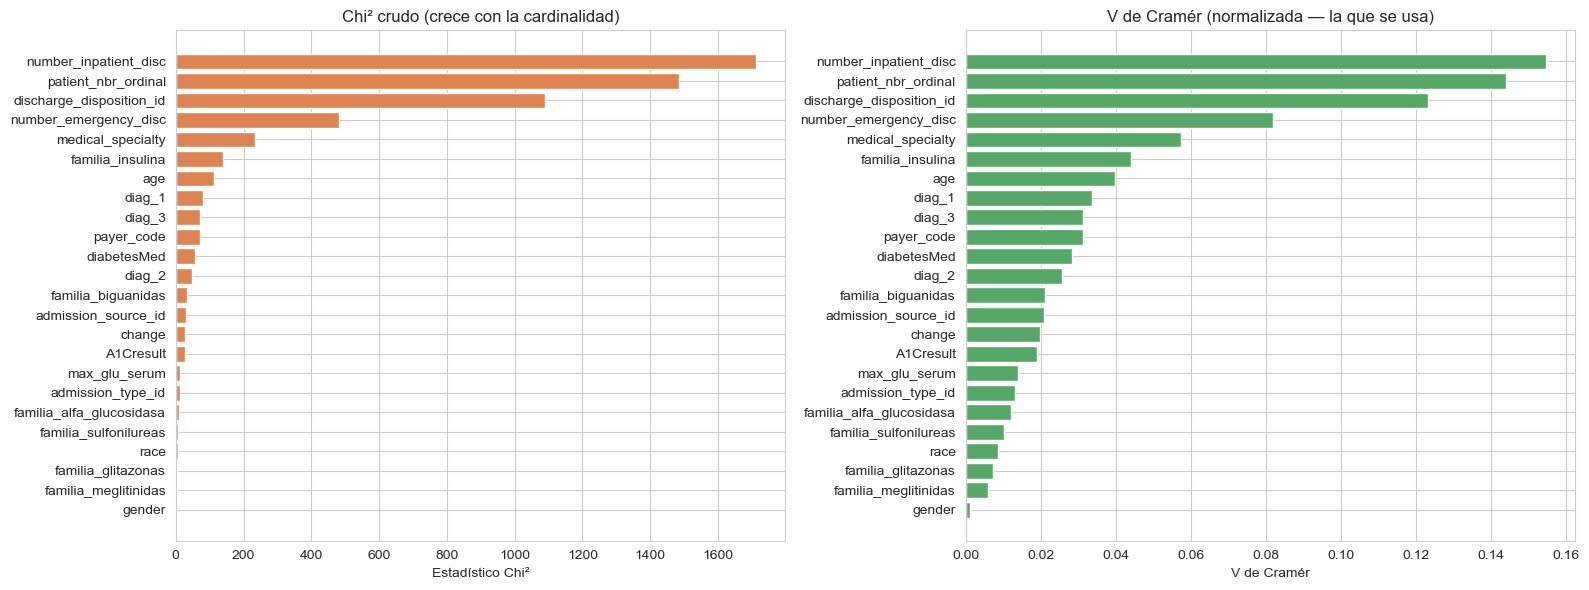

,variable,n_categorias,chi2,p_valor,V_de_Cramer
0,number_inpatient_disc,4,1711.2788,0.0000,0.1546
1,patient_nbr_ordinal,6,1485.9946,0.0000,0.1441
2,discharge_disposition_id,26,1088.9749,0.0000,0.1233
3,number_emergency_disc,4,481.0019,0.0000,0.0820
4,medical_specialty,70,235.0779,0.0000,0.0573
5,familia_insulina,4,139.0819,0.0000,0.0441
6,age,10,113.4993,0.0000,0.0398
7,diag_1,11,80.7637,0.0000,0.0336
8,diag_3,12,70.7671,0.0000,0.0314
9,payer_code,18,70.3277,0.0000,0.0313


In [49]:
filas_chi2 = []
for c in cat_orig:
    tabla = pd.crosstab(X_train[c], y_train_final)
    chi2_stat, p, dof, _ = chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2_stat / (n * k)) if k > 0 else np.nan
    filas_chi2.append([c, X_train[c].nunique(), chi2_stat, p, v])

chi2_df = (pd.DataFrame(filas_chi2, columns=["variable", "n_categorias", "chi2", "p_valor", "V_de_Cramer"])
           .sort_values("V_de_Cramer", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(chi2_df["variable"][::-1], chi2_df["chi2"][::-1], color="#DD8452")
axes[0].set_xlabel("Estadístico Chi²"); axes[0].set_title("Chi² crudo (crece con la cardinalidad)")
axes[1].barh(chi2_df["variable"][::-1], chi2_df["V_de_Cramer"][::-1], color="#55A868")
axes[1].set_xlabel("V de Cramér"); axes[1].set_title("V de Cramér (normalizada — la que se usa)")
plt.tight_layout()
plt.show()
chi2_df.round(4)

La comparación de los dos gráficos muestra por qué hace falta normalizar.
`medical_specialty` y los `diag_*` suben en el Chi² crudo por tener muchas categorías, pero al
normalizar caen y `discharge_disposition_id` queda al frente con claridad. Todos los p-valores son
esencialmente 0, otra vez por el tamaño muestral.

### 6.1.3 Información mutua — todas las variables

Único criterio que aplica a los dos tipos a la vez. Se le indica cuáles variables son discretas
(las categóricas, pasadas a códigos enteros) para que use el estimador correcto en cada caso.

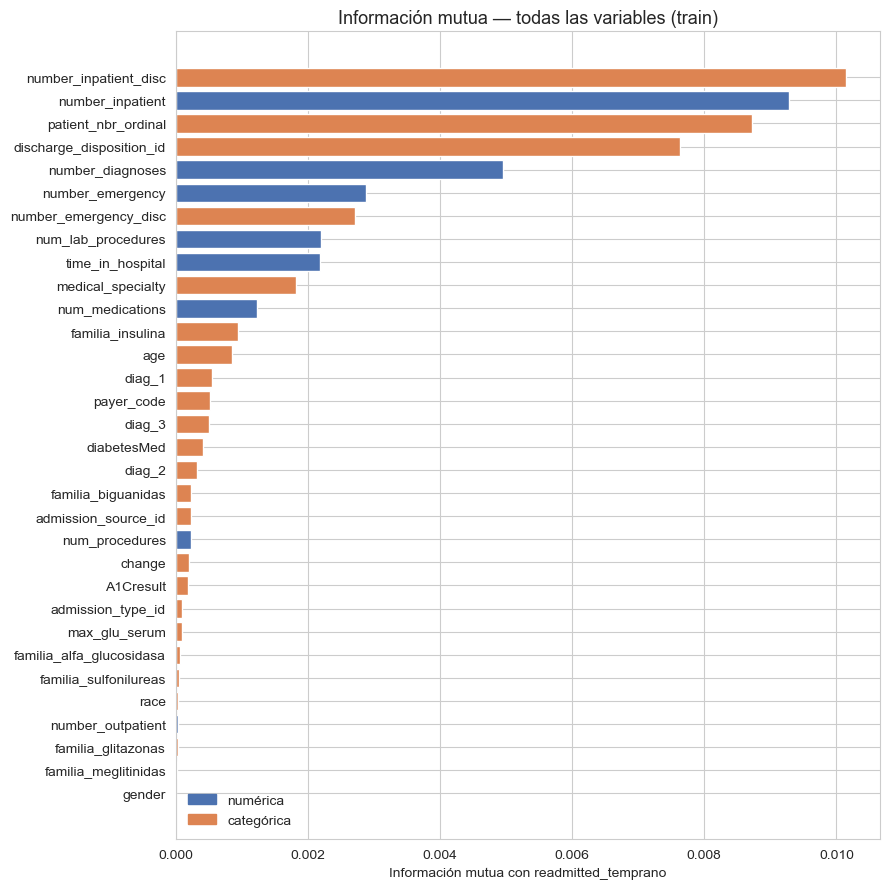

,variable,informacion_mutua,tipo
0,number_inpatient_disc,0.01015,categórica
1,number_inpatient,0.00929,numérica
2,patient_nbr_ordinal,0.00873,categórica
3,discharge_disposition_id,0.00763,categórica
4,number_diagnoses,0.00495,numérica
5,number_emergency,0.00287,numérica
6,number_emergency_disc,0.00271,categórica
7,num_lab_procedures,0.00221,numérica
8,time_in_hospital,0.00219,numérica
9,medical_specialty,0.00182,categórica


In [50]:
vars_mi = num_orig + cat_orig
X_mi = pd.DataFrame(index=X_train.index)
es_discreta_orig = []
for c in vars_mi:
    if c in cat_orig:
        X_mi[c] = X_train[c].cat.codes.astype(int)
        es_discreta_orig.append(True)
    else:
        X_mi[c] = X_train[c].astype(float)
        es_discreta_orig.append(False)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mi_scores = mutual_info_classif(X_mi, y_train_final,
                                    discrete_features=np.array(es_discreta_orig),
                                    random_state=RANDOM_STATE)

mi_df = (pd.DataFrame({"variable": vars_mi, "informacion_mutua": mi_scores,
                       "tipo": ["categórica" if c in cat_orig else "numérica" for c in vars_mi]})
         .sort_values("informacion_mutua", ascending=False).reset_index(drop=True))

MI_POR_VARIABLE = dict(zip(mi_df["variable"], mi_df["informacion_mutua"]))

fig, ax = plt.subplots(figsize=(9, 9))
colores = mi_df["tipo"].map({"numérica": "#4C72B0", "categórica": "#DD8452"})
ax.barh(mi_df["variable"][::-1], mi_df["informacion_mutua"][::-1], color=colores[::-1])
ax.set_xlabel("Información mutua con readmitted_temprano")
ax.set_title("Información mutua — todas las variables (train)", fontsize=13)
manijas = [plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#DD8452")]
ax.legend(manijas, ["numérica", "categórica"], frameon=False)
plt.tight_layout()
plt.show()
mi_df.head(15).round(5)

### 6.1.4 Tabla consolidada y criterio de descarte

Cada variable tiene **dos criterios aplicables**: la información mutua, y el que corresponde a su
tipo (ANOVA F si es numérica, V de Cramér si es categórica). Se convierten a **percentil dentro de
su grupo** para poder compararlos, donde 1.0 = la más relevante del grupo.

**Regla:** se descarta una variable sólo si queda en el **tercio inferior de los dos criterios a la
vez**. Es un criterio conservador a propósito — basta que un método la señale como relevante para
conservarla, porque cada uno tiene puntos ciegos distintos (ANOVA no capta relaciones no lineales,
la V de Cramér no aprovecha el orden de las ordinales, la información mutua es la más costosa de
estimar bien).

In [51]:
UMBRAL_PERCENTIL = 1 / 3

rel = pd.DataFrame({"variable": vars_mi})
rel["tipo"] = ["numérica" if c in num_orig else "categórica" for c in rel["variable"]]
rel["criterio_tipo"] = rel["variable"].map(
    {**dict(zip(anova_df["variable"], anova_df["F"])),
     **dict(zip(chi2_df["variable"], chi2_df["V_de_Cramer"]))})
rel["nombre_criterio"] = rel["tipo"].map({"numérica": "ANOVA F", "categórica": "V de Cramér"})
rel["info_mutua"] = rel["variable"].map(MI_POR_VARIABLE)

# percentil dentro del grupo de su tipo (1.0 = la mas relevante del grupo)
rel["pct_tipo"] = rel.groupby("tipo")["criterio_tipo"].rank(pct=True)
rel["pct_mi"] = rel.groupby("tipo")["info_mutua"].rank(pct=True)
rel["debil_en_ambos"] = (rel["pct_tipo"] <= UMBRAL_PERCENTIL) & (rel["pct_mi"] <= UMBRAL_PERCENTIL)

rel = rel.sort_values("pct_mi", ascending=False).reset_index(drop=True)
descartadas_relevancia = sorted(rel.loc[rel["debil_en_ambos"], "variable"])

print(f"Variables débiles en ambos criterios ({len(descartadas_relevancia)}):")
for v in descartadas_relevancia:
    fila = rel[rel["variable"] == v].iloc[0]
    print(f"  {v:26s} pct({fila['nombre_criterio']})={fila['pct_tipo']:.2f}  pct(MI)={fila['pct_mi']:.2f}")

rel[["variable", "tipo", "nombre_criterio", "criterio_tipo", "info_mutua",
     "pct_tipo", "pct_mi", "debil_en_ambos"]].round(4)

Variables débiles en ambos criterios (10):
  admission_type_id          pct(V de Cramér)=0.29  pct(MI)=0.33
  familia_alfa_glucosidasa   pct(V de Cramér)=0.25  pct(MI)=0.25
  familia_glitazonas         pct(V de Cramér)=0.12  pct(MI)=0.12
  familia_meglitinidas       pct(V de Cramér)=0.08  pct(MI)=0.08
  familia_sulfonilureas      pct(V de Cramér)=0.21  pct(MI)=0.21
  gender                     pct(V de Cramér)=0.04  pct(MI)=0.04
  max_glu_serum              pct(V de Cramér)=0.33  pct(MI)=0.29
  num_procedures             pct(ANOVA F)=0.12  pct(MI)=0.25
  number_outpatient          pct(ANOVA F)=0.25  pct(MI)=0.12
  race                       pct(V de Cramér)=0.17  pct(MI)=0.17


,variable,tipo,nombre_criterio,criterio_tipo,info_mutua,pct_tipo,pct_mi,debil_en_ambos
0,number_inpatient_disc,categórica,V de Cramér,0.1546,0.0102,1.0000,1.0000,False
1,number_inpatient,numérica,ANOVA F,2023.4196,0.0093,1.0000,1.0000,False
2,patient_nbr_ordinal,categórica,V de Cramér,0.1441,0.0087,0.9583,0.9583,False
3,discharge_disposition_id,categórica,V de Cramér,0.1233,0.0076,0.9167,0.9167,False
4,number_emergency_disc,categórica,V de Cramér,0.0820,0.0027,0.8750,0.8750,False
5,number_diagnoses,numérica,ANOVA F,184.2502,0.0049,0.7500,0.8750,False
6,medical_specialty,categórica,V de Cramér,0.0573,0.0018,0.8333,0.8333,False
7,familia_insulina,categórica,V de Cramér,0.0441,0.0009,0.7917,0.7917,False
8,age,categórica,V de Cramér,0.0398,0.0009,0.7500,0.7500,False
9,number_emergency,numérica,ANOVA F,469.1225,0.0029,0.8750,0.7500,False


#### Comparación normalizada de los tres métodos

Mismo formato que la comparación de métodos de selección de la Clase 6, con cada criterio
normalizado a [0, 1] para poder leerlos en una sola escala.Después del one-hot esa
distinción se pierde y todas las columnas parecen numéricas.

La información mutua es la única columna completa, y por eso es la que permite comparar una
numérica contra una categórica.

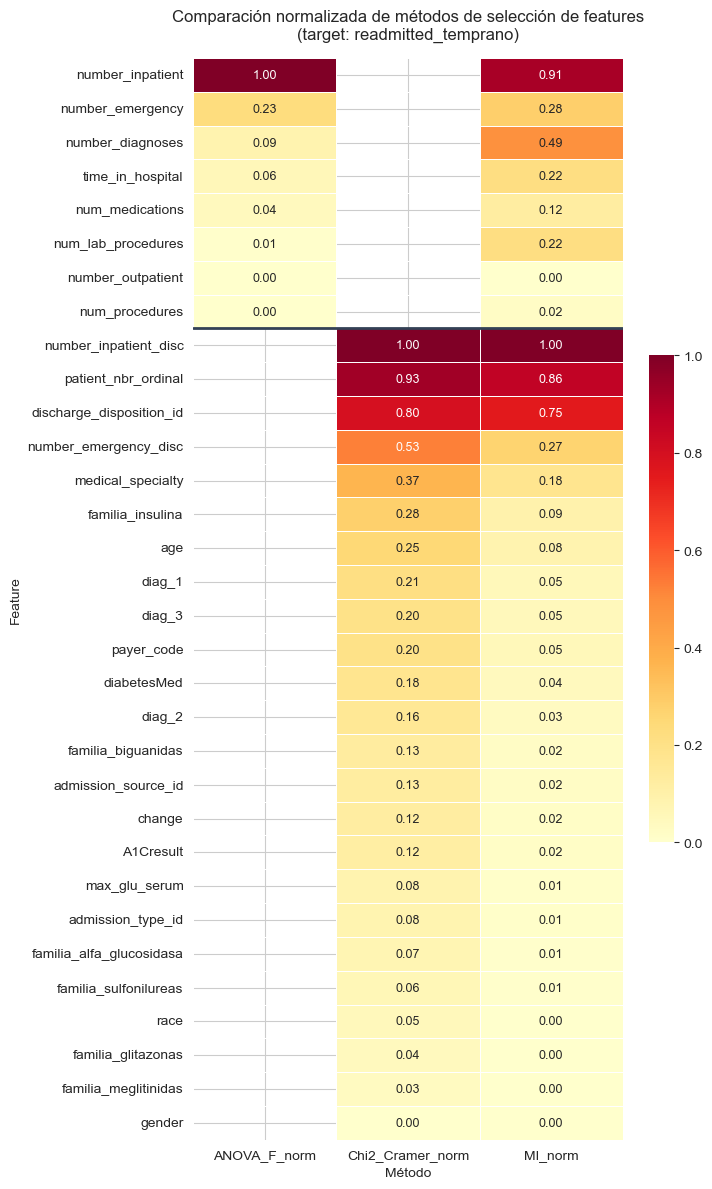

In [52]:
comp = rel.set_index("variable").copy()
es_num = comp["tipo"] == "numérica"

heat = pd.DataFrame(index=comp.index, dtype=float,
                    columns=["ANOVA_F_norm", "Chi2_Cramer_norm", "MI_norm"])
heat.loc[es_num, "ANOVA_F_norm"] = MinMaxScaler().fit_transform(
    comp.loc[es_num, ["criterio_tipo"]]).flatten()
heat.loc[~es_num, "Chi2_Cramer_norm"] = MinMaxScaler().fit_transform(
    comp.loc[~es_num, ["criterio_tipo"]]).flatten()
heat["MI_norm"] = MinMaxScaler().fit_transform(comp[["info_mutua"]]).flatten()

# Bloque de numericas arriba y de categoricas abajo, cada uno ordenado por su propio criterio
orden = (list(comp[es_num].sort_values("criterio_tipo", ascending=False).index)
         + list(comp[~es_num].sort_values("criterio_tipo", ascending=False).index))
heat = heat.loc[orden]

fig, ax = plt.subplots(figsize=(7.5, 12))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            linewidths=0.6, linecolor="white", annot_kws={"size": 9},
            cbar_kws={"shrink": 0.45}, ax=ax)
ax.axhline(int(es_num.sum()), color="#334155", lw=2)   # separa numericas de categoricas
ax.set_title("Comparación normalizada de métodos de selección de features\n"
             "(target: readmitted_temprano)", fontsize=12, pad=14)
ax.set_xlabel("Método"); ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

Las variables que encabezan los dos bloques son las mismas que lideran la
información mutua, así que los tres métodos coinciden en lo grueso. Donde discrepan es
informativo: una variable con ANOVA F alto pero información mutua baja tiene una relación
**lineal** con el target que la información mutua no premia especialmente, y a la inversa,
una con información mutua alta y criterio de tipo bajo sugiere una relación **no lineal o no
monótona** que ANOVA no captura. Por eso la regla de descarte exige que sea débil en los dos
a la vez, y no en uno solo.

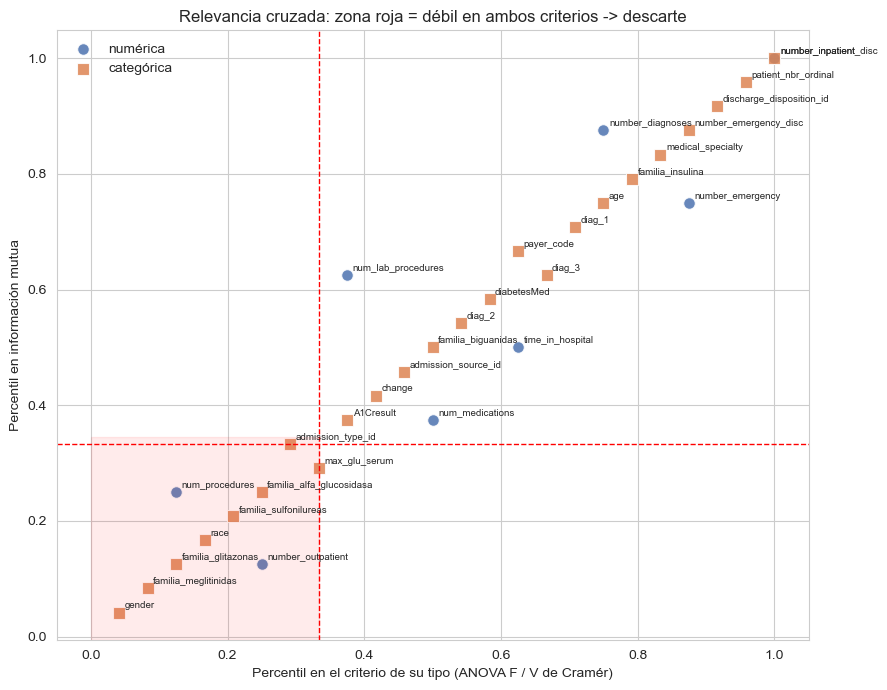

In [53]:
fig, ax = plt.subplots(figsize=(9, 7))
for tipo, marcador, color in [("numérica", "o", "#4C72B0"), ("categórica", "s", "#DD8452")]:
    sub = rel[rel["tipo"] == tipo]
    ax.scatter(sub["pct_tipo"], sub["pct_mi"], marker=marcador, s=70, color=color,
               label=tipo, alpha=0.85, edgecolor="white", linewidth=0.8)
for _, f in rel.iterrows():
    ax.annotate(f["variable"], (f["pct_tipo"], f["pct_mi"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.axvspan(0, UMBRAL_PERCENTIL, ymin=0, ymax=UMBRAL_PERCENTIL, color="red", alpha=0.08)
ax.axvline(UMBRAL_PERCENTIL, color="red", ls="--", lw=1)
ax.axhline(UMBRAL_PERCENTIL, color="red", ls="--", lw=1)
ax.set_xlabel("Percentil en el criterio de su tipo (ANOVA F / V de Cramér)")
ax.set_ylabel("Percentil en información mutua")
ax.set_title("Relevancia cruzada: zona roja = débil en ambos criterios -> descarte", fontsize=12)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

El gráfico hace visible el grado de acuerdo entre criterios. Los puntos alineados
sobre la diagonal son variables donde ambos métodos coinciden; los que se despegan son los casos
interesantes — típicamente variables con relación **no lineal** con el target, que la información
mutua detecta y ANOVA subestima. Sólo caen las que quedan en el cuadrante rojo inferior izquierdo.

## 6.2 Evaluación de relaciones entre variables (redundancia)

Ya medida la relevancia, se evalúa la redundancia **entre** features: dos variables muy asociadas
entre sí aportan información solapada, y conviene quedarse con una. La medida correcta depende otra
vez del par de tipos.

### 6.2.1 Numérica ↔ numérica: Pearson, Spearman y VIF

Se usan **los dos coeficientes** porque Pearson sólo capta relaciones lineales y varias de estas
variables son conteos muy asimétricos, donde la relación puede ser monótona pero no lineal.

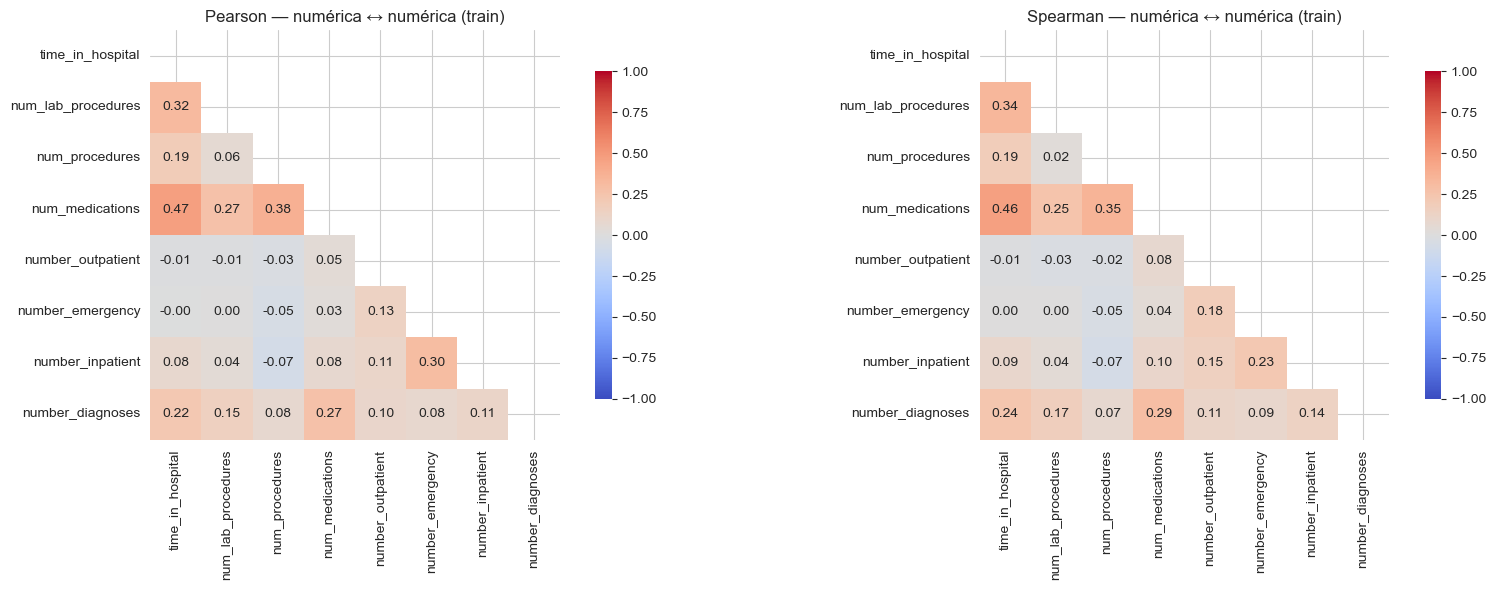

Máxima |Pearson|  entre numéricas: 0.470
Máxima |Spearman| entre numéricas: 0.465
Pares por encima del umbral de 0.7: 0


In [54]:
corr_p = X_train[num_orig].corr(method="pearson")
corr_s = X_train[num_orig].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
mask = np.triu(np.ones_like(corr_p, dtype=bool))
sns.heatmap(corr_p, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[0], cbar_kws={"shrink": .8})
axes[0].set_title("Pearson — numérica ↔ numérica (train)")
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title("Spearman — numérica ↔ numérica (train)")
plt.tight_layout()
plt.show()

UMBRAL_NUM = 0.7
maxp = corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool)).abs().max().max()
maxs = corr_s.where(np.triu(np.ones(corr_s.shape), k=1).astype(bool)).abs().max().max()
print(f"Máxima |Pearson|  entre numéricas: {maxp:.3f}")
print(f"Máxima |Spearman| entre numéricas: {maxs:.3f}")
print(f"Pares por encima del umbral de {UMBRAL_NUM}: "
      f"{int((corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool)).abs() >= UMBRAL_NUM).sum().sum())}")

La correlación de a pares no detecta la multicolinealidad **múltiple**: una variable puede ser
predecible a partir de la combinación de otras tres sin correlacionar fuerte con ninguna en
particular. El **VIF** sí lo detecta, porque regresa cada variable contra todas las demás. Regla
práctica: VIF > 5 sospechoso, VIF > 10 multicolinealidad seria.

In [55]:
X_vif = sm.add_constant(X_train[num_orig].astype(float))
vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.to_numpy(), i) for i in range(X_vif.shape[1])],
})
vif_df = vif_df[vif_df["variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
vif_df["diagnostico"] = pd.cut(vif_df["VIF"], bins=[0, 5, 10, np.inf],
                               labels=["OK", "sospechoso (>5)", "serio (>10)"])
vif_df.round(2)

,variable,VIF,diagnostico
0,num_medications,1.54,OK
1,time_in_hospital,1.37,OK
2,num_procedures,1.19,OK
3,num_lab_procedures,1.14,OK
4,number_inpatient,1.13,OK
5,number_emergency,1.12,OK
6,number_diagnoses,1.12,OK
7,number_outpatient,1.03,OK


### 6.2.2 Categórica ↔ categórica: V de Cramér

Para dos categóricas no aplica la correlación: la medida correcta es la **V de Cramér**, la misma
que se usó contra el target en 6.1.2, ahora entre pares de features.

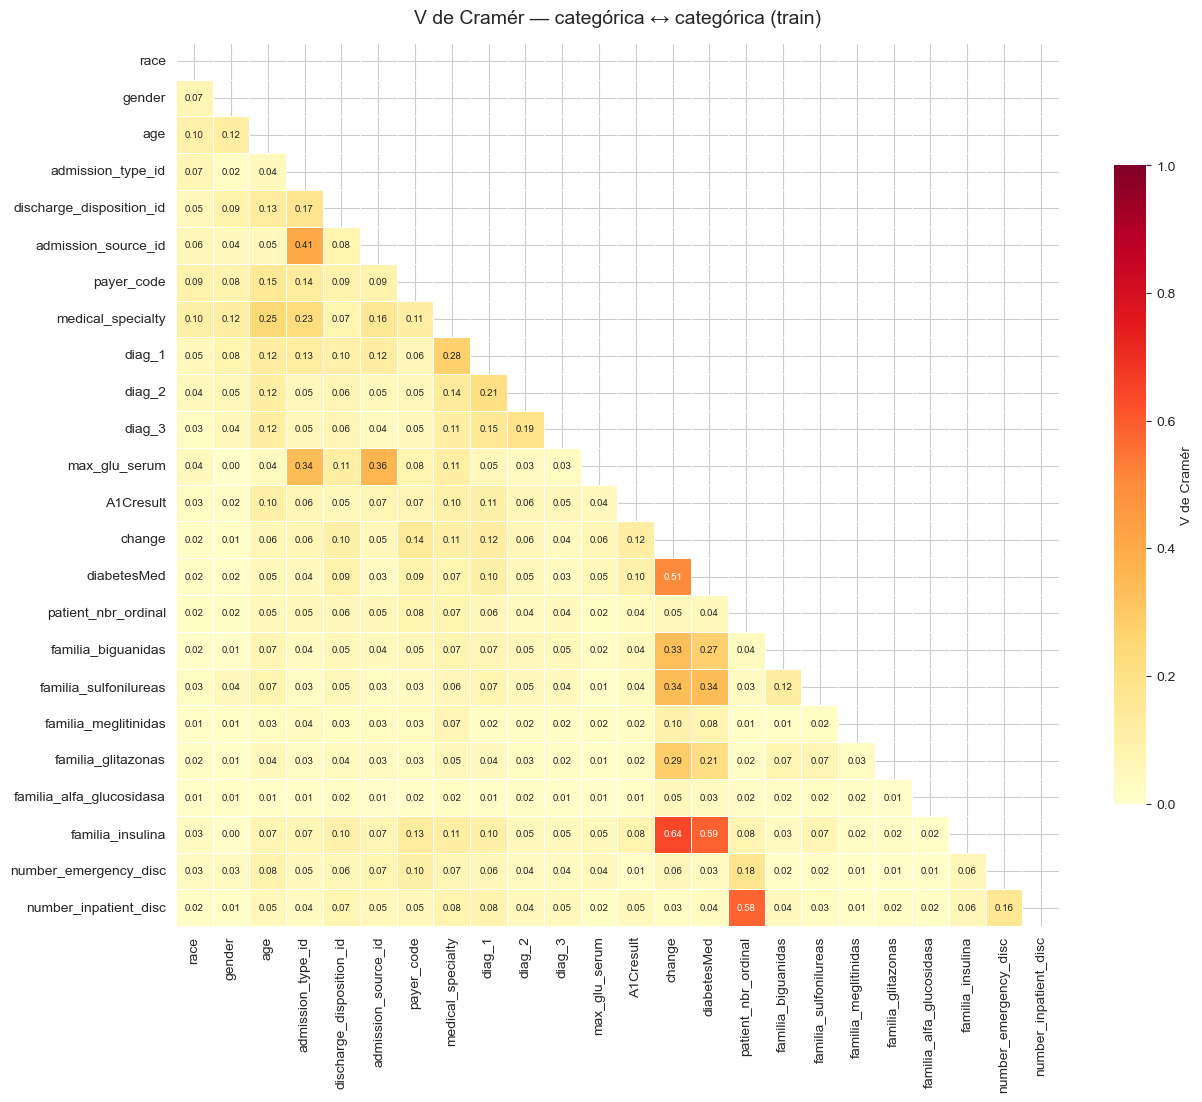

In [56]:
def cramers_v(x, y_):
    tabla = pd.crosstab(x, y_)
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan
    chi2_stat = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2_stat / (n * k))

cramer_mat = pd.DataFrame(np.eye(len(cat_orig)), index=cat_orig, columns=cat_orig)
for i, c1 in enumerate(cat_orig):
    for c2 in cat_orig[i + 1:]:
        v = cramers_v(X_train[c1], X_train[c2])
        cramer_mat.loc[c1, c2] = v
        cramer_mat.loc[c2, c1] = v

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(cramer_mat, dtype=bool))
sns.heatmap(cramer_mat, mask=mask, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            square=True, linewidths=0.4, ax=ax, annot_kws={"size": 7},
            cbar_kws={"label": "V de Cramér", "shrink": .7})
ax.set_title("V de Cramér — categórica ↔ categórica (train)", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [57]:
UMBRAL_CAT = 0.5
vm = cramer_mat.where(np.triu(np.ones(cramer_mat.shape), k=1).astype(bool)).stack()
pares_cat = (pd.DataFrame({"feature_1": [i[0] for i in vm.index],
                           "feature_2": [i[1] for i in vm.index],
                           "V_de_Cramer": vm.to_numpy().round(3)})
             .sort_values("V_de_Cramer", ascending=False).reset_index(drop=True))
print(f"Pares categóricos con V >= {UMBRAL_CAT}: {(pares_cat['V_de_Cramer'] >= UMBRAL_CAT).sum()}\n")
pares_cat.head(12)

Pares categóricos con V >= 0.5: 4



,feature_1,feature_2,V_de_Cramer
0,change,familia_insulina,0.643
1,diabetesMed,familia_insulina,0.587
2,patient_nbr_ordinal,number_inpatient_disc,0.580
3,change,diabetesMed,0.506
4,admission_type_id,admission_source_id,0.409
5,admission_source_id,max_glu_serum,0.363
6,diabetesMed,familia_sulfonilureas,0.343
7,admission_type_id,max_glu_serum,0.341
8,change,familia_sulfonilureas,0.341
9,change,familia_biguanidas,0.333


### 6.2.3 Numérica ↔ categórica: Eta cuadrado

Completa la grilla de tipos. El **Eta cuadrado** (razón de correlación) es la proporción de varianza
de la numérica explicada por la pertenencia a cada categoría: 0 = la categórica no dice nada sobre
la numérica, 1 = la determina completamente.

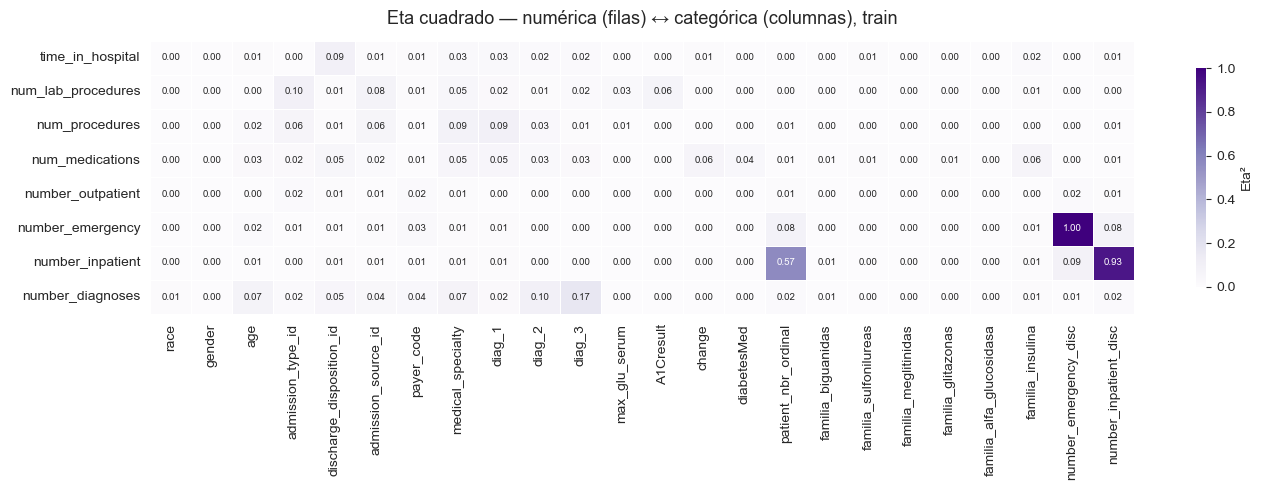

,numerica,categorica,eta_cuadrado
0,number_emergency,number_emergency_disc,1.000
1,number_inpatient,number_inpatient_disc,0.929
2,number_inpatient,patient_nbr_ordinal,0.567
3,number_diagnoses,diag_3,0.166
4,number_diagnoses,diag_2,0.101
5,num_lab_procedures,admission_type_id,0.101
6,num_procedures,diag_1,0.095
7,time_in_hospital,discharge_disposition_id,0.095


In [58]:
def eta2_num_cat(num, cat):
    grupos = [g.to_numpy() for _, g in num.groupby(cat, observed=True) if len(g) > 0]
    if len(grupos) < 2:
        return np.nan
    media_total = num.mean()
    ss_total = ((num - media_total) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - media_total) ** 2 for g in grupos)
    return ss_between / ss_total if ss_total > 0 else np.nan

eta_mat = pd.DataFrame(index=num_orig, columns=cat_orig, dtype=float)
for n_ in num_orig:
    for c in cat_orig:
        eta_mat.loc[n_, c] = eta2_num_cat(X_train[n_], X_train[c])

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(eta_mat.astype(float), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1,
            linewidths=0.4, ax=ax, annot_kws={"size": 7}, cbar_kws={"label": "Eta²", "shrink": .8})
ax.set_title("Eta cuadrado — numérica (filas) ↔ categórica (columnas), train", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

em = eta_mat.stack().sort_values(ascending=False)
pares_mixtos = pd.DataFrame({"numerica": [i[0] for i in em.index],
                             "categorica": [i[1] for i in em.index],
                             "eta_cuadrado": em.to_numpy().round(3)})
pares_mixtos.head(8)

**Lectura del bloque mixto:** los valores más altos son los pares donde la categórica es la
**versión discretizada** de la propia numérica (`number_emergency` ↔ `number_emergency_disc`,
`number_inpatient` ↔ `number_inpatient_disc`). Es redundancia por construcción y ya está resuelta
por diseño: el ensamblado de la sección 7 usa la versión discretizada y deja fuera la numérica
cruda, en vez de meter las dos. Fuera de esos pares, ninguna categórica explica una porción
sustancial de la varianza de una numérica.

## 6.3 Decisión final: variables descartadas y conservadas

Se combinan los dos análisis. Para la redundancia categórica se aplican **dos niveles**, con la
información mutua de 6.1.3 como criterio de desempate:

1. **V ≥ 0.7 — descarte automático.** Las dos variables son prácticamente la misma; se conserva la
   de mayor información mutua con el target.
2. **0.5 ≤ V < 0.7 — decisión explícita.** La asociación es fuerte pero las variables no son
   intercambiables. Se descarta sólo si una está **conceptualmente contenida** en la otra.

Aplicado a este dataset:

- **Se descartan `change` y `diabetesMed`**: son resúmenes binarios de lo que las seis variables de
  familia farmacológica ya expresan con cuatro estados (`Up`/`Down` **es** un cambio de medicación;
  `No` vs. el resto **es** el "hay medicación"). Además su información mutua con el target está
  entre las más bajas, así que la pérdida es mínima.
- **Se conservan `patient_nbr_ordinal` y `number_inpatient_disc`** pese a su V de 0.58: miden
  **ventanas temporales distintas** —encuentros previos en todo el registro vs. internaciones en el
  año anterior— y encabezan el ranking de relevancia de 6.1. Descartar una por una asociación
  moderada sería sacrificar la señal más fuerte del problema para ganar una única variable.

Esto ilustra por qué el análisis de redundancia **no puede ser mecánico**: una regla del tipo
"descartar siempre la de menos categorías" habría eliminado `number_inpatient_disc`, la variable
más predictiva de todo el trabajo.

In [59]:
UMBRAL_DESCARTE_AUTOMATICO = 0.7

descartes_auto = set()
for _, fila in pares_cat[pares_cat["V_de_Cramer"] >= UMBRAL_DESCARTE_AUTOMATICO].iterrows():
    f1, f2 = fila["feature_1"], fila["feature_2"]
    descartes_auto.add(f1 if MI_POR_VARIABLE.get(f1, 0) <= MI_POR_VARIABLE.get(f2, 0) else f2)

descartes_explicitos = {"change", "diabetesMed"}
descartadas_redundancia = sorted(descartes_auto | descartes_explicitos)

print("Pares por encima del umbral de reporte y decisión tomada:\n")
for _, fila in pares_cat[pares_cat["V_de_Cramer"] >= UMBRAL_CAT].iterrows():
    f1, f2, v = fila["feature_1"], fila["feature_2"], fila["V_de_Cramer"]
    desc = [c for c in (f1, f2) if c in descartadas_redundancia]
    print(f"  {f1:24s} ↔ {f2:24s} V={v:.3f}  ->  "
          f"{'se descarta ' + ', '.join(desc) if desc else 'se CONSERVAN ambas'}")

print(f"\nDescartadas por redundancia ({len(descartadas_redundancia)}): {descartadas_redundancia}")

Pares por encima del umbral de reporte y decisión tomada:

  change                   ↔ familia_insulina         V=0.643  ->  se descarta change
  diabetesMed              ↔ familia_insulina         V=0.587  ->  se descarta diabetesMed
  patient_nbr_ordinal      ↔ number_inpatient_disc    V=0.580  ->  se CONSERVAN ambas
  change                   ↔ diabetesMed              V=0.506  ->  se descarta change, diabetesMed

Descartadas por redundancia (2): ['change', 'diabetesMed']


In [60]:
# --- Las numericas crudas cuya version discretizada entra al modelo (redundancia por construccion)
descartadas_por_discretizacion = ["number_emergency", "number_inpatient"]

descartadas_total = sorted(set(descartadas_relevancia) | set(descartadas_redundancia)
                           | set(descartadas_por_discretizacion))
variables_seleccionadas = [c for c in (num_orig + cat_orig) if c not in descartadas_total]

resumen_decision = pd.DataFrame({
    "variable": num_orig + cat_orig,
    "tipo": ["numérica"] * len(num_orig) + ["categórica"] * len(cat_orig),
})
def _motivo(v):
    motivos = []
    if v in descartadas_relevancia: motivos.append("baja relevancia")
    if v in descartadas_redundancia: motivos.append("redundancia")
    if v in descartadas_por_discretizacion: motivos.append("reemplazada por su versión discretizada")
    return " + ".join(motivos) if motivos else "—"
resumen_decision["motivo_descarte"] = resumen_decision["variable"].apply(_motivo)
resumen_decision["decision"] = np.where(
    resumen_decision["variable"].isin(variables_seleccionadas), "CONSERVADA", "descartada")
resumen_decision["info_mutua"] = resumen_decision["variable"].map(MI_POR_VARIABLE).round(5)

print(f"Variables candidatas:    {len(num_orig) + len(cat_orig)}")
print(f"Descartadas:             {len(descartadas_total)}")
print(f"  - por baja relevancia: {len(descartadas_relevancia)}")
print(f"  - por redundancia:     {len(descartadas_redundancia)}")
print(f"  - por discretización:  {len(descartadas_por_discretizacion)}")
print(f"SELECCIONADAS:           {len(variables_seleccionadas)}")
print()
resumen_decision.sort_values(["decision", "info_mutua"], ascending=[True, False]).reset_index(drop=True)

Variables candidatas:    32
Descartadas:             14
  - por baja relevancia: 10
  - por redundancia:     2
  - por discretización:  2
SELECCIONADAS:           18



,variable,tipo,motivo_descarte,decision,info_mutua
0,number_inpatient_disc,categórica,—,CONSERVADA,0.01015
1,patient_nbr_ordinal,categórica,—,CONSERVADA,0.00873
2,discharge_disposition_id,categórica,—,CONSERVADA,0.00763
3,number_diagnoses,numérica,—,CONSERVADA,0.00495
4,number_emergency_disc,categórica,—,CONSERVADA,0.00271
5,num_lab_procedures,numérica,—,CONSERVADA,0.00221
6,time_in_hospital,numérica,—,CONSERVADA,0.00219
7,medical_specialty,categórica,—,CONSERVADA,0.00182
8,num_medications,numérica,—,CONSERVADA,0.00123
9,familia_insulina,categórica,—,CONSERVADA,0.00094


# 7. Codificación, escalado y balance de clases

Con el conjunto de variables ya decidido, se codifica. Todos los estadísticos de
encoding y escalado se ajustan **únicamente con train**.

Las estrategias se eligen según el tipo de variable y, dentro de las nominales, según su
cardinalidad (tabla de la sección 1.4), y se aplican **sólo a las variables seleccionadas en 6.3**:

| Estrategia | Variables | Motivo |
|---|---|---|
| **Sin codificar** (numéricas) | `time_in_hospital`, `num_lab_procedures`, `num_medications`, `number_diagnoses` | Ya son numéricas; no hay nada que codificar |
| **Ordinal** | `age`, `patient_nbr_ordinal`, `number_emergency_disc`, `number_inpatient_disc` | Orden lógico creciente; se preserva sin crear dummies |
| **Target encoding out-of-fold** (nominales con ≥ 10 categorías) | `medical_specialty` (70), `discharge_disposition_id` (26), `payer_code` (18), `admission_source_id` (16), `diag_2` (12), `diag_3` (12), `diag_1` (11) | Cardinalidad alta; condensa cada categoría en su tasa histórica en una sola columna |
| **One-hot** (nominales con < 10 categorías) | `A1Cresult` (4), `familia_biguanidas` (4), `familia_insulina` (4) | Pocas categorías; no explota la dimensionalidad y no impone un orden inexistente |

**Por qué el corte está en 10 categorías.** La nominal más chica del grupo de target encoding
tiene 11 categorías y la más grande del grupo de one-hot tiene 4 — no hay ninguna nominal en el
medio. Cualquier umbral entre 5 y 11 da la misma partición, y la celda siguiente lo verifica con
un `assert` en vez de afirmarlo.

In [61]:
# El umbral se aplica, no se declara: los grupos salen de medir la cardinalidad en TRAIN.
UMBRAL_TARGET_ENC = 10   # nominales con >= 10 categorias -> target encoding; con menos -> one-hot
CAND_ORDINALES = ["age", "patient_nbr_ordinal", "number_emergency_disc", "number_inpatient_disc"]

# Rama 1 y 2 del arbol: numericas, y categoricas con orden intrinseco.
cols_num_modelo = [c for c in num_orig if c in variables_seleccionadas]
cols_ordinales = [c for c in CAND_ORDINALES if c in variables_seleccionadas]

# Ramas 3 y 4: recien aca decide la cardinalidad, y sobre las nominales que quedaron.
cat_nominales = [c for c in cat_orig if c in variables_seleccionadas and c not in cols_ordinales]
card_nom = {c: X_train[c].nunique() for c in cat_nominales}
por_card = lambda cs: sorted(cs, key=lambda c: -card_nom[c])
cols_alta_cardinalidad = por_card([c for c in cat_nominales if card_nom[c] >= UMBRAL_TARGET_ENC])
cols_baja_cardinalidad = por_card([c for c in cat_nominales if card_nom[c] < UMBRAL_TARGET_ENC])

print(f"Numéricas (sin codificar)     ({len(cols_num_modelo)}): {cols_num_modelo}")
print(f"Ordinal encoding              ({len(cols_ordinales)}): {cols_ordinales}")
print(f"Target encoding out-of-fold   ({len(cols_alta_cardinalidad)}): {cols_alta_cardinalidad}")
print(f"One-hot encoding              ({len(cols_baja_cardinalidad)}): {cols_baja_cardinalidad}")

# El umbral tiene que caer en un HUECO de la distribucion. Si no, es un numero elegido a medida.
minima_te = min(card_nom[c] for c in cols_alta_cardinalidad)
maxima_oh = max(card_nom[c] for c in cols_baja_cardinalidad)
print(f"\nUmbral aplicado: >= {UMBRAL_TARGET_ENC} categorías")
print(f"  mínima del grupo target encoding: {minima_te}   ·   máxima del grupo one-hot: {maxima_oh}")
print(f"  el corte cae en un hueco de {minima_te - maxima_oh} categorías: ninguna nominal en el medio,")
print(f"  así que cualquier umbral entre {maxima_oh + 1} y {minima_te} da la misma partición.")
assert minima_te > maxima_oh, "el umbral parte un grupo en vez de caer en un hueco"

asignadas = set(cols_num_modelo) | set(cols_ordinales) | set(cols_alta_cardinalidad) | set(cols_baja_cardinalidad)
assert asignadas == set(variables_seleccionadas), (
    f"Variables seleccionadas sin estrategia de codificación asignada: "
    f"{set(variables_seleccionadas) - asignadas}")
print("\nTodas las variables seleccionadas tienen estrategia de codificación asignada.")

Numéricas (sin codificar)     (4): ['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_diagnoses']
Ordinal encoding              (4): ['age', 'patient_nbr_ordinal', 'number_emergency_disc', 'number_inpatient_disc']
Target encoding out-of-fold   (7): ['medical_specialty', 'discharge_disposition_id', 'payer_code', 'admission_source_id', 'diag_2', 'diag_3', 'diag_1']
One-hot encoding              (3): ['A1Cresult', 'familia_biguanidas', 'familia_insulina']

Umbral aplicado: >= 10 categorías
  mínima del grupo target encoding: 11   ·   máxima del grupo one-hot: 4
  el corte cae en un hueco de 7 categorías: ninguna nominal en el medio,
  así que cualquier umbral entre 5 y 11 da la misma partición.

Todas las variables seleccionadas tienen estrategia de codificación asignada.


## 7.1 Ordinal encoding

In [62]:
ORDENES = {"age": orden_age, "patient_nbr_ordinal": orden_pnbr,
           "number_emergency_disc": ["0", "1", "2", "3 o mas"],
           "number_inpatient_disc": ["0", "1", "2", "3 o mas"]}

for c in cols_ordinales:
    enc = OrdinalEncoder(categories=[ORDENES[c]])
    X_train[c + "_ord"] = enc.fit_transform(X_train[[c]])
    X_test[c + "_ord"] = enc.transform(X_test[[c]])

print("Ordinal encoding aplicado a:", [c + "_ord" for c in cols_ordinales])

Ordinal encoding aplicado a: ['age_ord', 'patient_nbr_ordinal_ord', 'number_emergency_disc_ord', 'number_inpatient_disc_ord']


## 7.2 Target encoding out-of-fold con suavizado

Las dos técnicas estándar:

1. **Out-of-fold**: la codificación de cada fila de train se calcula con los **otros** folds. Los
   folds se arman con `StratifiedGroupKFold` agrupando por paciente, coherente con el split general.
2. **Suavizado** hacia la media global con peso `m = 20`: una categoría con pocos casos queda
   traccionada hacia la tasa global en vez de adoptar una media inestable.

Para test se usa la codificación ajustada con **todo** train (también suavizada), que es la
información legítimamente disponible al momento de predecir.

In [63]:
SUAVIZADO, N_FOLDS_TE = 20, 5

def _medias_suavizadas(y_fit, x_fit, media_global, m=SUAVIZADO):
    agg = y_fit.groupby(x_fit.astype(object), observed=True).agg(["mean", "count"])
    return (agg["mean"] * agg["count"] + media_global * m) / (agg["count"] + m)

media_global = float(y_train_final.mean())
skf_te = StratifiedGroupKFold(n_splits=N_FOLDS_TE, shuffle=True, random_state=RANDOM_STATE)
folds_te = list(skf_te.split(X_train, y_train_final, groups=grupos_train))

for c in cols_alta_cardinalidad:
    col_oof = pd.Series(np.nan, index=X_train.index, dtype=float)
    for idx_fit, idx_apply in folds_te:
        medias = _medias_suavizadas(y_train_final.iloc[idx_fit], X_train[c].iloc[idx_fit], media_global)
        col_oof.iloc[idx_apply] = (X_train[c].astype(object).iloc[idx_apply]
                                   .map(medias).astype(float).to_numpy())
    X_train[c + "_te"] = col_oof.fillna(media_global)

    medias_full = _medias_suavizadas(y_train_final, X_train[c], media_global)
    X_test[c + "_te"] = X_test[c].astype(object).map(medias_full).astype(float).fillna(media_global)

print(f"Target encoding out-of-fold ({N_FOLDS_TE} folds, suavizado m={SUAVIZADO}), "
      f"media global de train = {media_global:.4f}")

Target encoding out-of-fold (5 folds, suavizado m=20), media global de train = 0.1127


In [64]:
filas_te = []
for c in cols_alta_cardinalidad:
    ingenua = X_train[c].astype(object).map(
        y_train_final.groupby(X_train[c].astype(object), observed=True).mean()).astype(float)
    filas_te.append([c, X_train[c].nunique(),
                     abs(float(np.corrcoef(ingenua, y_train_final)[0, 1])),
                     abs(float(np.corrcoef(X_train[c + "_te"], y_train_final)[0, 1]))])

cmp_te = pd.DataFrame(filas_te, columns=["variable", "n_categorias",
                                         "|corr| encoding ingenuo", "|corr| out-of-fold"])
cmp_te["inflación"] = (cmp_te["|corr| encoding ingenuo"] - cmp_te["|corr| out-of-fold"]).round(4)
print("Cuánta asociación aparente era artefacto del propio encoding:\n")
cmp_te.round(4)

Cuánta asociación aparente era artefacto del propio encoding:



,variable,n_categorias,|corr| encoding ingenuo,|corr| out-of-fold,inflación
0,medical_specialty,70,0.0573,0.0403,0.0170
1,discharge_disposition_id,26,0.1233,0.1191,0.0043
2,payer_code,18,0.0313,0.0210,0.0103
3,admission_source_id,16,0.0208,0.0097,0.0111
4,diag_2,12,0.0256,0.0164,0.0092
5,diag_3,12,0.0314,0.0250,0.0064
6,diag_1,11,0.0336,0.0281,0.0054


La diferencia entre ambas columnas es exactamente la porción de asociación que era
artefacto del encoding. Cuanto mayor la cardinalidad, mayor la inflación.

## 7.3 One-hot encoding

El conjunto de variables ya viene decidido por la sección 6.3, y un `assert`
verifica que toda variable seleccionada efectivamente se codifique.

In [65]:
if cols_baja_cardinalidad:
    print("Cardinalidad de las variables que van a one-hot:")
    for c in sorted(cols_baja_cardinalidad, key=lambda x: -X_train[x].nunique()):
        print(f"  {c:26s} {X_train[c].nunique():3d} categorías")

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    ohe.fit(X_train[cols_baja_cardinalidad])
    nombres_ohe = ohe.get_feature_names_out(cols_baja_cardinalidad)
    ohe_train = pd.DataFrame(ohe.transform(X_train[cols_baja_cardinalidad]),
                             columns=nombres_ohe, index=X_train.index)
    ohe_test = pd.DataFrame(ohe.transform(X_test[cols_baja_cardinalidad]),
                            columns=nombres_ohe, index=X_test.index)
    print(f"\nColumnas generadas por one-hot: {ohe_train.shape[1]}")
else:
    ohe_train = pd.DataFrame(index=X_train.index)
    ohe_test = pd.DataFrame(index=X_test.index)
    print("Ninguna variable seleccionada requiere one-hot.")

Cardinalidad de las variables que van a one-hot:
  A1Cresult                    4 categorías
  familia_biguanidas           4 categorías
  familia_insulina             4 categorías

Columnas generadas por one-hot: 12


## 7.4 Ensamblado y escalado

Se arma la matriz final y se aplica `StandardScaler` **una única vez**, ajustado sólo con train, ya
con todas las columnas creadas. Varios modelos candidatos (SVM, PCA) son sensibles a la escala.

In [66]:
cols_finales = (cols_num_modelo
                + [c + "_ord" for c in cols_ordinales]
                + [c + "_te" for c in cols_alta_cardinalidad])

X_train_final = pd.concat([X_train[cols_finales].reset_index(drop=True),
                           ohe_train.reset_index(drop=True)], axis=1)
X_test_final = pd.concat([X_test[cols_finales].reset_index(drop=True),
                          ohe_test.reset_index(drop=True)], axis=1)

print(f"Variables seleccionadas: {len(variables_seleccionadas)}")
print(f"Columnas tras codificar: {X_train_final.shape[1]}")

Variables seleccionadas: 18
Columnas tras codificar: 27


### Redundancia estructural del one-hot

Última fuente de redundancia, que sólo existe a nivel de columna codificada: las dummies de una
variable binaria suman 1, así que correlacionan **exactamente −1**. No es redundancia informativa
sino una restricción algebraica, y descartar una de las dos es simplemente elegir la **categoría de
referencia** (`drop_first`), no perder información.

In [67]:
corr_cod = X_train_final.corr()
cc = corr_cod.where(np.triu(np.ones(corr_cod.shape), k=1).astype(bool)).stack()
pares_cod = (pd.DataFrame({"feature_1": [i[0] for i in cc.index],
                           "feature_2": [i[1] for i in cc.index],
                           "correlacion": cc.to_numpy()})
             .assign(abs_corr=lambda d: d["correlacion"].abs())
             .query("abs_corr >= 0.85")
             .sort_values("abs_corr", ascending=False).reset_index(drop=True))

print(f"Pares con |correlación| >= 0.85 en la matriz codificada: {len(pares_cod)}")
if len(pares_cod):
    display(pares_cod.round(3))
    cols_drop_estructural = sorted(set(pares_cod["feature_2"]))
    X_train_final = X_train_final.drop(columns=cols_drop_estructural)
    X_test_final = X_test_final.drop(columns=cols_drop_estructural)
    print(f"\nColumnas eliminadas (categoría de referencia): {cols_drop_estructural}")

print(f"\nMatriz final: {X_train_final.shape[1]} columnas")

Pares con |correlación| >= 0.85 en la matriz codificada: 1


,feature_1,feature_2,correlacion,abs_corr
0,familia_biguanidas_No,familia_biguanidas_Steady,-0.951,0.951



Columnas eliminadas (categoría de referencia): ['familia_biguanidas_Steady']

Matriz final: 26 columnas


In [68]:
scaler = StandardScaler()
X_train_reducido = pd.DataFrame(scaler.fit_transform(X_train_final), columns=X_train_final.columns)
X_test_reducido = pd.DataFrame(scaler.transform(X_test_final), columns=X_test_final.columns)

print("X_train_reducido:", X_train_reducido.shape, " X_test_reducido:", X_test_reducido.shape)
X_train_reducido.describe().T[["mean", "std"]].round(2).head(10)

X_train_reducido: (71583, 26)  X_test_reducido: (30180, 26)


,mean,std
time_in_hospital,0.0,1.0
num_lab_procedures,-0.0,1.0
num_medications,0.0,1.0
number_diagnoses,0.0,1.0
age_ord,0.0,1.0
patient_nbr_ordinal_ord,-0.0,1.0
number_emergency_disc_ord,0.0,1.0
number_inpatient_disc_ord,0.0,1.0
medical_specialty_te,0.0,1.0
discharge_disposition_id_te,-0.0,1.0


## 7.5 Balance de clases

### Diagnóstico del desbalance

Clase 0 (no reingresa o reingresa después de 30 días): 88.7%
Clase 1 (reingresa antes de 30 días):                  11.3%


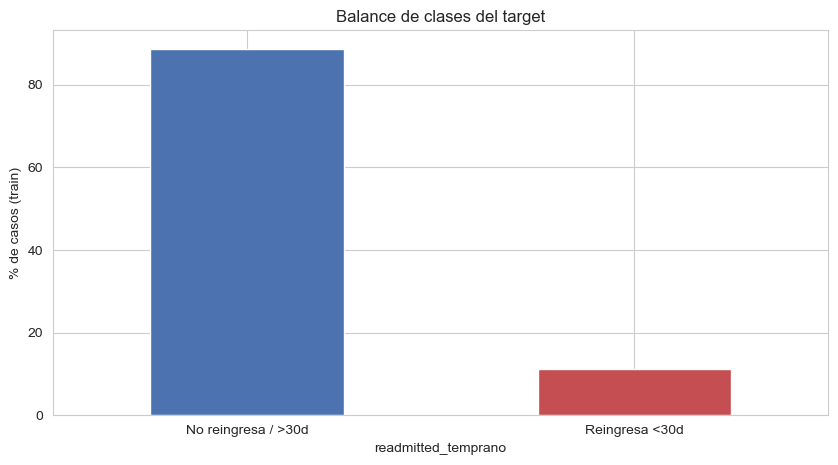

In [69]:
balance = y_train_final.value_counts(normalize=True).sort_index() * 100
print(f"Clase 0 (no reingresa o reingresa después de 30 días): {balance[0]:.1f}%")
print(f"Clase 1 (reingresa antes de 30 días):                  {balance[1]:.1f}%")

balance.plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.xticks([0, 1], ["No reingresa / >30d", "Reingresa <30d"], rotation=0)
plt.ylabel("% de casos (train)")
plt.title("Balance de clases del target")
plt.show()

El desbalance es **moderado** (~89% / 11%), no extremo, pero suficiente para que un modelo sin
ajustes tienda a "predecir siempre NO reingreso" con accuracy engañosamente alta.

### Mecanismos evaluados

Los dos se aplican **únicamente sobre train**:

1. **Class weighting**: no modifica los datos, penaliza más los errores sobre la clase minoritaria.
2. **Undersampling aleatorio**: reduce el dataset, descarta información potencialmente útil.


**Dónde se aplica cada uno** 

| Mecanismo | Dónde se usa |
|---|---|
| Undersampling | Secciones 10.2 y 10.3 (red neuronal y SVM), dentro de la validación cruzada |
| `class_weight="balanced"` | Secciones 10.4 y 10.5 (Random Forest y Gradient Boosting) |


# 8. Aprendizaje de Máquina -  Modelado

Esta sección continúa el EDA (secciones 1 a 7) sobre **el mismo split** agrupado por paciente. Todo lo que
sigue se decide únicamente con el conjunto de entrenamiento: el test queda sellado hasta la evaluación
final (M9) y se usa una sola vez.

**Decisiones de diseño**

| Tema | Decisión |
|---|---|
| Objetivo | Determinar el reingreso en los 30 días siguientes al alta (`readmitted_temprano`). Sin hipótesis previas. |
| Momento de predicción | Al alta hospitalaria: las 18 variables seleccionadas se conocen hasta ese momento. |
| Métrica primaria | ROC-AUC (no requiere umbral). |
| Métricas secundarias | Recall, precisión, F1, exactitud balanceada y AUC-PR, con el umbral elegido sobre predicciones fuera de fold en train. |
| Costo de los errores | No cuantificado. No se define un punto de operación. |
| Basal | Tabla de referencia de una sola variable, `number_inpatient_disc`, calculada con el train de cada fold. |
| Algoritmos | Regresión logística, Random Forest, CatBoost y XGBoost, todos contra el basal. |
| Validación | `StratifiedGroupKFold` de 5 folds agrupado por `patient_nbr` (semilla 42), solo sobre train. Repetición con otras semillas para los finalistas. |
| Fuga entre folds | Target encoding (agrupado por paciente), winsorización y escalado se aprenden dentro de cada fold. Las 18 variables quedan fijas. |
| Desbalance | Sin pesos de clase. El umbral se elige con predicciones fuera de fold. |
| Hiperparámetros | Carrera de mecanismos (grilla, aleatoria y Optuna) por algoritmo, con el mismo espacio, folds, métrica, semilla y presupuesto. |

## 8.0 M0 — Enganche con el EDA

### 8.0.1 Entorno y reproducibilidad

In [70]:
import os, platform, time, json
from pathlib import Path
import scipy, sklearn, xgboost, catboost, optuna

SEMILLA = RANDOM_STATE                       # semilla global (42)
ARTEFACTOS = Path("artefactos_ml")           # índices, folds, configuración y registro de experimentos
ARTEFACTOS.mkdir(exist_ok=True)

versiones = pd.DataFrame({
    "componente": ["Python", "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "catboost",
                   "optuna", "matplotlib", "seaborn"],
    "versión": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__,
                sklearn.__version__, xgboost.__version__, catboost.__version__, optuna.__version__,
                mpl.__version__, sns.__version__],
})
versiones.to_csv(ARTEFACTOS / "versiones.csv", index=False)
print(f"Núcleos de CPU disponibles: {os.cpu_count()}  |  semilla global: {SEMILLA}")
versiones

Núcleos de CPU disponibles: 14  |  semilla global: 42


,componente,versión
0,Python,3.13.16
1,numpy,2.5.3
2,pandas,3.0.6
3,scipy,1.18.1
4,scikit-learn,1.9.1
5,xgboost,3.4.2
6,catboost,1.2.10
7,optuna,5.0.0
8,matplotlib,3.11.2
9,seaborn,0.13.2


### 8.0.2 Reproducción del split y test sellado

Se verifica que el split del EDA se reproduce (mismas filas y misma tasa de positivos) y se guardan sus
índices. Luego se **sella el test**: sus datos se guardan en un archivo y se eliminan de la memoria, de modo
que ninguna celda de modelado pueda leerlos por error. 

In [71]:
# --- Reproducción del split (los índices salen del EDA, no se vuelve a particionar) ---
es_train = data_set["_es_train"].to_numpy()
enc_train = data_set.loc[es_train, "encounter_id"].to_numpy()
enc_test = data_set.loc[~es_train, "encounter_id"].to_numpy()
grupos_test = data_set.loc[~es_train, "patient_nbr"].reset_index(drop=True)

assert len(set(grupos_train) & set(grupos_test)) == 0, "hay pacientes en train y en test"
assert len(enc_train) == 71583 and len(enc_test) == 30180, "el split no reproduce el del EDA"
print(f"Train: {len(enc_train)} filas, {grupos_train.nunique()} pacientes | "
      f"Test: {len(enc_test)} filas, {grupos_test.nunique()} pacientes | pacientes compartidos: 0")
print(f"Tasa de reingreso en train: {y_train_final.mean():.4f}")

# --- Valores crudos de las dos numéricas que se winsorizan: la winsorización se aprende dentro de cada fold ---
crudo = pd.read_csv("diabetic_data.csv", usecols=["encounter_id", "num_lab_procedures",
                                                  "num_medications"]).set_index("encounter_id")

VARS_NUM = list(cols_num_modelo)             # 4 numéricas
VARS_ORD = list(cols_ordinales)              # 4 ordinales
VARS_TE = list(cols_alta_cardinalidad)       # 7 nominales de alta cardinalidad (target encoding)
VARS_OHE = list(cols_baja_cardinalidad)      # 3 nominales de baja cardinalidad (one-hot)
VARS_18 = VARS_NUM + VARS_ORD + VARS_TE + VARS_OHE
assert len(VARS_18) == 18 and set(VARS_18) == set(variables_seleccionadas)


def marco_modelado(X, ids_encuentro, grupos):
    # Las 18 variables de la selección del EDA + `patient_nbr` (solo para agrupar; no es predictora).
    M = X[VARS_18].copy()
    M["num_lab_procedures"] = crudo.loc[ids_encuentro, "num_lab_procedures"].to_numpy()
    M["num_medications"] = crudo.loc[ids_encuentro, "num_medications"].to_numpy()
    M["patient_nbr"] = grupos.to_numpy()
    return M


Xm_train = marco_modelado(X_train, enc_train, grupos_train)
Xm_test = marco_modelado(X_test, enc_test, grupos_test)

# Control de alineación: las columnas crudas, recortadas al p99 de train del EDA, deben dar las del EDA
for c in ["num_lab_procedures", "num_medications"]:
    assert (Xm_train[c].clip(upper=X_train[c].max()) == X_train[c]).all(), f"desalineada: {c}"

# --- Guardar los índices del split y SELLAR el test ---
pd.to_pickle({"X": Xm_test, "y": y_test_final.reset_index(drop=True), "grupos": grupos_test,
              "encounter_id": enc_test}, ARTEFACTOS / "test_sellado.pkl")
(ARTEFACTOS / "split.json").write_text(json.dumps({
    "semilla": SEMILLA, "test_size": 0.30, "agrupado_por": "patient_nbr",
    "encounter_id_train": [int(v) for v in enc_train],
    "encounter_id_test": [int(v) for v in enc_test]}))

for nombre in ["X_test", "X_test_final", "X_test_reducido", "y_test_final", "y_test", "ohe_test",
               "Xm_test", "grupos_test", "enc_test", "X", "y", "data_set", "df_train"]:
    globals().pop(nombre, None)
assert not any(n in globals() for n in ["X_test", "X_test_reducido", "y_test_final", "Xm_test"])
print("Test sellado: guardado en artefactos_ml/test_sellado.pkl y eliminado de la memoria.")

Train: 71583 filas, 50060 pacientes | Test: 30180 filas, 21455 pacientes | pacientes compartidos: 0
Tasa de reingreso en train: 0.1127


Test sellado: guardado en artefactos_ml/test_sellado.pkl y eliminado de la memoria.


**Lectura.** El split del EDA se reproduce exactamente: 71.583 filas de train y 30.180 de test, sin pacientes
compartidos. A partir de acá ninguna celda tiene acceso al test.

### 8.0.3 Preprocesamiento dentro del Pipeline

Para que ninguna decisión use datos de validación, todo lo que se **aprende de los datos** se ajusta solo con
el train de cada fold: la winsorización al p99 de `num_lab_procedures` y `num_medications`, el target
encoding (suavizado m=20, con folds internos agrupados por paciente) y el escalado. La codificación ordinal y
el one-hot usan categorías fijas, que son un esquema y no un estadístico. Las 18 variables quedan tal como
las dejó la selección del EDA.

`race` no se imputa porque no está entre las 18 variables seleccionadas. La winsorización de los conteos
previos no afecta a las variables que entran al modelo, porque `number_emergency_disc` y
`number_inpatient_disc` agrupan los valores de 3 en adelante.

In [72]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold


class Winsorizador(BaseEstimator, TransformerMixin):
    # Recorta al percentil q (aprendido en el fit) solo las columnas indicadas por posición.
    def __init__(self, posiciones=(), q=0.99):
        self.posiciones, self.q = posiciones, q

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.techos_ = {j: np.quantile(X[:, j], self.q) for j in self.posiciones}
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        for j, techo in self.techos_.items():
            X[:, j] = np.minimum(X[:, j], techo)
        return X


class QuitarColumna(BaseEstimator, TransformerMixin):
    # Elimina una columna por posición (categoría de referencia del one-hot).
    def __init__(self, indice=0):
        self.indice = indice

    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def transform(self, X):
        return np.delete(np.asarray(X, dtype=float), self.indice, axis=1)


def _medias_suavizadas(y_fit, x_fit, media_global, m):
    agg = y_fit.groupby(x_fit.astype(object), observed=True).agg(["mean", "count"])
    return (agg["mean"] * agg["count"] + media_global * m) / (agg["count"] + m)


class CodificadorObjetivoAgrupado(BaseEstimator, TransformerMixin):
    # Target encoding out-of-fold con suavizado. La última columna recibida es `patient_nbr` y solo
    # sirve para agrupar los folds internos; no se devuelve.
    def __init__(self, suavizado=20, n_folds=5, semilla=42):
        self.suavizado, self.n_folds, self.semilla = suavizado, n_folds, semilla

    def fit(self, X, y):
        cats, y = X.iloc[:, :-1].reset_index(drop=True), pd.Series(np.asarray(y))
        self.media_global_ = float(y.mean())
        self.medias_ = {c: _medias_suavizadas(y, cats[c], self.media_global_, self.suavizado)
                        for c in cats.columns}
        return self

    def fit_transform(self, X, y):
        # Para las filas de entrenamiento se usa la codificación fuera de fold (no la del fit completo).
        cats, y = X.iloc[:, :-1].reset_index(drop=True), pd.Series(np.asarray(y))
        grupos = X.iloc[:, -1].to_numpy()
        self.fit(X, y)
        out = np.full(cats.shape, np.nan)
        folds = StratifiedGroupKFold(n_splits=self.n_folds, shuffle=True, random_state=self.semilla)
        for idx_fit, idx_apl in folds.split(cats, y, groups=grupos):
            for j, c in enumerate(cats.columns):
                medias = _medias_suavizadas(y.iloc[idx_fit], cats[c].iloc[idx_fit],
                                            self.media_global_, self.suavizado)
                out[idx_apl, j] = (cats[c].astype(object).iloc[idx_apl].map(medias)
                                   .astype(float).to_numpy())
        return np.where(np.isnan(out), self.media_global_, out)

    def transform(self, X):
        cats = X.iloc[:, :-1].reset_index(drop=True)
        out = np.column_stack([cats[c].astype(object).map(self.medias_[c]).astype(float).to_numpy()
                               for c in cats.columns])
        return np.where(np.isnan(out), self.media_global_, out)


def construir_preprocesador(M):
    # Esquema fijo de categorías (tomado de los tipos del EDA, no de los datos de cada fold).
    ordenes = [list(M[c].cat.categories) for c in VARS_ORD]
    niveles_ohe = [sorted(str(v) for v in M[c].cat.categories) for c in VARS_OHE]   # orden alfabético, como en 7.3
    posicion_wins = [VARS_NUM.index("num_lab_procedures"), VARS_NUM.index("num_medications")]
    # posición de 'familia_biguanidas_Steady' dentro de las columnas one-hot (las columnas siguen el orden de VARS_OHE)
    k = VARS_OHE.index("familia_biguanidas")
    indice_referencia = sum(len(niveles_ohe[i]) for i in range(k)) + niveles_ohe[k].index("Steady")
    return ColumnTransformer([
        ("num", Winsorizador(posiciones=posicion_wins), VARS_NUM),
        ("ord", OrdinalEncoder(categories=ordenes), VARS_ORD),
        ("te", CodificadorObjetivoAgrupado(suavizado=SUAVIZADO, n_folds=N_FOLDS_TE, semilla=SEMILLA),
         VARS_TE + ["patient_nbr"]),
        # familia_biguanidas: se omite 'Steady' (categoría de referencia, igual que en 7.4)
        ("ohe", Pipeline([("oh", OneHotEncoder(categories=niveles_ohe, sparse_output=False)),
                          ("ref", QuitarColumna(indice=indice_referencia))]), VARS_OHE),
    ], remainder="drop")


def preprocesamiento():
    return Pipeline([("pre", construir_preprocesador(Xm_train)), ("esc", StandardScaler())])


# --- Control: ajustado con TODO train, el preprocesamiento debe reproducir la matriz del EDA ---
Z = preprocesamiento().fit_transform(Xm_train, y_train_final)
dif = np.abs(Z - X_train_reducido.to_numpy()).max()
print(f"Matriz del Pipeline: {Z.shape} | matriz del EDA: {X_train_reducido.shape} | "
      f"diferencia máxima absoluta: {dif:.2e}")
assert Z.shape == X_train_reducido.shape and dif < 1e-8

Matriz del Pipeline: (71583, 26) | matriz del EDA: (71583, 26) | diferencia máxima absoluta: 1.13e-11


**Lectura.** Ajustado con todo el train, el Pipeline reproduce la matriz de 26 columnas del EDA con una
diferencia máxima de 1e-11, que es error numérico. El preprocesamiento dentro del Pipeline es, por lo tanto,
equivalente al de la sección 7. Lo que cambia es el momento en que se aprende: en la validación cruzada se
ajusta solo con el train de cada fold, así que ningún dato de validación influye en la codificación ni en el
escalado.

Una nota de reproducibilidad: con la misma semilla, `StratifiedGroupKFold` genera folds distintos en
scikit-learn 1.7.2 y en 1.9.1, aunque el split de train y test es idéntico en ambas versiones. Por eso los
folds de este trabajo se generan una sola vez y se guardan como artefacto.

### 8.0.4 Medición de cómputo

Antes de lanzar búsquedas pesadas se mide cuánto tarda **un ajuste** de cada algoritmo sobre un fold real
(57.000 filas de entrenamiento, 26 columnas) y se proyecta el costo de la carrera de mecanismos. Se usan
configuraciones razonables, no óptimas; el AUC en este fold solo sirve para verificar que cada algoritmo
funciona.

In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

cv_medicion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_tr, idx_va = next(cv_medicion.split(Xm_train, y_train_final, groups=Xm_train["patient_nbr"]))

t0 = time.perf_counter()
prep = preprocesamiento()
Ztr = prep.fit_transform(Xm_train.iloc[idx_tr], y_train_final.iloc[idx_tr])
Zva = prep.transform(Xm_train.iloc[idx_va])
t_prep = time.perf_counter() - t0
ytr, yva = y_train_final.iloc[idx_tr], y_train_final.iloc[idx_va]

modelos_medicion = {
    "Regresión logística": LogisticRegression(C=1.0, max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1,
                                            random_state=SEMILLA),
    "XGBoost": XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist",
                             n_jobs=-1, random_state=SEMILLA),
    "CatBoost": CatBoostClassifier(iterations=1000, depth=6, random_seed=SEMILLA, verbose=0,
                                   thread_count=-1),
}
filas = []
for nombre, modelo in modelos_medicion.items():
    t0 = time.perf_counter()
    modelo.fit(Ztr, ytr)
    t_fit = time.perf_counter() - t0
    filas.append({"algoritmo": nombre, "segundos por ajuste": round(t_fit, 1),
                  "ROC-AUC (fold 1, verificación)": round(roc_auc_score(yva, modelo.predict_proba(Zva)[:, 1]), 3)})
medicion = pd.DataFrame(filas).set_index("algoritmo")
print(f"Preprocesamiento de un fold (ajuste + transformación): {t_prep:.1f} s | "
      f"entrenamiento: {len(idx_tr)} filas | validación: {len(idx_va)} filas")
medicion

Preprocesamiento de un fold (ajuste + transformación): 2.6 s | entrenamiento: 57266 filas | validación: 14317 filas


,segundos por ajuste,"ROC-AUC (fold 1, verificación)"
algoritmo,,
Regresión logística,0.0,0.662
Random Forest,2.1,0.650
XGBoost,1.1,0.666
CatBoost,3.0,0.670


In [74]:
# Proyección del costo de la carrera de mecanismos: evaluaciones por mecanismo x 5 folds x 3 mecanismos
EVALUACIONES = {"Regresión logística": 16, "Random Forest": 40, "XGBoost": 40, "CatBoost": 40}
FOLDS, MECANISMOS = 5, 3
proy = medicion[["segundos por ajuste"]].copy()
proy["evaluaciones por mecanismo"] = pd.Series(EVALUACIONES)
proy["ajustes en la carrera"] = proy["evaluaciones por mecanismo"] * FOLDS * MECANISMOS
proy["horas estimadas"] = (proy["segundos por ajuste"] * proy["ajustes en la carrera"] / 3600).round(2)
proy.loc["Total"] = ["", "", int(proy["ajustes en la carrera"].sum()), round(proy["horas estimadas"].sum(), 2)]
proy

,segundos por ajuste,evaluaciones por mecanismo,ajustes en la carrera,horas estimadas
algoritmo,,,,
Regresión logística,0.0,16,240,0.00
Random Forest,2.1,40,600,0.35
XGBoost,1.1,40,600,0.18
CatBoost,3.0,40,600,0.50
Total,,,2040,1.03


**Lectura.** Con 14 núcleos, un ajuste tarda entre 0 y 3 segundos, bastante menos de lo previsto, y el
preprocesamiento de un fold toma 2,6 segundos y se calcula una sola vez por fold. Con 40 evaluaciones por
mecanismo, la carrera completa de los cuatro algoritmos suma 2.040 ajustes y alrededor de una hora de
cómputo. El presupuesto definitivo se fija en M5, porque los espacios de búsqueda incluyen modelos más
grandes que estas configuraciones de prueba y cada ajuste puede tardar varias veces más.

El ROC-AUC de la columna de verificación corresponde a un solo fold con hiperparámetros por defecto, y solo
comprueba que los cuatro algoritmos funcionan (entre 0,65 y 0,67). No se usa para comparar algoritmos: eso se
hace en M4 con los cinco folds y las repeticiones.

### 8.0.5 Folds de validación y registro de experimentos

Los folds se generan **una sola vez** y se guardan, porque dependen de la versión de scikit-learn. Se usa
`StratifiedGroupKFold` de 5 folds, agrupado por `patient_nbr` y estratificado por el target. La semilla 42 es
la principal; las semillas 43, 44 y 45 son las repeticiones que se usan con los finalistas. Todo lo que parte
los datos (basal, búsqueda de hiperparámetros, predicciones fuera de fold) usa estos mismos folds.

También se abre el **registro de todos los experimentos**, incluidos los descartados, que se guarda en
`artefactos_ml/registro_experimentos.csv`.

In [75]:
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, balanced_accuracy_score)

SEMILLAS_CV = [42, 43, 44, 45]       # 42: principal; 43 a 45: repeticiones para los finalistas
N_FOLDS = 5
y_ent = y_train_final.reset_index(drop=True)
pacientes = Xm_train["patient_nbr"].to_numpy()

FOLD_ID = {}
for semilla in SEMILLAS_CV:
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
    ids = np.full(len(y_ent), -1, dtype=int)
    for k, (_, va) in enumerate(cv.split(Xm_train, y_ent, groups=pacientes)):
        ids[va] = k
    FOLD_ID[semilla] = ids
np.savez_compressed(ARTEFACTOS / "folds.npz", **{f"semilla_{s}": FOLD_ID[s] for s in SEMILLAS_CV})


def pares(semilla=42):
    # Lista de (índices de entrenamiento, índices de validación) de la repetición indicada.
    ids = FOLD_ID[semilla]
    return [(np.where(ids != k)[0], np.where(ids == k)[0]) for k in range(N_FOLDS)]


REGISTRO = []


def registrar(**campos):
    REGISTRO.append(campos)


def guardar_registro():
    pd.DataFrame(REGISTRO).to_csv(ARTEFACTOS / "registro_experimentos.csv", index=False)


print("Folds generados y guardados en artefactos_ml/folds.npz:",
      {s: np.bincount(FOLD_ID[s]).tolist() for s in SEMILLAS_CV})

Folds generados y guardados en artefactos_ml/folds.npz: {42: [14317, 14318, 14316, 14316, 14316], 43: [14317, 14314, 14314, 14314, 14324], 44: [14318, 14317, 14316, 14316, 14316], 45: [14318, 14317, 14316, 14316, 14316]}


**Lectura.** Se generaron cuatro repeticiones de 5 folds. Cada fold de validación tiene unas 14.317 filas, y la
verificación completa (pacientes no compartidos, balance de positivos) está en M3.

## 8.1 M1 — Basal

El punto de comparación es una **heurística de una sola variable derivada del EDA,
sin modelo** : "un baseline no es un modelo"). Cuando la variable no
es numérica, la cátedra usa una **tabla de referencia**: para cada nivel, el valor observado en el train.

**Variable elegida: `number_inpatient_disc`.** Es la variable con mayor asociación con el target en la
selección del EDA (sección 6.1: V de Cramér 0,155 e información mutua 0,0101, las más altas) y tiene solo
cuatro niveles (0, 1, 2 y 3 o más internaciones previas en el último año).

**Construcción.** En cada fold se calcula, con el train del fold, la tasa de reingreso de cada nivel. El
puntaje de cada paciente es la tasa de su nivel; un nivel no visto recibe la tasa base. Con ese puntaje se
calculan el ROC-AUC y el AUC-PR. Para las métricas que requieren una decisión se aplica la regla de Pima
sobre el puntaje: umbral en el punto medio entre las medianas del puntaje de cada clase, calculadas en el
train del fold. Si ningún paciente supera ese umbral, se usa la tasa base. No se ajusta ningún parámetro.

**Referencia adicional.** La prevalencia (predecir siempre la clase mayoritaria), que fija el piso de las
métricas.

,tasa de reingreso,pacientes-encuentros
number_inpatient_disc,,
0,0.0849,47335
1,0.1302,13777
2,0.1717,5377
3 o mas,0.2607,5094


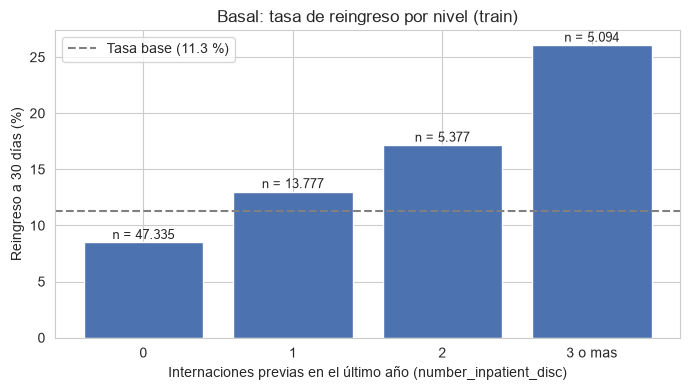

In [76]:
NIVELES_BASAL = list(Xm_train["number_inpatient_disc"].cat.categories)
VAR_BASAL = "number_inpatient_disc"

# Descripción del basal con todo train (solo para mostrar la tabla; la evaluación se hace por fold)
tabla_niveles = (y_ent.groupby(Xm_train[VAR_BASAL].astype(object)).agg(["mean", "count"])
                 .reindex(NIVELES_BASAL).rename(columns={"mean": "tasa de reingreso", "count": "pacientes-encuentros"}))
display(tabla_niveles.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(tabla_niveles.index, tabla_niveles["tasa de reingreso"] * 100, color="#4C72B0")
for b, n in zip(barras, tabla_niveles["pacientes-encuentros"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"n = {n:,}".replace(",", "."),
            ha="center", fontsize=9)
ax.axhline(y_ent.mean() * 100, color="gray", ls="--", label=f"Tasa base ({y_ent.mean()*100:.1f} %)")
ax.set_xlabel("Internaciones previas en el último año (number_inpatient_disc)")
ax.set_ylabel("Reingreso a 30 días (%)")
ax.set_title("Basal: tasa de reingreso por nivel (train)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** La tasa de reingreso crece de forma monótona con las internaciones previas: 8,5 % sin ninguna,
13,0 % con una, 17,2 % con dos y 26,1 % con tres o más, frente a una tasa base de 11,3 %. El 66 % de los
encuentros está en el nivel 0. Como la tabla tiene solo cuatro niveles, el basal produce cuatro valores
distintos de puntaje; ese es su techo, y un algoritmo puede aportar valor distinguiendo pacientes dentro de
un mismo nivel.

In [77]:
def puntaje_tabla(variable, idx_tr, idx_va, n_min=None):
    # Tabla de referencia: tasa de reingreso por nivel, calculada solo con el train del fold.
    x = Xm_train[variable].astype(object).reset_index(drop=True)
    x_tr, x_va = x.iloc[idx_tr], x.iloc[idx_va]
    if n_min is not None:                       # niveles con pocas filas en el fold de entrenamiento -> "otros"
        conteo = x_tr.value_counts()
        raros = set(conteo[conteo < n_min].index)
        x_tr = x_tr.where(~x_tr.isin(raros), "otros")
        x_va = x_va.where(~x_va.isin(raros), "otros")
    tasas = y_ent.iloc[idx_tr].groupby(x_tr).mean()
    base = y_ent.iloc[idx_tr].mean()
    return (x_tr.map(tasas).astype(float).to_numpy(),
            x_va.map(tasas).fillna(base).astype(float).to_numpy())


def metricas(y_real, puntaje, pred):
    return {"ROC-AUC": roc_auc_score(y_real, puntaje),
            "AUC-PR": average_precision_score(y_real, puntaje),
            "recall": recall_score(y_real, pred, zero_division=0),
            "precisión": precision_score(y_real, pred, zero_division=0),
            "F1": f1_score(y_real, pred, zero_division=0),
            "exactitud balanceada": balanced_accuracy_score(y_real, pred)}


filas, filas_prev = [], []
for k, (tr, va) in enumerate(pares(42)):
    s_tr, s_va = puntaje_tabla(VAR_BASAL, tr, va)
    y_tr, y_va = y_ent.iloc[tr], y_ent.iloc[va]
    umbral = (np.median(s_tr[y_tr == 0]) + np.median(s_tr[y_tr == 1])) / 2     # regla de Pima sobre el puntaje
    if (s_va > umbral).sum() == 0:
        umbral = y_tr.mean()                                                    # alternativa: tasa base
    m = metricas(y_va, s_va, (s_va > umbral).astype(int))
    filas.append({"fold": k + 1, "umbral": umbral, **m})
    registrar(fase="M1", algoritmo="basal: tabla number_inpatient_disc", semilla=42, fold=k + 1, **m)
    # referencia adicional: prevalencia (puntaje constante, predice siempre la clase mayoritaria)
    p = np.full(len(va), y_tr.mean())
    mp = metricas(y_va, p, np.zeros(len(va), dtype=int))
    filas_prev.append({"fold": k + 1, **mp})
    registrar(fase="M1", algoritmo="referencia: prevalencia", semilla=42, fold=k + 1, **mp)

basal_folds = pd.DataFrame(filas).set_index("fold")
prev_folds = pd.DataFrame(filas_prev).set_index("fold")
resumen_basal = pd.DataFrame({
    "basal (tabla): media": basal_folds.drop(columns="umbral").mean(),
    "basal (tabla): desvío": basal_folds.drop(columns="umbral").std(),
    "prevalencia: media": prev_folds.mean(),
})
display(basal_folds.round(4))
resumen_basal.round(4)

,umbral,ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
fold,,,,,,,
1,0.0853,0.6114,0.1628,0.5152,0.1690,0.2545,0.5967
2,0.1081,0.6057,0.1612,0.5046,0.1648,0.2485,0.5900
3,0.1068,0.6053,0.1577,0.5015,0.1682,0.2519,0.5933
4,0.1078,0.6082,0.1643,0.4960,0.1688,0.2519,0.5930
5,0.1076,0.5998,0.1582,0.4907,0.1633,0.2451,0.5859


,basal (tabla): media,basal (tabla): desvío,prevalencia: media
ROC-AUC,0.6061,0.0043,0.5000
AUC-PR,0.1609,0.0029,0.1127
recall,0.5016,0.0093,0.0000
precisión,0.1668,0.0026,0.0000
F1,0.2504,0.0036,0.0000
exactitud balanceada,0.5918,0.0041,0.5000


**Lectura.** El basal logra un ROC-AUC de 0,606 (desvío entre folds 0,004) y un AUC-PR de 0,161, contra 0,5 y
0,113 de la prevalencia, que fija el piso de ambas métricas. Con la regla de decisión marca a los pacientes
con al menos una internación previa: recall 0,50, precisión 0,167, F1 0,250 y exactitud balanceada 0,592. El
umbral difiere entre folds (0,085 en el primero y unos 0,108 en el resto), pero la decisión es la misma en
todos: nivel 1 o superior. Este es el número a superar: un algoritmo que no mejore claramente un ROC-AUC de
0,606 no justifica su complejidad.

### Chequeo confirmatorio de la variable del basal

La variable del basal se eligió por el ranking del EDA. Como confirmación se compara el ROC-AUC fuera de fold 
de la tabla de referencia construida con tres candidatas: `number_inpatient_disc`,
`patient_nbr_ordinal` y `discharge_disposition_id` (los niveles con menos de 200 filas en el train del fold
se agrupan en "otros"; con 11 % de positivos, 200 filas dejan unos 22 positivos por nivel).

**Criterio, declarado antes de mirar el resultado:** otra candidata le gana a `number_inpatient_disc` solo si
la diferencia media de ROC-AUC (candidata menos referencia) es positiva y mayor que el desvío entre folds de
esa diferencia. Se usan las cuatro repeticiones de folds (20 evaluaciones, que no son independientes entre sí).
Si otra candidata gana, se informa y no se cambia la variable por decisión propia.

,ROC-AUC medio,desvío entre folds,diferencia media vs. basal,desvío de la diferencia,¿le gana al basal?
variable,,,,,
number_inpatient_disc,0.6061,0.0057,NaN,NaN,NaN
patient_nbr_ordinal,0.5954,0.0058,-0.0106,0.0037,no
discharge_disposition_id,0.5868,0.0069,-0.0193,0.0089,no


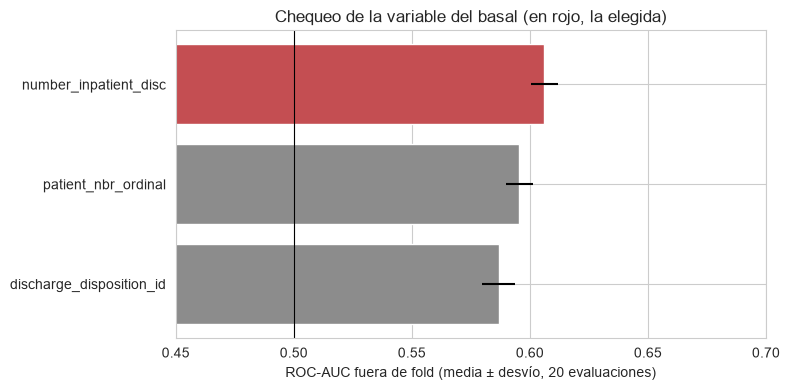

In [78]:
CANDIDATAS = {"number_inpatient_disc": None,
              "patient_nbr_ordinal": None,
              "discharge_disposition_id": 200}      # n_min: niveles con menos filas se agrupan en "otros"

filas = []
for var, n_min in CANDIDATAS.items():
    for semilla in SEMILLAS_CV:
        for k, (tr, va) in enumerate(pares(semilla)):
            _, s_va = puntaje_tabla(var, tr, va, n_min)
            auc = roc_auc_score(y_ent.iloc[va], s_va)
            filas.append({"variable": var, "semilla": semilla, "fold": k + 1, "ROC-AUC": auc})
            registrar(fase="M1-chequeo", algoritmo=f"tabla {var}", semilla=semilla, fold=k + 1, **{"ROC-AUC": auc})
chequeo = pd.DataFrame(filas)
ancho = chequeo.pivot_table(index=["semilla", "fold"], columns="variable", values="ROC-AUC")

resumen_chequeo = pd.DataFrame({"ROC-AUC medio": ancho.mean(), "desvío entre folds": ancho.std()})
for var in ancho.columns:
    if var != VAR_BASAL:
        dif = ancho[var] - ancho[VAR_BASAL]
        resumen_chequeo.loc[var, "diferencia media vs. basal"] = dif.mean()
        resumen_chequeo.loc[var, "desvío de la diferencia"] = dif.std()
        resumen_chequeo.loc[var, "¿le gana al basal?"] = "SÍ" if (dif.mean() > 0 and dif.mean() > dif.std()) else "no"
display(resumen_chequeo.sort_values("ROC-AUC medio", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
orden = resumen_chequeo.sort_values("ROC-AUC medio").index
ax.barh(orden, resumen_chequeo.loc[orden, "ROC-AUC medio"], xerr=resumen_chequeo.loc[orden, "desvío entre folds"],
        color=["#C44E52" if v == VAR_BASAL else "#8C8C8C" for v in orden])
ax.axvline(0.5, color="black", lw=0.8)
ax.set_xlim(0.45, max(0.7, resumen_chequeo["ROC-AUC medio"].max() + 0.03))
ax.set_xlabel("ROC-AUC fuera de fold (media ± desvío, 20 evaluaciones)")
ax.set_title("Chequeo de la variable del basal (en rojo, la elegida)")
plt.tight_layout()
plt.show()
guardar_registro()

**Lectura.** El criterio declarado se cumple: ninguna candidata le gana a `number_inpatient_disc`, que queda
confirmada como variable del basal. Con la tabla de referencia obtiene un ROC-AUC de 0,606, por encima de
`patient_nbr_ordinal` (0,595) y de `discharge_disposition_id` (0,587). La diferencia con `patient_nbr_ordinal`
(−0,011) es mayor que su desvío (0,004), así que no es ruido, y la de `discharge_disposition_id` (−0,019) es
la más variable (desvío 0,009). `discharge_disposition_id` encabezaba la asociación en la sección 3.6, pero
allí se medía contra el target de tres clases y todavía no existían las variables derivadas; usada sola, como
tabla de 26 niveles con los raros agrupados, discrimina menos que el historial de internaciones.

## 8.2 M2 — Definición formal

- **Problema.** Clasificación binaria supervisada: determinar si un paciente diabético reingresa en los 30
  días siguientes al alta (`readmitted_temprano`). El modelo se concibe para aplicarse al alta, con las 18
  variables seleccionadas en el EDA.
- **Métrica primaria.** ROC-AUC, porque compara la capacidad de ordenar a los pacientes por riesgo sin fijar un
  umbral. **Métricas secundarias:** recall, precisión, F1, exactitud balanceada y AUC-PR. Las que dependen de
  una decisión usan el umbral elegido con predicciones fuera de fold en train.
- **Costo de los errores.** No está cuantificado, y por eso no se define un punto de operación. Que un falso
  negativo cueste más que un falso positivo es un supuesto cualitativo que viene del planteo del dataset (el
  reingreso aumenta los costos y la morbimortalidad), no de la cátedra.
- **Criterio de éxito, declarado antes de ver los resultados de los algoritmos.** Un algoritmo supera al
  basal cuando su ROC-AUC medio de validación cruzada es mayor que el del basal por más que el desvío entre
  folds de la diferencia pareada, y esa diferencia es positiva en todos los folds de la repetición principal.
  Si ningún algoritmo lo logra, el resultado se informa como negativo y se discuten sus causas.
- **Restricciones.** No se exige interpretabilidad ni latencia. Las variables son las disponibles al alta.
  La regresión logística aporta una referencia interpretable.

## 8.3 M3 — Estrategia de validación

Validación cruzada de 5 folds, estratificada por el target y **agrupada por paciente**, solo sobre el train.
La cátedra usa 5 folds estratificados; el agrupamiento se agrega porque un mismo
paciente tiene varias internaciones y, si quedaran repartidas entre entrenamiento y validación, la validación
seria optimista. La misma estrategia vale para el basal y para los cuatro algoritmos. Se verifica que
ningún paciente aparezca en dos folds de validación, ni en el entrenamiento y la validación de un mismo
fold, y que la tasa de positivos sea pareja.

Verificación superada en las 4 repeticiones: ningún paciente en dos folds ni compartido con el entrenamiento.


,filas de validación,pacientes de validación,positivos,tasa de positivos (%),pacientes compartidos con el entrenamiento
fold,,,,,
1,14317,9990,1613,11.27,0
2,14318,9968,1613,11.27,0
3,14316,10000,1613,11.27,0
4,14316,10035,1613,11.27,0
5,14316,10067,1612,11.26,0


Resumen de las 4 repeticiones (tasa de positivos por fold, %):


,min,max
semilla,,
42,11.26,11.27
43,11.25,11.28
44,11.26,11.27
45,11.26,11.27


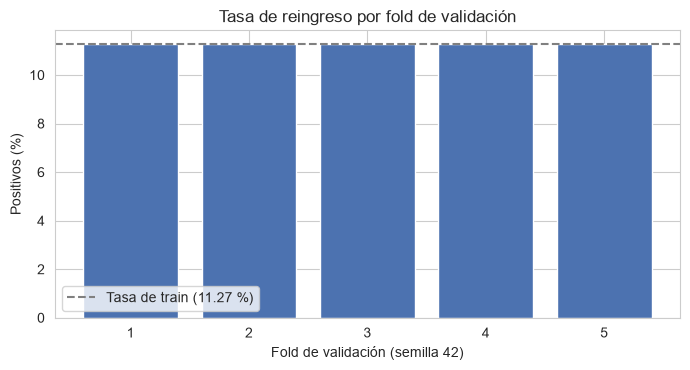

In [79]:
filas = []
for semilla in SEMILLAS_CV:
    ids = FOLD_ID[semilla]
    # cada paciente en un único fold de validación
    n_folds_por_paciente = pd.Series(ids).groupby(pacientes).nunique()
    assert n_folds_por_paciente.max() == 1, f"hay pacientes en más de un fold (semilla {semilla})"
    for k, (tr, va) in enumerate(pares(semilla)):
        compartidos = len(set(pacientes[tr]) & set(pacientes[va]))
        assert compartidos == 0, f"pacientes compartidos entre entrenamiento y validación (semilla {semilla}, fold {k+1})"
        filas.append({"semilla": semilla, "fold": k + 1, "filas de validación": len(va),
                      "pacientes de validación": len(set(pacientes[va])),
                      "positivos": int(y_ent.iloc[va].sum()),
                      "tasa de positivos (%)": round(y_ent.iloc[va].mean() * 100, 2),
                      "pacientes compartidos con el entrenamiento": compartidos})
diag_folds = pd.DataFrame(filas)
print("Verificación superada en las 4 repeticiones: ningún paciente en dos folds ni compartido con el entrenamiento.")
display(diag_folds[diag_folds["semilla"] == 42].set_index("fold").drop(columns="semilla"))
print("Resumen de las 4 repeticiones (tasa de positivos por fold, %):")
display(diag_folds.groupby("semilla")["tasa de positivos (%)"].agg(["min", "max"]))

fig, ax = plt.subplots(figsize=(7, 3.8))
d42 = diag_folds[diag_folds["semilla"] == 42]
ax.bar(d42["fold"].astype(str), d42["tasa de positivos (%)"], color="#4C72B0")
ax.axhline(y_ent.mean() * 100, color="gray", ls="--", label=f"Tasa de train ({y_ent.mean()*100:.2f} %)")
ax.set_xlabel("Fold de validación (semilla 42)")
ax.set_ylabel("Positivos (%)")
ax.set_title("Tasa de reingreso por fold de validación")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** La validación cumple lo exigido. Ningún paciente aparece en dos folds de validación ni compartido
con el entrenamiento de su fold, en las cuatro repeticiones. Los folds son parejos: entre 14.316 y 14.318
filas y entre 1.612 y 1.613 positivos cada uno, con una tasa de 11,26 a 11,27 % (11,25 a 11,28 % en las otras
semillas), igual a la del train. Es la estrategia que usan el basal y, desde M4, los cuatro algoritmos.

### 8.3.1 Chequeo de sensibilidad de la selección de variables

La selección de las 18 variables (sección 6) se hizo con todo el train, es decir, fuera de los folds. Las 18
quedan fijas como modelo, pero se mide cuánto depende esa elección de qué filas se usan: **la regla de
relevancia de la sección 6.1 se repite en el train de cada uno de los 20 folds** (4 repeticiones por 5 folds)
y se compara el resultado con el del EDA. La regla es la misma: se descarta una variable solo si queda en el
tercio inferior del criterio de su tipo (ANOVA F si es numérica, V de Cramér si es categórica) **y** de la
información mutua. A eso se suman las decisiones fijas de 6.3 (`change`, `diabetesMed`, y las dos numéricas
reemplazadas por su versión discretizada). La redundancia automática por V ≥ 0,7 no se repite: en el EDA
ningún par llegó a ese valor (el máximo fue 0,64).

Es un diagnóstico, no parte del modelo: si la selección fuera inestable, el desempeño de la validación cruzada
estaría algo inflado, porque cada fold de validación habría participado en elegir las variables.

In [80]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from scipy.stats import chi2_contingency

NUM_32, CAT_32 = list(num_orig), list(cat_orig)
FIJAS = {"change", "diabetesMed", "number_emergency", "number_inpatient"}      # decisiones de 6.3, no dependen de la muestra
SELECCION_EDA = set(variables_seleccionadas)


def seleccion_en_fold(idx_tr):
    Xf, yf = X_train.iloc[idx_tr], y_ent.iloc[idx_tr]
    F, _ = f_classif(Xf[NUM_32].astype(float), yf)
    V = {}
    for c in CAT_32:
        tabla = pd.crosstab(Xf[c], yf)
        chi2 = chi2_contingency(tabla)[0]
        k = min(tabla.shape) - 1
        V[c] = np.sqrt(chi2 / (tabla.to_numpy().sum() * k)) if k > 0 else np.nan
    X_mi = pd.concat([Xf[NUM_32].astype(float), Xf[CAT_32].apply(lambda s: s.cat.codes.astype(int))], axis=1)
    mi = mutual_info_classif(X_mi, yf, discrete_features=np.array([False] * len(NUM_32) + [True] * len(CAT_32)),
                             random_state=SEMILLA)
    rel = pd.DataFrame({"variable": NUM_32 + CAT_32,
                        "tipo": ["num"] * len(NUM_32) + ["cat"] * len(CAT_32),
                        "criterio": list(F) + [V[c] for c in CAT_32], "mi": mi})
    rel["pct_tipo"] = rel.groupby("tipo")["criterio"].rank(pct=True)
    rel["pct_mi"] = rel.groupby("tipo")["mi"].rank(pct=True)
    debiles = set(rel.loc[(rel["pct_tipo"] <= 1 / 3) & (rel["pct_mi"] <= 1 / 3), "variable"])
    return set(NUM_32 + CAT_32) - debiles - FIJAS


selecciones = []
for semilla in SEMILLAS_CV:
    for k, (tr, va) in enumerate(pares(semilla)):
        selecciones.append(seleccion_en_fold(tr))
iguales = sum(s == SELECCION_EDA for s in selecciones)

frecuencia = pd.Series({v: np.mean([v in s for s in selecciones]) for v in NUM_32 + CAT_32})
tabla_sel = pd.DataFrame({"decisión del EDA": ["conservada" if v in SELECCION_EDA else "descartada" for v in frecuencia.index],
                          "% de los 20 folds en que se conserva": (frecuencia * 100).round(0).astype(int)})
inestables = tabla_sel[(tabla_sel["% de los 20 folds en que se conserva"] > 0) &
                       (tabla_sel["% de los 20 folds en que se conserva"] < 100)]
registrar(fase="M3-selección", algoritmo="regla de selección", folds_con_las_mismas_18=iguales, folds=len(selecciones))
guardar_registro()
print(f"Folds en los que la regla reproduce exactamente las 18 variables del EDA: {iguales} de {len(selecciones)}")
print(f"Variables que cambian de decisión según el fold: {len(inestables)}")
inestables.sort_values("% de los 20 folds en que se conserva")

Folds en los que la regla reproduce exactamente las 18 variables del EDA: 3 de 20
Variables que cambian de decisión según el fold: 5


,decisión del EDA,% de los 20 folds en que se conserva
max_glu_serum,descartada,5
admission_type_id,descartada,15
number_outpatient,descartada,40
num_procedures,descartada,50
num_lab_procedures,conservada,90


**Lectura.** La regla reproduce exactamente las 18 variables del EDA en solo 3 de los 20 folds, pero la
diferencia sale de cinco variables marginales, que cambian de decisión según la muestra: `num_lab_procedures`
(se conserva en el 90 % de los folds), `num_procedures` (50 %), `number_outpatient` (40 %), `admission_type_id`
(15 %) y `max_glu_serum` (5 %). Las otras 27 variables toman siempre la misma decisión: 17 se conservan en
todos los folds y 10 se descartan en todos. Es lo esperable en variables que están cerca del tercio inferior del
ranking, donde una muestra distinta las cruza de un lado o del otro, y ninguna de las cinco está entre las
variables más importantes (en M8, `num_lab_procedures` aporta una caída de ROC-AUC de 0,0002 a 0,0004).

Esto indica que elegir las variables con todo el train no infla de forma apreciable la validación cruzada:
las variables que dependen de la muestra casi no aportan señal, y las que sí aportan (el tipo de alta y los
antecedentes de internación) se eligen en todos los folds. Se declara como una limitación menor del diseño.

## 8.4 M4 — Algoritmos candidatos con hiperparámetros por defecto

Los cuatro algoritmos se ajustan con los valores por defecto de cada librería, sobre los mismos 5 folds
(semilla 42) y el mismo preprocesamiento por fold que el basal. Cada uno se evalúa dos veces, sobre el
entrenamiento y sobre la validación, porque **la brecha entre ambas es parte del resultado**: señala
sobreajuste cuando la métrica de entrenamiento es mucho mayor que la de validación.

No se descarta ninguna familia por su desempeño con valores por defecto. La Clase 5 (notebook 3) lo muestra con
AdaBoost, que mal configurado "no llega ni a ajustar" y bien configurado fue el mejor de Hitters. La decisión
sobre los hiperparámetros se toma en M5.

| Algoritmo | Familia | 
|---|---|
| Regresión logística | Lineal | 
| Random Forest | Ensamble en paralelo | 
| XGBoost | Ensamble secuencial | 
| CatBoost | Ensamble secuencial | 

En esta etapa solo se informan las métricas que no dependen de un umbral (ROC-AUC y AUC-PR). Recall,
precisión, F1 y exactitud balanceada se calculan en M6, con el umbral elegido sobre predicciones fuera de fold
para cada algoritmo ya ajustado.

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

_CACHE = {}


def matrices(semilla, k):
    # Preprocesamiento ajustado solo con el train del fold k; se calcula una vez y se reutiliza.
    if (semilla, k) not in _CACHE:
        tr, va = pares(semilla)[k]
        prep = preprocesamiento()
        Ztr = prep.fit_transform(Xm_train.iloc[tr], y_ent.iloc[tr])
        Zva = prep.transform(Xm_train.iloc[va])
        _CACHE[(semilla, k)] = (Ztr, Zva, y_ent.iloc[tr].to_numpy(), y_ent.iloc[va].to_numpy())
    return _CACHE[(semilla, k)]


def fabricar(nombre):
    # Valores por defecto de cada librería; solo se fijan la semilla y el paralelismo (no son hiperparámetros).
    if nombre == "Regresión logística":
        return LogisticRegression()
    if nombre == "Random Forest":
        return RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
    if nombre == "XGBoost":
        return XGBClassifier(random_state=SEMILLA, n_jobs=-1)
    if nombre == "CatBoost":
        return CatBoostClassifier(random_seed=SEMILLA, verbose=0, thread_count=-1)


ALGORITMOS = ["Regresión logística", "Random Forest", "XGBoost", "CatBoost"]

filas = []
for nombre in ALGORITMOS:
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(42, k)
        modelo = fabricar(nombre)
        t0 = time.perf_counter()
        modelo.fit(Ztr, ytr)
        seg = time.perf_counter() - t0
        p_tr, p_va = modelo.predict_proba(Ztr)[:, 1], modelo.predict_proba(Zva)[:, 1]
        fila = {"algoritmo": nombre, "fold": k + 1, "segundos": seg,
                "ROC-AUC entrenamiento": roc_auc_score(ytr, p_tr), "ROC-AUC validación": roc_auc_score(yva, p_va),
                "AUC-PR entrenamiento": average_precision_score(ytr, p_tr),
                "AUC-PR validación": average_precision_score(yva, p_va)}
        filas.append(fila)
        registrar(fase="M4", mecanismo="valores por defecto", semilla=42, **fila)

m4 = pd.DataFrame(filas)
auc_basal = basal_folds["ROC-AUC"].to_numpy()          # ROC-AUC del basal en los mismos 5 folds

resumen_m4 = m4.groupby("algoritmo", sort=False).agg(
    **{"ROC-AUC entrenamiento": ("ROC-AUC entrenamiento", "mean"),
       "ROC-AUC validación": ("ROC-AUC validación", "mean"),
       "desvío validación": ("ROC-AUC validación", "std"),
       "AUC-PR entrenamiento": ("AUC-PR entrenamiento", "mean"),
       "AUC-PR validación": ("AUC-PR validación", "mean"),
       "segundos por ajuste": ("segundos", "mean")})
resumen_m4["brecha ROC-AUC (entren. - valid.)"] = resumen_m4["ROC-AUC entrenamiento"] - resumen_m4["ROC-AUC validación"]

dif = {n: m4[m4["algoritmo"] == n]["ROC-AUC validación"].to_numpy() - auc_basal for n in ALGORITMOS}
resumen_m4["mejora media sobre el basal"] = [dif[n].mean() for n in resumen_m4.index]
resumen_m4["desvío de la mejora"] = [dif[n].std(ddof=1) for n in resumen_m4.index]
resumen_m4["positiva en los 5 folds"] = ["sí" if (dif[n] > 0).all() else "no" for n in resumen_m4.index]
resumen_m4["supera al basal (criterio M2)"] = ["SÍ" if (dif[n].mean() > dif[n].std(ddof=1) and (dif[n] > 0).all())
                                              else "no" for n in resumen_m4.index]
guardar_registro()
resumen_m4.round(4)

,ROC-AUC entrenamiento,ROC-AUC validación,desvío validación,AUC-PR entrenamiento,AUC-PR validación,segundos por ajuste,brecha ROC-AUC (entren. - valid.),mejora media sobre el basal,desvío de la mejora,positiva en los 5 folds,supera al basal (criterio M2)
algoritmo,,,,,,,,,,,
Regresión logística,0.6720,0.6704,0.0046,0.2048,0.2042,0.0080,0.0015,0.0643,0.0082,sí,SÍ
Random Forest,1.0000,0.6493,0.0056,1.0000,0.1972,0.4308,0.3507,0.0432,0.0091,sí,SÍ
XGBoost,0.8629,0.6574,0.0058,0.5753,0.1985,0.2271,0.2055,0.0513,0.0074,sí,SÍ
CatBoost,0.8234,0.6744,0.0028,0.5255,0.2164,2.7048,0.1490,0.0683,0.0063,sí,SÍ


**Lectura de la tabla.** Con valores por defecto, los cuatro algoritmos superan al basal (ROC-AUC 0,606) según
el criterio de M2: la mejora media va de 0,043 (Random Forest) a 0,068 (CatBoost), es positiva en los cinco
folds y mayor que su desvío entre folds (entre 0,006 y 0,009). CatBoost y la regresión logística quedan
prácticamente a la par (ROC-AUC de validación 0,674 y 0,670; la diferencia es menor que el desvío entre
folds, de 0,003 a 0,005), y CatBoost tiene el AUC-PR más alto (0,216 contra 0,204). XGBoost (0,657) y Random
Forest (0,649) quedan por debajo con estos valores, pero no se descartan: sus hiperparámetros por defecto no
son los adecuados para este tamaño de datos, como muestra la brecha.

La **brecha entre entrenamiento y validación** es la señal de sobreajuste. La regresión logística casi no
sobreajusta (0,002). Random Forest memoriza el entrenamiento (ROC-AUC 1,000 contra 0,649 en validación),
porque por defecto crece árboles sin límite de profundidad. XGBoost (0,863 contra 0,657) y CatBoost (0,823
contra 0,674) sobreajustan menos, pero con una brecha grande. Los tres ensambles tienen entonces margen para
regularizar (profundidad, tasa de aprendizaje, cantidad de árboles), que es lo que busca M5. Que un modelo
lineal quede a la par del mejor ensamble sugiere que, con estas 18 variables, los modelos más complejos
encuentran poco más que lo lineal; M5 mostrará si el ajuste cambia ese panorama.

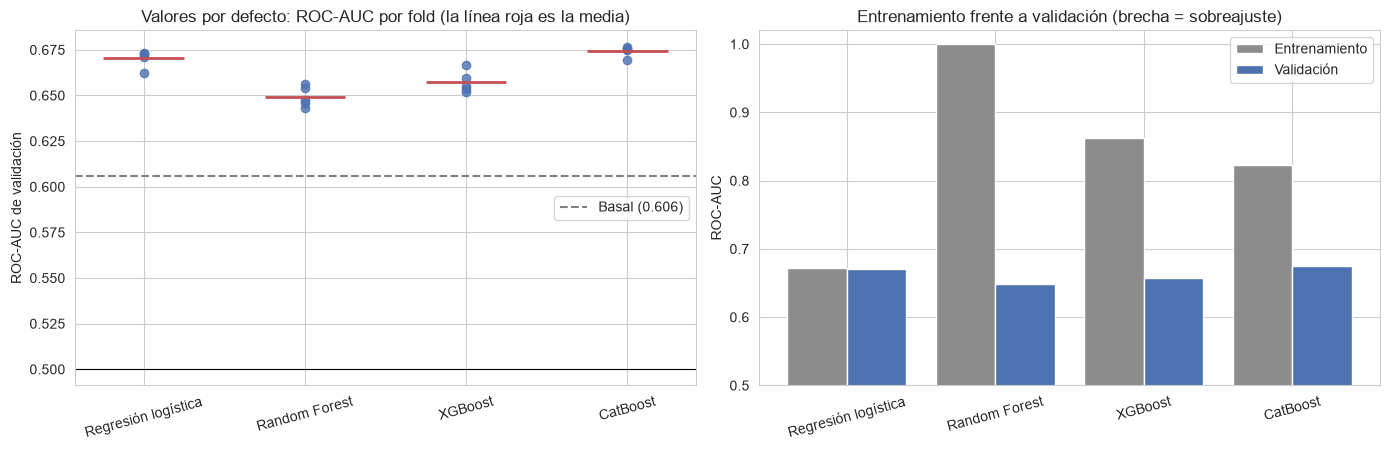

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) ROC-AUC de validación por fold, con el basal como referencia
ax = axes[0]
for i, nombre in enumerate(ALGORITMOS):
    v = m4[m4["algoritmo"] == nombre]["ROC-AUC validación"].to_numpy()
    ax.scatter(np.full(len(v), i), v, color="#4C72B0", alpha=0.8, zorder=3)
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#C44E52", lw=2, zorder=4)
ax.axhline(auc_basal.mean(), color="gray", ls="--", label=f"Basal ({auc_basal.mean():.3f})")
ax.axhline(0.5, color="black", lw=0.8)
ax.set_xticks(range(len(ALGORITMOS)))
ax.set_xticklabels(ALGORITMOS, rotation=15)
ax.set_ylabel("ROC-AUC de validación")
ax.set_title("Valores por defecto: ROC-AUC por fold (la línea roja es la media)")
ax.legend()

# (b) entrenamiento frente a validación
ax = axes[1]
x = np.arange(len(ALGORITMOS))
ax.bar(x - 0.2, resumen_m4["ROC-AUC entrenamiento"], 0.4, label="Entrenamiento", color="#8C8C8C")
ax.bar(x + 0.2, resumen_m4["ROC-AUC validación"], 0.4, label="Validación", color="#4C72B0")
ax.set_xticks(x)
ax.set_xticklabels(ALGORITMOS, rotation=15)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("ROC-AUC")
ax.set_title("Entrenamiento frente a validación (brecha = sobreajuste)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** En el panel izquierdo, la dispersión entre folds de cada algoritmo (unos 0,01 de
punta a punta) es menor que la distancia que los separa del basal: todos los puntos quedan por encima de la
línea del basal y los cuatro algoritmos se separan del piso de 0,5. En el panel derecho, la diferencia entre la
barra gris y la azul es el sobreajuste: casi nula en la regresión logística, enorme en Random Forest y
intermedia en los dos boostings.

## 8.5 M5 — Ajuste de hiperparámetros: carrera de mecanismos

Para cada algoritmo compiten tres mecanismos: **búsqueda de grilla** , **búsqueda
aleatoria** y **Optuna con TPE**. Se queda con el mecanismo que mejor optimice. 

**Pista pareja.** Todos los mecanismos usan, para un mismo algoritmo, el mismo espacio de búsqueda, los mismos
folds (los de M3, semilla 42), la misma métrica (ROC-AUC medio de los 5 folds), la misma semilla y **60 evaluaciones** 
(16 para la regresión logística, cuyo espacio completo tiene solo 16
combinaciones). La grilla recorre todo lo que se le da, así que para igualar el presupuesto se arma **gruesa**:
en Random Forest recorre sus 3 hiperparámetros y en XGBoost y CatBoost recorre 3 y 3 hiperparámetros, con los
demás fijos en valores centrales del espacio (se declara abajo). Es una desventaja de la grilla que la propia
cátedra señala: escala mal cuando hay muchos hiperparámetros.

**Cantidad de árboles.** En XGBoost y CatBoost `n_estimators` no entra en la búsqueda: se fija con
**early stopping** sobre una validación apartada del train de cada fold (20 % de los pacientes, agrupada),
con 50 rondas de paciencia y un máximo de 2.000 árboles en XGBoost y 3.000 en CatBoost. El fold de validación solo
mide el resultado.

**Espacios de búsqueda** (la columna "origen" indica qué sale de la cátedra y qué es conocimiento general):

| Algoritmo | Hiperparámetro | Rango |
|---|---|---|
| Regresión logística | `C` | 1e-4 a 1e2 (log) | 
| | `l1_ratio` | 0 (Ridge) o 1 (Lasso) |
| Random Forest | `max_features` | 0,1 a 0,8 | 
| | `min_samples_leaf` | 1 a 300 (log) | 
| | `max_depth` | 4 a 40 | 
| | `n_estimators` | 500, fijo | 
| XGBoost | `learning_rate` | 0,005 a 0,3 (log) | 
| | `max_depth` | 2 a 8 | 
| | `subsample` | 0,5 a 1 | 
| | `colsample_bytree` | 0,4 a 1 | 
| | `min_child_weight` | 1 a 15 | 
| | `reg_lambda` | 1e-3 a 20 (log) | 
| | `reg_alpha` | 1e-3 a 10 (log) |
| CatBoost | `learning_rate` | 0,02 a 0,3 (log) | 
| | `depth` | 3 a 9 | 
| | `l2_leaf_reg` | 1 a 30 (log) | 
| | `random_strength` | 0,1 a 5 (log) | 

**Grillas.** Regresión logística: 8 valores de `C` por 2 de `l1_ratio` (16). Random Forest: `max_features` en
{0,15, 0,3, 0,5, 0,7}, `min_samples_leaf` en {1, 10, 30, 100, 300} y `max_depth` en {8, 16, 32} (60). XGBoost:
`learning_rate` en {0,02, 0,05, 0,1}, `max_depth` en {2, 3, 4, 6} y `min_child_weight` en {1, 3, 6, 10, 15}, con
`subsample` 0,8, `colsample_bytree` 0,8, `reg_lambda` 1 y `reg_alpha` 0,01 fijos (60). CatBoost:
`learning_rate` en {0,03, 0,06, 0,1}, `depth` en {4, 5, 6, 8} y `l2_leaf_reg` en {1, 3, 6, 12, 30}, con
`random_strength` 1 fijo (60).

**Cómo se decide el ganador.** El mecanismo con mayor ROC-AUC medio. Si la diferencia con otro es menor que el
desvío entre folds del mejor, no se declara ganador por el puntaje: se elige el más barato en tiempo y se
informa el empate. El puntaje de una carrera es optimista, porque el ganador se elige sobre los mismos folds
(la "maldición del ganador" que vimos en la materia con SVM), así que el ganador se vuelve a evaluar con folds de
otras semillas, nunca con el test.

In [83]:
import itertools, pickle
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

EVAL = 60                                   # evaluaciones por mecanismo
PRESUPUESTO = {"Regresión logística": 16, "Random Forest": EVAL, "XGBoost": EVAL, "CatBoost": EVAL}
MECANISMOS = ["Grilla", "Aleatoria", "Optuna (TPE)"]
SEMILLAS_CARRERA = [42]                     # semilla de los mecanismos y de los modelos (la de los folds es 42)
MAX_ARBOLES = {"XGBoost": 2000, "CatBoost": 3000}

ESPACIOS = {
    "Regresión logística": {"C": ("logfloat", 1e-4, 1e2), "l1_ratio": ("cat", [0.0, 1.0])},
    "Random Forest": {"max_features": ("float", 0.1, 0.8), "min_samples_leaf": ("logint", 1, 300),
                      "max_depth": ("int", 4, 40)},
    "XGBoost": {"learning_rate": ("logfloat", 0.005, 0.3), "max_depth": ("int", 2, 8),
                "subsample": ("float", 0.5, 1.0), "colsample_bytree": ("float", 0.4, 1.0),
                "min_child_weight": ("int", 1, 15), "reg_lambda": ("logfloat", 1e-3, 20.0),
                "reg_alpha": ("logfloat", 1e-3, 10.0)},
    "CatBoost": {"learning_rate": ("logfloat", 0.02, 0.3), "depth": ("int", 3, 9),
                 "l2_leaf_reg": ("logfloat", 1.0, 30.0), "random_strength": ("logfloat", 0.1, 5.0)},
}
GRILLAS = {
    "Regresión logística": [dict(C=float(c), l1_ratio=l) for c in np.logspace(-4, 2, 8) for l in (0.0, 1.0)],
    "Random Forest": [dict(max_features=a, min_samples_leaf=b, max_depth=c)
                      for a in (0.15, 0.3, 0.5, 0.7) for b in (1, 10, 30, 100, 300) for c in (8, 16, 32)],
    "XGBoost": [dict(learning_rate=a, max_depth=b, min_child_weight=c, subsample=0.8, colsample_bytree=0.8,
                     reg_lambda=1.0, reg_alpha=0.01)
                for a in (0.02, 0.05, 0.1) for b in (2, 3, 4, 6) for c in (1, 3, 6, 10, 15)],
    "CatBoost": [dict(learning_rate=a, depth=b, l2_leaf_reg=c, random_strength=1.0)
                 for a in (0.03, 0.06, 0.1) for b in (4, 5, 6, 8) for c in (1, 3, 6, 12, 30)],
}
print({n: len(g) for n, g in GRILLAS.items()})


def muestrear(nombre, rng):
    p = {}
    for k, (tipo, *a) in ESPACIOS[nombre].items():
        if tipo == "float":
            p[k] = float(rng.uniform(a[0], a[1]))
        elif tipo == "logfloat":
            p[k] = float(np.exp(rng.uniform(np.log(a[0]), np.log(a[1]))))
        elif tipo == "int":
            p[k] = int(rng.randint(a[0], a[1] + 1))
        elif tipo == "logint":
            p[k] = int(np.clip(round(np.exp(rng.uniform(np.log(a[0]), np.log(a[1])))), a[0], a[1]))
        else:
            p[k] = a[0][rng.randint(len(a[0]))]
    return p


def sugerir(trial, nombre):
    p = {}
    for k, (tipo, *a) in ESPACIOS[nombre].items():
        if tipo == "float":
            p[k] = trial.suggest_float(k, a[0], a[1])
        elif tipo == "logfloat":
            p[k] = trial.suggest_float(k, a[0], a[1], log=True)
        elif tipo == "int":
            p[k] = trial.suggest_int(k, a[0], a[1])
        elif tipo == "logint":
            p[k] = trial.suggest_int(k, a[0], a[1], log=True)
        else:
            p[k] = trial.suggest_categorical(k, a[0])
    return p


_INTERNO = {}


def interno(semilla_cv, k):
    # Validación apartada del train del fold para el early stopping: 20 % de los pacientes.
    if (semilla_cv, k) not in _INTERNO:
        tr, _ = pares(semilla_cv)[k]
        cv_in = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla_cv)
        _INTERNO[(semilla_cv, k)] = next(cv_in.split(np.zeros(len(tr)), y_ent.iloc[tr], groups=pacientes[tr]))
    return _INTERNO[(semilla_cv, k)]


def construir(nombre, p, semilla):
    if nombre == "Regresión logística":
        return LogisticRegression(C=p["C"], l1_ratio=p["l1_ratio"],
                                  solver="saga" if p["l1_ratio"] == 1.0 else "lbfgs", max_iter=3000)
    if nombre == "Random Forest":
        return RandomForestClassifier(n_estimators=500, max_features=p["max_features"],
                                      min_samples_leaf=int(p["min_samples_leaf"]), max_depth=int(p["max_depth"]),
                                      n_jobs=-1, random_state=semilla)
    if nombre == "XGBoost":
        return XGBClassifier(n_estimators=MAX_ARBOLES["XGBoost"], early_stopping_rounds=50, eval_metric="auc",
                             tree_method="hist", n_jobs=-1, random_state=semilla, **p)
    if nombre == "CatBoost":
        return CatBoostClassifier(iterations=MAX_ARBOLES["CatBoost"], early_stopping_rounds=50, eval_metric="AUC",
                                  random_seed=semilla, verbose=0, thread_count=-1, **p)


def evaluar_config(nombre, p, semilla_modelo=SEMILLA, semilla_cv=42):
    # ROC-AUC de validación en los 5 folds de la repetición `semilla_cv` y árboles usados (early stopping).
    aucs, iters = [], []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, semilla_modelo)
        it = np.nan
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                it = m.best_iteration + 1
                pv = m.predict_proba(Zva, iteration_range=(0, it))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                it = m.get_best_iteration() + 1
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        aucs.append(roc_auc_score(yva, pv))
        iters.append(it)
    return np.array(aucs), iters


def log(msg):
    with open(ARTEFACTOS / "m5_progreso.log", "a") as f:
        f.write(f"{time.strftime('%H:%M:%S')}  {msg}\n")


def correr_mecanismo(nombre, mecanismo, semilla):
    presupuesto, filas = PRESUPUESTO[nombre], []

    def evaluar(i, params):
        t0 = time.perf_counter()
        aucs, iters = evaluar_config(nombre, params, semilla)
        filas.append({"algoritmo": nombre, "mecanismo": mecanismo, "semilla": semilla, "evaluacion": i + 1,
                      "parametros": params, "auc_media": float(aucs.mean()), "auc_desvio": float(aucs.std(ddof=1)),
                      "auc_folds": aucs.tolist(), "arboles": iters, "segundos": time.perf_counter() - t0})
        log(f"{nombre} | {mecanismo} | {i+1}/{presupuesto} | AUC {aucs.mean():.4f} | {filas[-1]['segundos']:.1f} s")
        return float(aucs.mean())

    if mecanismo == "Grilla":
        for i, p in enumerate(GRILLAS[nombre][:presupuesto]):      # en la corrida final la grilla ya tiene 'presupuesto' puntos
            evaluar(i, p)
    elif mecanismo == "Aleatoria":
        rng = np.random.RandomState(semilla)
        for i in range(presupuesto):
            evaluar(i, muestrear(nombre, rng))
    else:
        estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=semilla))
        estudio.optimize(lambda t: evaluar(t.number, sugerir(t, nombre)), n_trials=presupuesto)
    return pd.DataFrame(filas)


def carrera(semilla):
    # Resultados guardados en disco: si la carrera ya se corrió, se carga en lugar de recalcularla.
    archivo = ARTEFACTOS / f"m5_carrera_semilla{semilla}.pkl"
    res = pickle.load(open(archivo, "rb")) if archivo.exists() else {}
    for nombre in ALGORITMOS:
        for mec in MECANISMOS:
            if (nombre, mec) not in res:
                log(f"== {nombre} | {mec} | semilla {semilla}: inicio")
                res[(nombre, mec)] = correr_mecanismo(nombre, mec, semilla)
                pickle.dump(res, open(archivo, "wb"))
    return pd.concat(res.values(), ignore_index=True)

{'Regresión logística': 16, 'Random Forest': 60, 'XGBoost': 60, 'CatBoost': 60}


In [84]:
inicio = time.perf_counter()
ensayos = pd.concat([carrera(s) for s in SEMILLAS_CARRERA], ignore_index=True)
for _, r in ensayos.iterrows():
    registrar(fase="M5", algoritmo=r["algoritmo"], mecanismo=r["mecanismo"], semilla=r["semilla"],
              evaluacion=r["evaluacion"], parametros=json.dumps(r["parametros"]), auc_media=r["auc_media"],
              auc_desvio=r["auc_desvio"], segundos=r["segundos"])
ensayos.drop(columns=["parametros", "auc_folds", "arboles"]).to_csv(ARTEFACTOS / "m5_ensayos.csv", index=False)
guardar_registro()


def resumen_carrera(semilla):
    filas = []
    for (nombre, mec), g in ensayos[ensayos["semilla"] == semilla].groupby(["algoritmo", "mecanismo"], sort=False):
        mejor = g.loc[g["auc_media"].idxmax()]
        filas.append({"algoritmo": nombre, "mecanismo": mec, "evaluaciones": len(g),
                      "mejor ROC-AUC (media 5 folds)": mejor["auc_media"], "desvío entre folds": mejor["auc_desvio"],
                      "segundos totales": g["segundos"].sum(), "hiperparámetros": mejor["parametros"]})
    return pd.DataFrame(filas).set_index(["algoritmo", "mecanismo"])


res_carrera = resumen_carrera(SEMILLAS_CARRERA[0])
pd.set_option("display.max_colwidth", 120)
res_carrera.round(4)

evaluaciones  mejor ROC-AUC (media 5 folds)  \
algoritmo           mecanismo                                                   
Regresión logística Grilla                  16                         0.6711   
                    Aleatoria               16                         0.6705   
                    Optuna (TPE)            16                         0.6711   
Random Forest       Grilla                  60                         0.6801   
                    Aleatoria               60                         0.6813   
                    Optuna (TPE)            60                         0.6811   
XGBoost             Grilla                  60                         0.6809   
                    Aleatoria               60                         0.6813   
                    Optuna (TPE)            60                         0.6815   
CatBoost            Grilla                  60                         0.6817   
                    Aleatoria               60                         0.6821   
                    Optuna (TPE)            60                         0.6823   

                                  desvío entre folds  segundos totales  \
algoritmo           mecanismo                                            
Regresión logística Grilla                    0.0042            9.8950   
                    Aleatoria                 0.0050            6.4455   
                    Optuna (TPE)              0.0040            8.5575   
Random Forest       Grilla                    0.0055          819.8706   
                    Aleatoria                 0.0049          807.8094   
                    Optuna (TPE)              0.0048          688.0160   
XGBoost             Grilla                    0.0047          172.9313   
                    Aleatoria                 0.0056          188.2329   
                    Optuna (TPE)              0.0050          338.5340   
CatBoost            Grilla                    0.0045          233.6975   
                    Aleatoria                 0.0043          192.7825   
                    Optuna (TPE)              0.0047          306.7282   

                                                                                                                                          hiperparámetros  
algoritmo           mecanismo                                                                                                                              
Regresión logística Grilla                                                                                  {'C': 0.0007196856730011522, 'l1_ratio': 0.0}  
                    Aleatoria                                                                                {'C': 0.010051981180656781, 'l1_ratio': 1.0}  
                    Optuna (TPE)                                                                            {'C': 0.0003001968983707267, 'l1_ratio': 0.0}  
Random Forest       Grilla                                                                 {'max_features': 0.3, 'min_samples_leaf': 30, 'max_depth': 16}  
                    Aleatoria                                              {'max_features': 0.39638103649445877, 'min_samples_leaf': 10, 'max_depth': 11}  
                    Optuna (TPE)                                            {'max_features': 0.4149670947833069, 'min_samples_leaf': 14, 'max_depth': 10}  
XGBoost             Grilla        {'learning_rate': 0.02, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambd...  
                    Aleatoria     {'learning_rate': 0.03016668475862848, 'max_depth': 8, 'subsample': 0.6254302636733307, 'colsample_bytree': 0.510600...  
                    Optuna (TPE)  {'learning_rate': 0.009840208362044944, 'max_depth': 6, 'subsample': 0.5108524741061474, 'colsample_bytree': 0.82837...  
CatBoost            Grilla                                                 {'learning_rate': 0.03, 'depth': 6, 'l2_leaf_reg': 30, 'random_strength

**Lectura de la carrera.** Los tres mecanismos llegan a puntajes casi idénticos en cada algoritmo: el mejor
ROC-AUC difiere entre mecanismos en 0,0005 a 0,002 en Random Forest, XGBoost y CatBoost, y en 0,0006 en la
regresión logística, siempre por debajo del desvío entre folds (0,004 a 0,006). Ningún mecanismo es
claramente mejor. Los tiempos sí difieren: la regresión logística tarda segundos, XGBoost y CatBoost entre
3 y 6 minutos por mecanismo, y Random Forest entre 11 y 14 minutos.

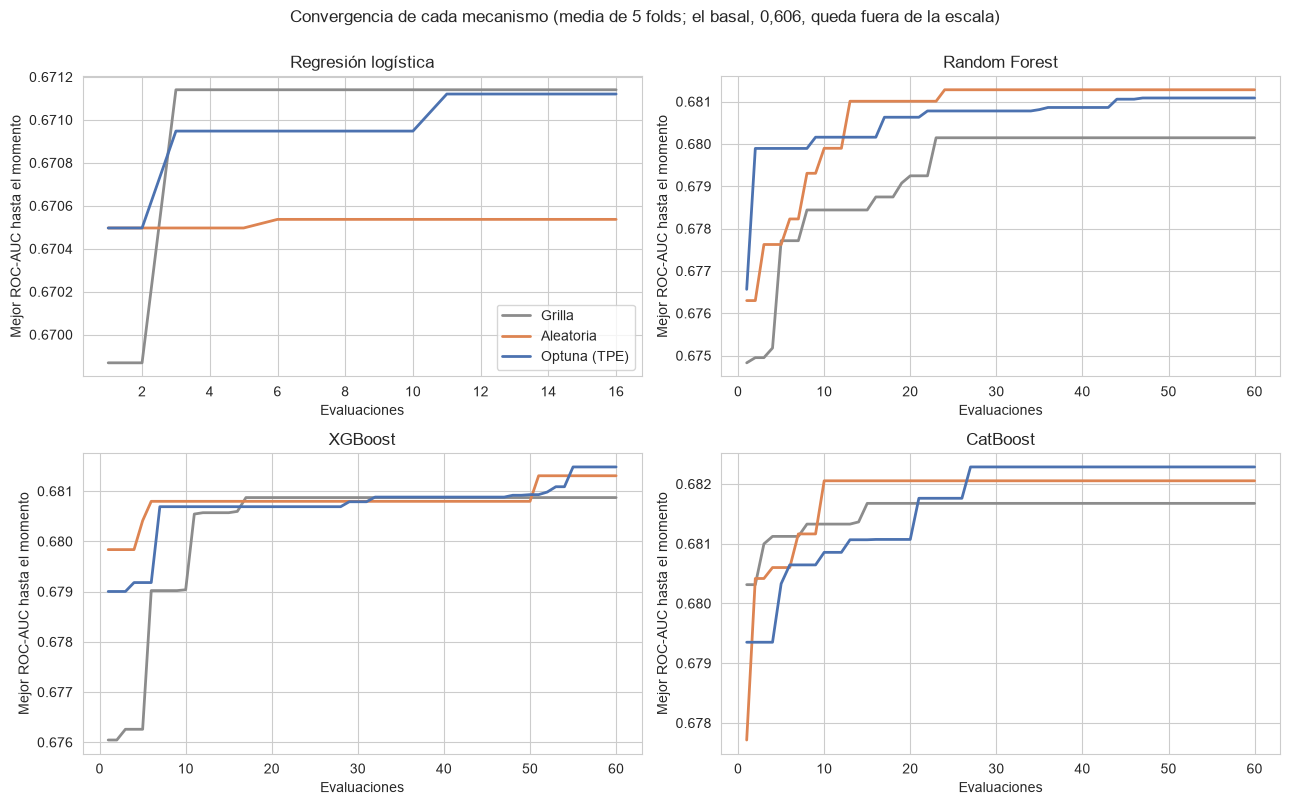

In [85]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
colores = {"Grilla": "#8C8C8C", "Aleatoria": "#DD8452", "Optuna (TPE)": "#4C72B0"}
for ax, nombre in zip(axes.flat, ALGORITMOS):
    for mec in MECANISMOS:
        g = ensayos[(ensayos["algoritmo"] == nombre) & (ensayos["mecanismo"] == mec)
                    & (ensayos["semilla"] == SEMILLAS_CARRERA[0])].sort_values("evaluacion")
        ax.plot(g["evaluacion"], np.maximum.accumulate(g["auc_media"]), label=mec, color=colores[mec], lw=2)
    ax.set_title(nombre)
    ax.set_xlabel("Evaluaciones")
    ax.set_ylabel("Mejor ROC-AUC hasta el momento")
axes[0, 0].legend()
plt.suptitle("Convergencia de cada mecanismo (media de 5 folds; el basal, 0,606, queda fuera de la escala)", y=1.0)
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las curvas suben rápido y se aplanan. Cada mecanismo llega a 0,001 de su mejor valor
entre la evaluación 1 y la 21: en la regresión logística, en las primeras 3; en XGBoost, entre la 5 y la 11;
en Random Forest, entre la 9 y la 20; y en CatBoost, entre la 3 y la 21. Después las mejoras son de milésimas.
Con 60 evaluaciones, Optuna no se despega de la búsqueda aleatoria, lo que concuerda con lo que dice la cátedra
: con pocos hiperparámetros, una búsqueda simple alcanza. La escala del eje está acotada a
propósito para ver las diferencias entre mecanismos; el basal (0,606) queda muy por debajo, y todos los
mecanismos parten muy por encima de él desde la primera evaluación.

In [86]:
filas = []
for nombre in ALGORITMOS:
    g = res_carrera.loc[nombre]
    mejor = g["mejor ROC-AUC (media 5 folds)"].idxmax()
    tope, desvio = g.loc[mejor, "mejor ROC-AUC (media 5 folds)"], g.loc[mejor, "desvío entre folds"]
    empatados = [m for m in g.index if tope - g.loc[m, "mejor ROC-AUC (media 5 folds)"] < desvio]
    ganador = min(empatados, key=lambda m: g.loc[m, "segundos totales"]) if len(empatados) > 1 else mejor
    filas.append({"algoritmo": nombre, "mecanismo con mejor puntaje": mejor,
                  "mecanismos empatados (dentro del desvío)": ", ".join(empatados),
                  "ganador elegido": ganador, "ROC-AUC del ganador": g.loc[ganador, "mejor ROC-AUC (media 5 folds)"],
                  "hiperparámetros": g.loc[ganador, "hiperparámetros"]})
ganadores = pd.DataFrame(filas).set_index("algoritmo")
ganadores.round(4)

,mecanismo con mejor puntaje,mecanismos empatados (dentro del desvío),ganador elegido,ROC-AUC del ganador,hiperparámetros
algoritmo,,,,,
Regresión logística,Grilla,"Grilla, Aleatoria, Optuna (TPE)",Aleatoria,0.6705,"{'C': 0.010051981180656781, 'l1_ratio': 1.0}"
Random Forest,Aleatoria,"Grilla, Aleatoria, Optuna (TPE)",Optuna (TPE),0.6811,"{'max_features': 0.4149670947833069, 'min_samples_leaf': 14, 'max_depth': 10}"
XGBoost,Optuna (TPE),"Grilla, Aleatoria, Optuna (TPE)",Grilla,0.6809,"{'learning_rate': 0.02, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambd..."
CatBoost,Optuna (TPE),"Grilla, Aleatoria, Optuna (TPE)",Aleatoria,0.6821,"{'learning_rate': 0.02385264834812575, 'depth': 6, 'l2_leaf_reg': 24.64598838968805, 'random_strength': 0.9057530099..."


**Lectura de los ganadores.** En los cuatro algoritmos los tres mecanismos quedan empatados, así que, por la
regla declarada, el ganador es el más barato en tiempo: la búsqueda aleatoria para la regresión logística
(0,6705; `C` = 0,010 con penalización Lasso) y para CatBoost (0,6821), Optuna para Random Forest (0,6811;
`max_features` 0,41, `min_samples_leaf` 14, `max_depth` 10) y la grilla para XGBoost (0,6809;
`learning_rate` 0,02, `max_depth` 6, `min_child_weight` 3). Quién gana es consecuencia del empate y no dice
nada sobre el algoritmo. Mecanismos distintos encontraron hiperparámetros muy distintos con el mismo puntaje
(en XGBoost, la grilla eligió profundidad 6 y la aleatoria profundidad 8): el óptimo es una **meseta** y no un
punto único. El early stopping usó unos 150 a 240 árboles por fold con la configuración ganadora de XGBoost y
340 a 560 con la de CatBoost.

In [87]:
# Validación de los ganadores con folds de otras semillas (43 a 45): el puntaje de la carrera es optimista.
filas = []
for nombre in ALGORITMOS:
    p = ganadores.loc[nombre, "hiperparámetros"]
    por_semilla = []
    for s in SEMILLAS_CV[1:]:
        aucs, iters = evaluar_config(nombre, p, SEMILLA, semilla_cv=s)
        por_semilla.append(aucs.mean())
        registrar(fase="M5-validación", algoritmo=nombre, mecanismo=ganadores.loc[nombre, "ganador elegido"],
                  semilla=s, auc_media=float(aucs.mean()), auc_desvio=float(aucs.std(ddof=1)),
                  parametros=json.dumps(p))
    filas.append({"algoritmo": nombre, "ROC-AUC en la carrera (semilla 42)": ganadores.loc[nombre, "ROC-AUC del ganador"],
                  "ROC-AUC en folds de otras semillas (43 a 45)": float(np.mean(por_semilla)),
                  "desvío entre semillas": float(np.std(por_semilla, ddof=1))})
validacion = pd.DataFrame(filas).set_index("algoritmo")
validacion["optimismo de la carrera"] = (validacion["ROC-AUC en la carrera (semilla 42)"]
                                         - validacion["ROC-AUC en folds de otras semillas (43 a 45)"])
guardar_registro()

(ARTEFACTOS / "configuracion_m5.json").write_text(json.dumps({
    "presupuesto": PRESUPUESTO, "mecanismos": MECANISMOS, "semillas_carrera": SEMILLAS_CARRERA,
    "max_arboles": MAX_ARBOLES, "early_stopping_rounds": 50,
    "espacios": {n: {k: list(v) for k, v in e.items()} for n, e in ESPACIOS.items()},
    "ganadores": {n: {"mecanismo": ganadores.loc[n, "ganador elegido"], "hiperparametros": ganadores.loc[n, "hiperparámetros"],
                      "roc_auc_carrera": float(ganadores.loc[n, "ROC-AUC del ganador"])} for n in ALGORITMOS}},
    indent=1, default=float))
print(f"Tiempo total de M5 en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f} min")
validacion.round(4)

Tiempo total de M5 en esta ejecución: 2.4 min


,ROC-AUC en la carrera (semilla 42),ROC-AUC en folds de otras semillas (43 a 45),desvío entre semillas,optimismo de la carrera
algoritmo,,,,
Regresión logística,0.6705,0.6705,0.0001,0.0000
Random Forest,0.6811,0.6811,0.0003,-0.0001
XGBoost,0.6809,0.6812,0.0010,-0.0004
CatBoost,0.6821,0.6831,0.0006,-0.0011


**Lectura de la validación con otras semillas.** Evaluados con folds de otras semillas, los ganadores rinden
prácticamente lo mismo que en la carrera: el optimismo del puntaje (la "maldición del ganador") va de 0,000 a
−0,001, es decir que incluso rinden algo mejor en los folds nuevos, y el desvío entre semillas es de 0,0001 a
0,001. Con 60 evaluaciones sobre espacios de 2 a 7 hiperparámetros y un puntaje en meseta, la elección del
mejor no infla el resultado de manera apreciable.

In [88]:
antes_despues = pd.DataFrame({
    "ROC-AUC con valores por defecto (M4)": resumen_m4["ROC-AUC validación"],
    "ROC-AUC con el ganador de la carrera": ganadores["ROC-AUC del ganador"]})
antes_despues["mejora por el ajuste"] = (antes_despues["ROC-AUC con el ganador de la carrera"]
                                         - antes_despues["ROC-AUC con valores por defecto (M4)"])
antes_despues["ROC-AUC del basal"] = auc_basal.mean()
antes_despues.round(4)

,ROC-AUC con valores por defecto (M4),ROC-AUC con el ganador de la carrera,mejora por el ajuste,ROC-AUC del basal
algoritmo,,,,
Regresión logística,0.6704,0.6705,0.0001,0.6061
Random Forest,0.6493,0.6811,0.0318,0.6061
XGBoost,0.6574,0.6809,0.0235,0.6061
CatBoost,0.6744,0.6821,0.0077,0.6061


**Lectura.** El ajuste ayuda según la familia. Random Forest sube de 0,649 a 0,681 y XGBoost de 0,657 a 0,681,
porque sus valores por defecto sobreajustaban (M4). CatBoost mejora poco, de 0,674 a 0,682, y la regresión
logística no cambia (0,6704 a 0,6705): con 18 variables y 57.000 filas casi no tiene margen de
sobreajuste. Después del ajuste, los tres ensambles quedan entre 0,681 y 0,682, unas 0,011 por encima de la
logística, y todos a unos 0,075 del basal. Si esas diferencias son reales se decide formalmente en M7.

### Estabilidad de la carrera

Como los mecanismos quedaron empatados, la carrera se repite con dos semillas más (43 y 44). Los folds son los
mismos; cambian la semilla de los mecanismos (qué combinaciones prueban la aleatoria y Optuna) y la de los
modelos. Sirve para ver si el resultado depende de la suerte de una corrida.

semilla 42  semilla 43  semilla 44   media  \
algoritmo           mecanismo                                                  
Regresión logística Grilla            0.6711      0.6711      0.6711  0.6711   
                    Aleatoria         0.6705      0.6712      0.6711  0.6710   
                    Optuna (TPE)      0.6711      0.6712      0.6711  0.6711   
Random Forest       Grilla            0.6801      0.6804      0.6803  0.6803   
                    Aleatoria         0.6813      0.6801      0.6811  0.6808   
                    Optuna (TPE)      0.6811      0.6812      0.6811  0.6811   
XGBoost             Grilla            0.6809      0.6805      0.6809  0.6807   
                    Aleatoria         0.6813      0.6810      0.6810  0.6811   
                    Optuna (TPE)      0.6815      0.6810      0.6816  0.6814   
CatBoost            Grilla            0.6817      0.6818      0.6819  0.6818   
                    Aleatoria         0.6821      0.6817      0.6816  0.6818   
                    Optuna (TPE)      0.6823      0.6817      0.6824  0.6821   

                                  desvío entre semillas  
algoritmo           mecanismo                            
Regresión logística Grilla                       0.0000  
                    Aleatoria                    0.0004  
                    Optuna (TPE)                 0.0000  
Random Forest       Grilla                       0.0001  
                    Aleatoria                    0.0006  
                    Optuna (TPE)                 0.0001  
XGBoost             Grilla                       0.0002  
                    Aleatoria                    0.0002  
                    Optuna (TPE)                 0.0003  
CatBoost            Grilla                       0.0001  
                    Aleatoria                    0.0003  
                    Optuna (TPE)                 0.0004

Mejor ROC-AUC de cada carrera (entre los tres mecanismos):


,semilla 42,semilla 43,semilla 44,rango entre semillas
algoritmo,,,,
Regresión logística,0.6711,0.6712,0.6711,0.0001
Random Forest,0.6813,0.6812,0.6811,0.0002
XGBoost,0.6815,0.6810,0.6816,0.0005
CatBoost,0.6823,0.6818,0.6824,0.0006


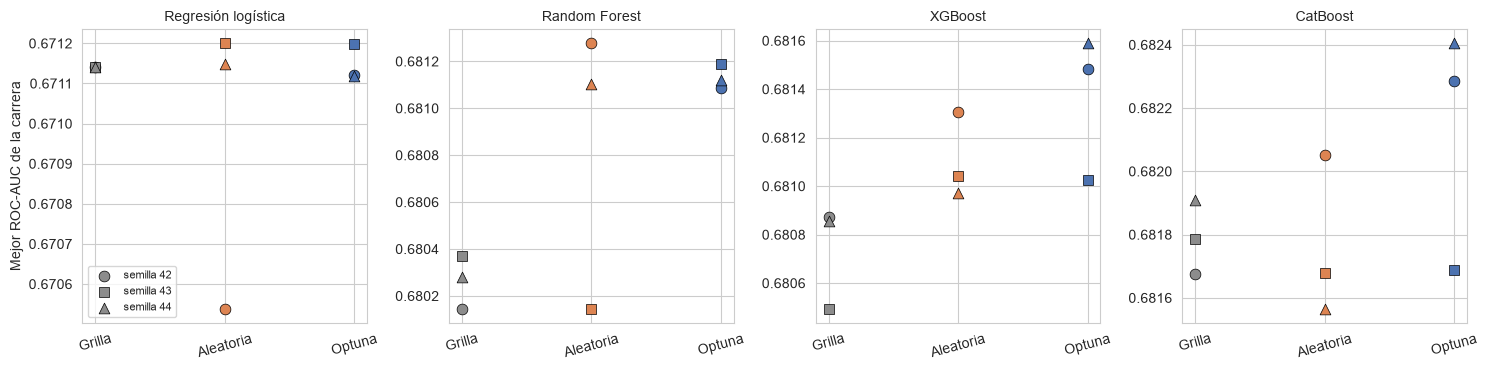

In [89]:
SEMILLAS_ESTABILIDAD = [43, 44]
ensayos_est = pd.concat([carrera(s) for s in SEMILLAS_ESTABILIDAD], ignore_index=True)
for _, r in ensayos_est.iterrows():
    registrar(fase="M5-estabilidad", algoritmo=r["algoritmo"], mecanismo=r["mecanismo"], semilla=r["semilla"],
              evaluacion=r["evaluacion"], parametros=json.dumps(r["parametros"]), auc_media=r["auc_media"],
              auc_desvio=r["auc_desvio"], segundos=r["segundos"])
todos = pd.concat([ensayos, ensayos_est], ignore_index=True)
todos.drop(columns=["parametros", "auc_folds", "arboles"]).to_csv(ARTEFACTOS / "m5_ensayos.csv", index=False)
guardar_registro()

mejor_por_semilla = todos.groupby(["algoritmo", "mecanismo", "semilla"], sort=False)["auc_media"].max().unstack("semilla")
estab = mejor_por_semilla.copy()
estab.columns = [f"semilla {c}" for c in estab.columns]
estab["media"] = mejor_por_semilla.mean(axis=1)
estab["desvío entre semillas"] = mejor_por_semilla.std(axis=1, ddof=1)
display(estab.round(4))

meseta = todos.groupby(["algoritmo", "semilla"], sort=False)["auc_media"].max().unstack("semilla")
meseta.columns = [f"semilla {c}" for c in meseta.columns]
meseta["rango entre semillas"] = meseta.max(axis=1) - meseta.min(axis=1)
print("Mejor ROC-AUC de cada carrera (entre los tres mecanismos):")
display(meseta.round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
marcas = {42: "o", 43: "s", 44: "^"}
for ax, nombre in zip(axes, ALGORITMOS):
    for j, mec in enumerate(MECANISMOS):
        for s in [42, 43, 44]:
            ax.scatter(j, mejor_por_semilla.loc[(nombre, mec), s], marker=marcas[s], color=colores[mec], s=60,
                       label=f"semilla {s}" if j == 0 else None, edgecolor="black", linewidth=0.5)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Grilla", "Aleatoria", "Optuna"], rotation=15)
    ax.set_title(nombre, fontsize=10)
axes[0].set_ylabel("Mejor ROC-AUC de la carrera")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de la estabilidad.** El resultado de la carrera casi no depende de la semilla: el mejor ROC-AUC de cada
algoritmo cambia entre 0,0001 y 0,0006 de una semilla a otra (regresión logística 0,6711 a 0,6712; Random
Forest 0,6811 a 0,6813; XGBoost 0,6810 a 0,6816; CatBoost 0,6817 a 0,6824), mucho menos que el desvío entre
folds (0,004 a 0,006). Con las tres semillas, Optuna queda en promedio algo por encima de los otros mecanismos
en Random Forest, XGBoost y CatBoost, pero por 0,0003 a 0,0008, una diferencia que sigue estando dentro del
ruido; en la regresión logística los tres mecanismos dan lo mismo. Por lo tanto el empate no es una casualidad de
una corrida: en este problema los tres mecanismos llegan a la misma meseta, y el desempeño de cada algoritmo
queda fijado por el algoritmo y no por cómo se buscaron sus hiperparámetros.

## 8.6 M6 — Calibración y umbral

**Calibración: no aplica.** La métrica primaria es el ROC-AUC, que solo usa el orden de los puntajes, y no se
usa la probabilidad como número (no hay valor esperado ni matriz de costos). Los modelos se entrenan sin
pesos de clase, de modo que sus probabilidades siguen reflejando la prevalencia natural, pero no se
interpretan como riesgo individual.

**Umbral.** Recall, precisión, F1 y exactitud balanceada requieren una decisión, y el umbral se trata como un
hiperparámetro que se elige sin mirar el test. Se sigue el método de la cátedra (Clase 5, notebook 1): se
juntan las **predicciones fuera de fold** de todo el train (cada paciente-encuentro predicho por un modelo que
no lo vio), se recorren 181 umbrales entre 0,05 y 0,95, se calcula el F1 en cada uno y se elige el que lo
maximiza. Ese umbral queda fijo y es el que se aplicará una sola vez al test en M9.

Para informar las métricas secundarias con incertidumbre, y sin que el umbral se ajuste sobre los mismos datos
que se evalúan, se usa además un **umbral anidado por fold**: en cada fold el umbral se elige con las
predicciones de los otros cuatro folds y se aplica al fold que quedó afuera. Las predicciones son las del
ganador de la carrera de M5 de cada algoritmo, sobre los folds de la semilla 42.

In [90]:
UMBRALES = np.linspace(0.05, 0.95, 181)
CONFIG_GANADORA = {n: ganadores.loc[n, "hiperparámetros"] for n in ALGORITMOS}


def prob_oof(nombre, p, semilla_cv=42, semilla_modelo=SEMILLA):
    # Probabilidad fuera de fold de cada paciente-encuentro de train, con el modelo ganador (early stopping como en M5).
    oof, arboles = np.full(len(y_ent), np.nan), []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, semilla_modelo)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                arboles.append(m.best_iteration + 1)
                pv = m.predict_proba(Zva, iteration_range=(0, arboles[-1]))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                arboles.append(m.get_best_iteration() + 1)
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        oof[pares(semilla_cv)[k][1]] = pv
    assert not np.isnan(oof).any()
    return oof, arboles


OOF, ARBOLES = {}, {}
for nombre in ALGORITMOS:
    OOF[nombre], ARBOLES[nombre] = prob_oof(nombre, CONFIG_GANADORA[nombre])


def curva_f1(y, p):
    return np.array([f1_score(y, (p >= u).astype(int), zero_division=0) for u in UMBRALES])


ids_fold = FOLD_ID[42]
filas, curvas = [], {}
for nombre in ALGORITMOS:
    p = OOF[nombre]
    curvas[nombre] = curva_f1(y_ent, p)
    u_final = UMBRALES[int(np.argmax(curvas[nombre]))]
    por_fold = []
    for k in range(N_FOLDS):
        fuera, dentro = ids_fold != k, ids_fold == k
        u_k = UMBRALES[int(np.argmax(curva_f1(y_ent[fuera], p[fuera])))]       # umbral anidado: sin el fold k
        pred = (p[dentro] >= u_k).astype(int)
        m = metricas(y_ent[dentro], p[dentro], pred)
        por_fold.append({**m, "umbral": u_k})
        registrar(fase="M6", algoritmo=nombre, semilla=42, fold=k + 1, **m, umbral=u_k)
    d = pd.DataFrame(por_fold)
    fila = {"algoritmo": nombre, "umbral elegido (todo train)": u_final}
    for c in ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]:
        fila[f"{c}"] = f"{d[c].mean():.3f} ± {d[c].std():.3f}"
    filas.append(fila)
umbrales_m6 = pd.DataFrame(filas).set_index("algoritmo")

# Basal y prevalencia: sin umbral que elegir (regla fija de M1)
fila_basal = {"umbral elegido (todo train)": "regla fija (≥ 1 internación previa)"}
fila_prev = {"umbral elegido (todo train)": "—"}
for c in ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]:
    fila_basal[c] = f"{basal_folds[c].mean():.3f} ± {basal_folds[c].std():.3f}"
    fila_prev[c] = f"{prev_folds[c].mean():.3f}"
umbrales_m6.loc["Basal (tabla number_inpatient_disc)"] = fila_basal
umbrales_m6.loc["Prevalencia (referencia)"] = fila_prev
guardar_registro()
(ARTEFACTOS / "umbrales.json").write_text(json.dumps(
    {n: float(UMBRALES[int(np.argmax(curvas[n]))]) for n in ALGORITMOS}, indent=1))
umbrales_m6

,umbral elegido (todo train),ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
algoritmo,,,,,,,
Regresión logística,0.13,0.671 ± 0.005,0.204 ± 0.003,0.437 ± 0.012,0.208 ± 0.004,0.281 ± 0.004,0.612 ± 0.004
Random Forest,0.15,0.681 ± 0.005,0.223 ± 0.007,0.448 ± 0.035,0.212 ± 0.005,0.287 ± 0.003,0.618 ± 0.006
XGBoost,0.145,0.681 ± 0.005,0.221 ± 0.003,0.456 ± 0.020,0.210 ± 0.004,0.287 ± 0.002,0.619 ± 0.003
CatBoost,0.145,0.682 ± 0.004,0.222 ± 0.006,0.447 ± 0.029,0.211 ± 0.007,0.286 ± 0.002,0.617 ± 0.003
Basal (tabla number_inpatient_disc),regla fija (≥ 1 internación previa),0.606 ± 0.004,0.161 ± 0.003,0.502 ± 0.009,0.167 ± 0.003,0.250 ± 0.004,0.592 ± 0.004
Prevalencia (referencia),—,0.500,0.113,0.000,0.000,0.000,0.500


**Lectura de la tabla.** Los umbrales elegidos con las predicciones fuera de fold quedan entre 0,13 y 0,15, muy
por debajo de 0,5, como corresponde a un problema con 11 % de positivos y modelos sin pesos de clase. Con el
umbral anidado (elegido sin el fold que se evalúa), los cuatro algoritmos logran un F1 de 0,281 a 0,287, un
recall de 0,44 a 0,46, una precisión de 0,21 y una exactitud balanceada de 0,61 a 0,62. El basal marca a todo
paciente con alguna internación previa (un 34 % del train) y obtiene F1 0,250, recall 0,50 y precisión 0,167.
Frente al basal, los algoritmos ganan unas 0,04 de precisión y unas 0,03 de F1, a costa de unas 0,05 de
recall. Entre los cuatro algoritmos las diferencias son de milésimas, menores que los desvíos entre folds. El
AUC-PR del Random Forest, XGBoost y CatBoost (0,221 a 0,223) supera al de la regresión logística (0,204) y casi
duplica la prevalencia (0,113).

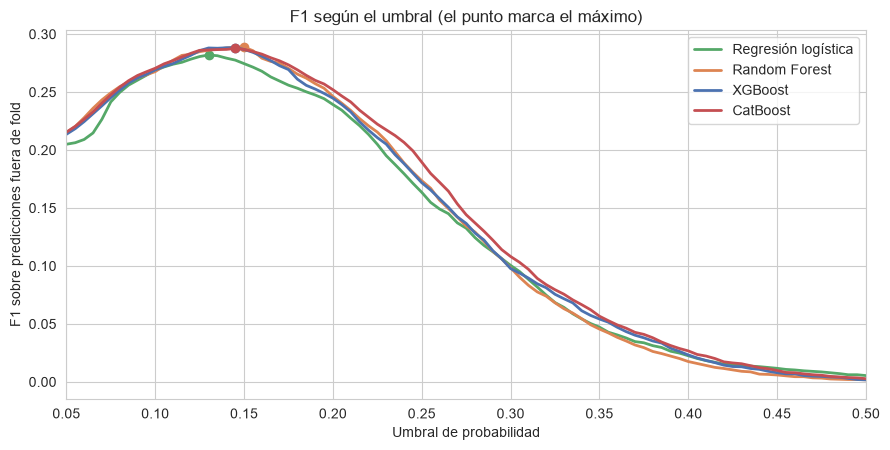

In [91]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colores_alg = {"Regresión logística": "#55A868", "Random Forest": "#DD8452", "XGBoost": "#4C72B0", "CatBoost": "#C44E52"}
for nombre in ALGORITMOS:
    ax.plot(UMBRALES, curvas[nombre], label=nombre, color=colores_alg[nombre], lw=2)
    u = UMBRALES[int(np.argmax(curvas[nombre]))]
    ax.plot(u, curvas[nombre].max(), "o", color=colores_alg[nombre])
ax.set_xlim(0.05, 0.5)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("F1 sobre predicciones fuera de fold")
ax.set_title("F1 según el umbral (el punto marca el máximo)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las curvas de F1 de los cuatro algoritmos casi se superponen. El F1 sube hasta un
máximo de unos 0,28 a 0,29 entre los umbrales 0,13 y 0,15, y baja lentamente: cerca del máximo la curva es
plana, de modo que un umbral algo distinto daría resultados parecidos. Con el corte habitual de 0,5 el F1 sería
prácticamente cero, porque casi ningún paciente supera ese valor; por eso el umbral tiene que moverse.

## 8.7 M7 — Comparación de modelos

Los cuatro algoritmos, con los hiperparámetros ganadores de M5, y el basal se evalúan en **20 folds**: las cuatro
repeticiones de 5 folds (semillas 42 a 45), todas sobre el train. Para cada algoritmo se informa la media y el
desvío de cada métrica, y se comparan de a pares con una **prueba t pareada corregida** para validación
cruzada repetida (Nadeau y Bengio, 2003). La corrección es necesaria porque los folds comparten datos de
entrenamiento y no son independientes; una prueba t común sería demasiado optimista. La prueba pareada y la
corrección son conocimiento general, no de la cátedra.

**Regla de elección explícita** (conocimiento general): entre los modelos cuya mejora sobre el basal es
significativa, se elige el más simple que quede dentro de un error estándar del mejor, ordenando la
simplicidad de menor a mayor: regresión logística, Random Forest, XGBoost, CatBoost. La cátedra advierte que
no se declara un ganador por la tercera cifra decimal y que lo sólido es la diferencia entre familias.

In [92]:
from scipy import stats as sps


def metricas_folds(nombre, p, semilla_cv):
    # ROC-AUC y AUC-PR de validación en los 5 folds de una repetición, con la configuración ganadora.
    res = []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, SEMILLA)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                pv = m.predict_proba(Zva, iteration_range=(0, m.best_iteration + 1))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        res.append({"ROC-AUC": roc_auc_score(yva, pv), "AUC-PR": average_precision_score(yva, pv)})
    return res


filas = []
for semilla in SEMILLAS_CV:
    for nombre in ALGORITMOS:
        for k, r in enumerate(metricas_folds(nombre, CONFIG_GANADORA[nombre], semilla)):
            filas.append({"modelo": nombre, "semilla": semilla, "fold": k + 1, **r})
    for k, (tr, va) in enumerate(pares(semilla)):                 # basal en los mismos folds
        _, s_va = puntaje_tabla(VAR_BASAL, tr, va)
        filas.append({"modelo": "Basal", "semilla": semilla, "fold": k + 1,
                      "ROC-AUC": roc_auc_score(y_ent.iloc[va], s_va),
                      "AUC-PR": average_precision_score(y_ent.iloc[va], s_va)})
folds20 = pd.DataFrame(filas)
for _, r in folds20.iterrows():
    registrar(fase="M7", algoritmo=r["modelo"], semilla=r["semilla"], fold=r["fold"],
              **{"ROC-AUC": r["ROC-AUC"], "AUC-PR": r["AUC-PR"]})
guardar_registro()
folds20.to_csv(ARTEFACTOS / "m7_folds.csv", index=False)

MODELOS = ["Basal"] + ALGORITMOS
roc = folds20.pivot_table(index=["semilla", "fold"], columns="modelo", values="ROC-AUC")[MODELOS]
apr = folds20.pivot_table(index=["semilla", "fold"], columns="modelo", values="AUC-PR")[MODELOS]
N = len(roc)                                                      # 20 folds (4 repeticiones x 5)
FACTOR = 1.0 / N + 1.0 / (N_FOLDS - 1)                            # corrección de Nadeau y Bengio: 1/n + n_test/n_train


def t_corregida(d):
    t = d.mean() / np.sqrt(FACTOR * d.var(ddof=1))
    return t, 2 * sps.t.sf(abs(t), df=N - 1)


tabla_m7 = pd.DataFrame({
    "ROC-AUC (media ± desvío, 20 folds)": [f"{roc[m].mean():.4f} ± {roc[m].std():.4f}" for m in MODELOS],
    "AUC-PR (media ± desvío)": [f"{apr[m].mean():.4f} ± {apr[m].std():.4f}" for m in MODELOS],
    "mejora de ROC-AUC sobre el basal": [np.nan] + [(roc[m] - roc["Basal"]).mean() for m in ALGORITMOS],
    "p (t pareada corregida) vs. basal": [""] + [f"{t_corregida(roc[m] - roc['Basal'])[1]:.1e}" for m in ALGORITMOS],
}, index=MODELOS)
tabla_m7["mejora de ROC-AUC sobre el basal"] = tabla_m7["mejora de ROC-AUC sobre el basal"].round(4)
tabla_m7

,"ROC-AUC (media ± desvío, 20 folds)",AUC-PR (media ± desvío),mejora de ROC-AUC sobre el basal,p (t pareada corregida) vs. basal
Basal,0.6061 ± 0.0057,0.1609 ± 0.0034,NaN,
Regresión logística,0.6705 ± 0.0063,0.2046 ± 0.0050,0.0644,9.2e-15
Random Forest,0.6811 ± 0.0063,0.2212 ± 0.0073,0.0750,4.3e-16
XGBoost,0.6811 ± 0.0063,0.2218 ± 0.0071,0.0751,1.2e-15
CatBoost,0.6828 ± 0.0062,0.2235 ± 0.0066,0.0768,2.1e-16


**Lectura de la tabla.** Los cuatro algoritmos superan al basal por entre 0,064 y 0,077 de ROC-AUC, con
diferencias significativas en todos los casos (p corregido menor que 1e-8). Los tres ensambles quedan juntos
(0,6811 para Random Forest y XGBoost, 0,6828 para CatBoost) y la regresión logística unos 0,011 a 0,012 por
debajo (0,6705). El AUC-PR sigue el mismo orden (0,205, 0,221, 0,222 y 0,224).

Diferencia media de ROC-AUC (fila menos columna):


,Regresión logística,Random Forest,XGBoost,CatBoost
Regresión logística,NaN,-0.0106,-0.0106,-0.0123
Random Forest,0.0106,NaN,-0.0000,-0.0017
XGBoost,0.0106,0.0000,NaN,-0.0017
CatBoost,0.0123,0.0017,0.0017,NaN


p de la prueba t pareada corregida:


,Regresión logística,Random Forest,XGBoost,CatBoost
Regresión logística,,2.03e-07,2.26e-05,5.56e-08
Random Forest,2.03e-07,,0.988,0.0919
XGBoost,2.26e-05,0.988,,0.0993
CatBoost,5.56e-08,0.0919,0.0993,


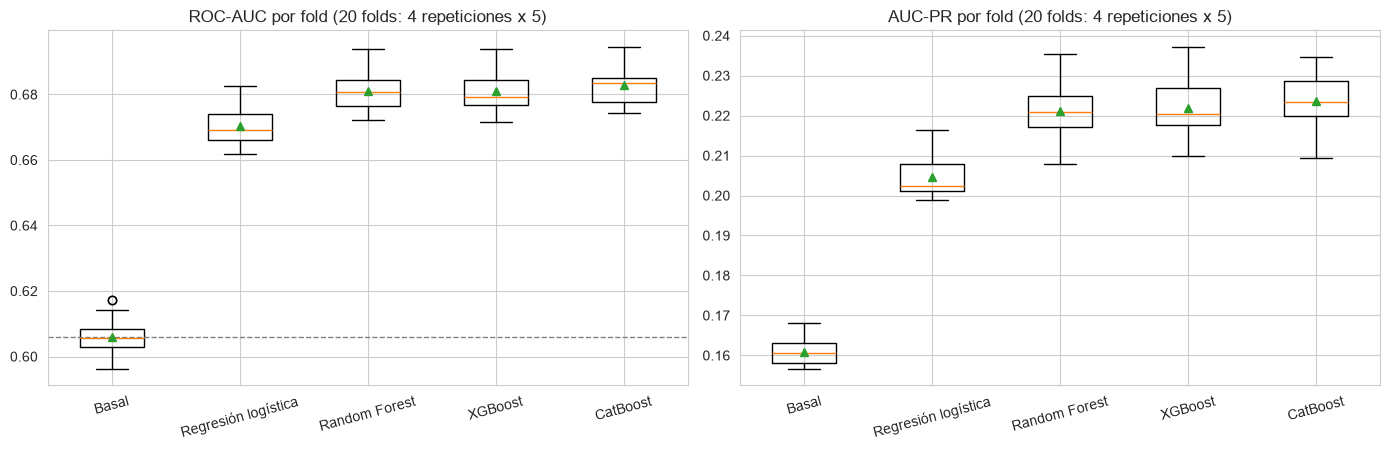

In [93]:
# Comparaciones de a pares entre algoritmos (ROC-AUC): diferencia media (fila menos columna) y p corregido
dif_media = pd.DataFrame(index=ALGORITMOS, columns=ALGORITMOS, dtype=float)
p_val = pd.DataFrame(index=ALGORITMOS, columns=ALGORITMOS, dtype=float)
for a in ALGORITMOS:
    for b in ALGORITMOS:
        if a != b:
            d = roc[a] - roc[b]
            dif_media.loc[a, b], p_val.loc[a, b] = d.mean(), t_corregida(d)[1]
print("Diferencia media de ROC-AUC (fila menos columna):")
display(dif_media.round(4))
print("p de la prueba t pareada corregida:")
display(p_val.map(lambda x: "" if pd.isna(x) else f"{x:.3g}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, tabla, titulo in zip(axes, [roc, apr], ["ROC-AUC", "AUC-PR"]):
    ax.boxplot([tabla[m] for m in MODELOS], tick_labels=MODELOS, showmeans=True)
    ax.set_title(f"{titulo} por fold (20 folds: 4 repeticiones x 5)")
    ax.tick_params(axis="x", rotation=15)
axes[0].axhline(roc["Basal"].mean(), color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()

**Lectura de las comparaciones.** La regresión logística es peor que los tres ensambles, con una diferencia
de 0,011 a 0,012 que es significativa (p < 0,001 en las tres comparaciones). Entre los ensambles no hay
diferencias significativas: Random Forest y XGBoost son prácticamente idénticos (diferencia de 0,0000, p = 0,99) y
CatBoost se adelanta por 0,0017 (p = 0,09 frente a Random Forest y 0,10 frente a XGBoost), por encima del
umbral convencional de 0,05. En los boxplots, las cajas de los tres ensambles se superponen casi por completo,
están claramente por encima de la regresión logística, y ninguna toca al basal. La dispersión entre folds
(unos 0,006) es mayor que la distancia entre ensambles (0,002 como máximo).

In [94]:
# Regla de elección: entre los modelos que superan significativamente al basal, el más simple dentro de
# un error estándar del mejor (error estándar de la media de 20 folds, con la corrección de Nadeau y Bengio).
orden_simplicidad = ["Regresión logística", "Random Forest", "XGBoost", "CatBoost"]
medias = roc[ALGORITMOS].mean()
mejor = medias.idxmax()
ee_mejor = float(np.sqrt(FACTOR * roc[mejor].var(ddof=1)))
dentro = [m for m in orden_simplicidad if medias[mejor] - medias[m] <= ee_mejor]
elegido = dentro[0]
print(f"Mejor ROC-AUC medio: {mejor} ({medias[mejor]:.4f}); error estándar corregido: {ee_mejor:.4f}")
print("Modelos dentro de un error estándar del mejor:", dentro)
print(f"Modelo elegido por la regla (el más simple de ese grupo): {elegido}")

Mejor ROC-AUC medio: CatBoost (0.6828); error estándar corregido: 0.0034
Modelos dentro de un error estándar del mejor: ['Random Forest', 'XGBoost', 'CatBoost']
Modelo elegido por la regla (el más simple de ese grupo): Random Forest


**Lectura de la regla de elección.** El mejor ROC-AUC medio es el de CatBoost (0,6828), con un error estándar
corregido de 0,0034. Dentro de ese margen quedan Random Forest, XGBoost y CatBoost, y la regla elige el más
simple de ellos: **Random Forest**. La regresión logística (0,6705, a 0,012 del mejor) queda fuera. Como la
diferencia entre los tres ensambles no es estadísticamente significativa, que se elija Random Forest es
consecuencia de la regla de parsimonia y no de una ventaja demostrada: CatBoost y XGBoost serían igualmente
defendibles. Los cuatro algoritmos se evalúan en M9 con sus configuraciones ya congeladas.

## 8.8 M8 — Interpretabilidad y diagnóstico de errores

Todo se calcula **sobre train y fuera de fold**, sin usar el test. La importancia de las variables es la de
**permutación**, que sirve para cualquier algoritmo (Clase 5, notebooks 2 y 3): se desordena una variable en el
fold de validación, se rompe su relación con el target y se mide cuánto cae el ROC-AUC. Como las variables
categóricas con one-hot ocupan varias columnas, las columnas de una misma variable se permutan **juntas**, de
modo que el resultado es una importancia por cada una de las 18 variables del EDA y no por columna. La caída se
promedia en los 5 folds de la semilla 42 y en 5 repeticiones por fold. Se calcula para el modelo elegido en M7
(Random Forest) y para el de mayor ROC-AUC medio (CatBoost). Como la cátedra advierte, la importancia por
permutación reparte el crédito entre variables correlacionadas, así que un valor bajo no significa que la
variable no sirva. Para la regresión logística se muestran los coeficientes, que son interpretables
directamente porque las columnas están estandarizadas.

In [95]:
niveles_ohe = [sorted(str(v) for v in Xm_train[c].cat.categories) for c in VARS_OHE]
NOMBRES_COLS = (VARS_NUM + [c + "_ord" for c in VARS_ORD] + [c + "_te" for c in VARS_TE]
                + [f"{c}_{lv}" for c, niv in zip(VARS_OHE, niveles_ohe) for lv in niv
                   if not (c == "familia_biguanidas" and lv == "Steady")])
GRUPOS_VAR = {}
for v in VARS_NUM:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v)]
for v in VARS_ORD:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v + "_ord")]
for v in VARS_TE:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v + "_te")]
for v in VARS_OHE:
    GRUPOS_VAR[v] = [i for i, n in enumerate(NOMBRES_COLS) if n.startswith(v + "_")]
assert sorted(i for g in GRUPOS_VAR.values() for i in g) == list(range(26))


def ajustar_fold(nombre, k, semilla_cv=42):
    # Modelo ganador ajustado con el train del fold k (con early stopping en los boosting) y su función de predicción.
    Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
    m = construir(nombre, CONFIG_GANADORA[nombre], SEMILLA)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if nombre == "XGBoost":
            a, b = interno(semilla_cv, k)
            m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
            it = m.best_iteration + 1
            return m, (lambda Z: m.predict_proba(Z, iteration_range=(0, it))[:, 1]), Zva, yva
        if nombre == "CatBoost":
            a, b = interno(semilla_cv, k)
            m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
        else:
            m.fit(Ztr, ytr)
    return m, (lambda Z: m.predict_proba(Z)[:, 1]), Zva, yva


def importancia_grupos(predecir, Zva, yva, n_rep, rng):
    base = roc_auc_score(yva, predecir(Zva))
    out = {}
    for var, idx in GRUPOS_VAR.items():
        caidas = []
        for _ in range(n_rep):
            perm = rng.permutation(len(yva))
            Zp = Zva.copy()
            Zp[:, idx] = Zva[perm][:, idx]
            caidas.append(base - roc_auc_score(yva, predecir(Zp)))
        out[var] = float(np.mean(caidas))
    return out


imp = {}
for nombre in ["Random Forest", "CatBoost"]:
    rng = np.random.RandomState(SEMILLA)
    por_fold = []
    for k in range(N_FOLDS):
        _, predecir, Zva, yva = ajustar_fold(nombre, k)
        por_fold.append(importancia_grupos(predecir, Zva, yva, 5, rng))
    imp[nombre] = pd.DataFrame(por_fold)
tabla_imp = pd.DataFrame({
    "Random Forest: caída media de ROC-AUC": imp["Random Forest"].mean(),
    "Random Forest: desvío entre folds": imp["Random Forest"].std(),
    "CatBoost: caída media de ROC-AUC": imp["CatBoost"].mean(),
    "CatBoost: desvío entre folds": imp["CatBoost"].std()}).sort_values(
        "Random Forest: caída media de ROC-AUC", ascending=False)
for nombre in imp:
    for v, val in imp[nombre].mean().items():
        registrar(fase="M8", algoritmo=nombre, variable=v, caida_roc_auc=float(val))
guardar_registro()
tabla_imp.round(4)

,Random Forest: caída media de ROC-AUC,Random Forest: desvío entre folds,CatBoost: caída media de ROC-AUC,CatBoost: desvío entre folds
discharge_disposition_id,0.0602,0.0061,0.0571,0.0060
number_inpatient_disc,0.0426,0.0042,0.0349,0.0038
patient_nbr_ordinal,0.0273,0.0024,0.0220,0.0031
number_emergency_disc,0.0031,0.0010,0.0039,0.0012
age,0.0030,0.0004,0.0018,0.0007
number_diagnoses,0.0027,0.0003,0.0022,0.0006
payer_code,0.0024,0.0006,0.0033,0.0007
medical_specialty,0.0024,0.0004,0.0023,0.0011
time_in_hospital,0.0020,0.0005,0.0017,0.0008
diag_1,0.0014,0.0004,0.0019,0.0005


**Lectura de la tabla.** Tres variables concentran la importancia en los dos modelos y en el mismo orden: el
tipo de alta (`discharge_disposition_id`, con una caída del ROC-AUC de 0,060 en Random Forest y 0,057 en
CatBoost), las internaciones previas del último año (`number_inpatient_disc`, 0,043 y 0,035) y los encuentros
previos del paciente (`patient_nbr_ordinal`, 0,027 y 0,022). Las otras 15 variables aportan menos de 0,005 cada
una. Esto coincide con el EDA (V de Cramér e información mutua, secciones 3.6 y 6.1) y con los coeficientes de la
regresión logística (abajo). La variable dominante, el tipo de alta, se conoce al alta, de modo que es coherente
con el momento de predicción declarado y no es una fuga. Como la permutación reparte el crédito entre
variables correlacionadas, el valor bajo de una variable no prueba que no sirva.

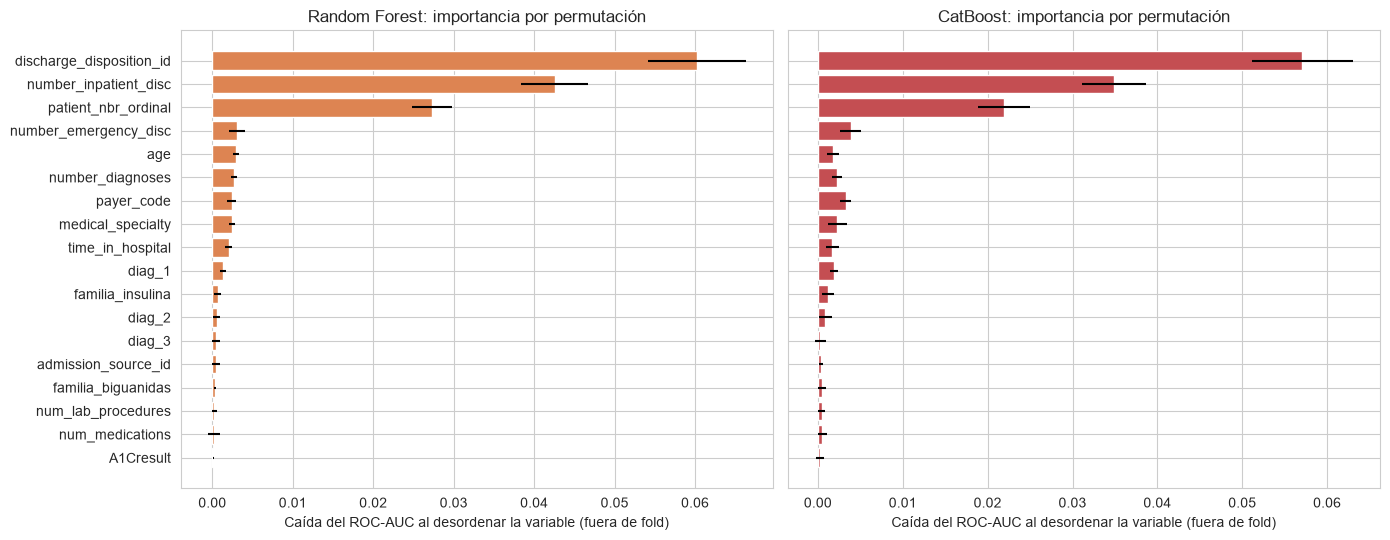

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
orden = tabla_imp.index[::-1]
for ax, nombre, color in zip(axes, ["Random Forest", "CatBoost"], ["#DD8452", "#C44E52"]):
    ax.barh(orden, tabla_imp.loc[orden, f"{nombre}: caída media de ROC-AUC"],
            xerr=tabla_imp.loc[orden, f"{nombre}: desvío entre folds"], color=color)
    ax.set_title(f"{nombre}: importancia por permutación")
    ax.set_xlabel("Caída del ROC-AUC al desordenar la variable (fuera de fold)")
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Los dos modelos muestran la misma forma: tres barras claramente más largas que el
resto, cuyas barras de error (el desvío entre folds) no se solapan con las de las demás variables. Entre el
cuarto lugar y el último, las diferencias son de milésimas y quedan dentro del ruido entre folds.

In [97]:
# Regresión logística ganadora: coeficientes promedio de los 5 folds (columnas estandarizadas)
coefs = []
for k in range(N_FOLDS):
    m, _, _, _ = ajustar_fold("Regresión logística", k)
    coefs.append(m.coef_[0])
coefs = pd.DataFrame(coefs, columns=NOMBRES_COLS)
tabla_coef = pd.DataFrame({"coeficiente medio": coefs.mean(), "desvío entre folds": coefs.std()})
tabla_coef = tabla_coef.reindex(tabla_coef["coeficiente medio"].abs().sort_values(ascending=False).index)
print(f"Coeficientes distintos de cero: {(tabla_coef['coeficiente medio'].abs() > 1e-9).sum()} de {len(tabla_coef)} "
      f"(penalización {'Lasso' if CONFIG_GANADORA['Regresión logística']['l1_ratio'] == 1.0 else 'Ridge'}, "
      f"C = {CONFIG_GANADORA['Regresión logística']['C']:.3g})")
tabla_coef.head(12).round(4)

Coeficientes distintos de cero: 23 de 26 (penalización Lasso, C = 0.0101)


,coeficiente medio,desvío entre folds
discharge_disposition_id_te,0.2929,0.0079
number_inpatient_disc_ord,0.2593,0.0071
patient_nbr_ordinal_ord,0.1043,0.0112
number_emergency_disc_ord,0.0743,0.0059
medical_specialty_te,0.0647,0.0151
familia_insulina_No,-0.0369,0.0057
number_diagnoses,0.0303,0.0112
familia_insulina_Down,0.0238,0.0034
diag_1_te,0.0207,0.0104
A1Cresult_No medido,0.0153,0.0063


**Lectura de los coeficientes.** La regresión logística ganadora usa penalización Lasso (`C` = 0,0101) y
conserva 23 de los 26 coeficientes, de modo que la regularización casi no elimina variables. Los más grandes
son positivos (aumentan el riesgo) y son los mismos tres que dominan en los ensambles: el tipo de alta
codificado (0,293), las internaciones previas (0,259) y los encuentros previos (0,104), seguidos de las visitas
de urgencia (0,074) y la especialidad médica (0,065). Los demás coeficientes son menores o iguales a 0,04; el
único negativo del grupo, `familia_insulina_No` (−0,037), indica que no recibir insulina se asocia a menor riesgo.

### Errores por subgrupos

Se analizan las predicciones fuera de fold del modelo elegido (Random Forest) por grupos de pacientes que son
relevantes para el problema. En cada uno se informa el tamaño, la tasa de reingreso, el ROC-AUC y, con el
umbral de M6, el recall y la precisión. Un grupo con ROC-AUC muy distinto del global señala dónde el modelo
funciona peor.

In [98]:
modelo_sub = "Random Forest"
p_sub = OOF[modelo_sub]
u_sub = float(UMBRALES[int(np.argmax(curvas[modelo_sub]))])
bandas = {"[0-10)": "menores de 30", "[10-20)": "menores de 30", "[20-30)": "menores de 30",
          "[30-40)": "30 a 59", "[40-50)": "30 a 59", "[50-60)": "30 a 59",
          "[60-70)": "60 a 79", "[70-80)": "60 a 79", "[80-90)": "80 o más", "[90-100)": "80 o más"}
top_alta = X_train["discharge_disposition_id"].astype(object).value_counts().head(5).index
subgrupos = {
    "edad": X_train["age"].astype(object).map(bandas),
    "internaciones previas": X_train["number_inpatient_disc"].astype(object),
    "tipo de alta": X_train["discharge_disposition_id"].astype(object).where(
        X_train["discharge_disposition_id"].astype(object).isin(top_alta), "otros tipos de alta"),
    "sexo": X_train["gender"].astype(object),
}
filas = []
for grupo, serie in subgrupos.items():
    for nivel in sorted(serie.dropna().unique()):
        m = (serie == nivel).to_numpy()
        yy, pp = y_ent[m], p_sub[m]
        fila = {"grupo": grupo, "nivel": nivel if len(str(nivel)) < 45 else str(nivel)[:42] + "...",
                "pacientes-encuentros": int(m.sum()), "tasa de reingreso": float(yy.mean())}
        if yy.nunique() == 2:
            pred = (pp >= u_sub).astype(int)
            fila.update({"ROC-AUC": roc_auc_score(yy, pp), "recall": recall_score(yy, pred),
                         "precisión": precision_score(yy, pred, zero_division=0)})
        filas.append(fila)
tabla_sub = pd.DataFrame(filas).set_index(["grupo", "nivel"])
print(f"{modelo_sub}: umbral {u_sub:.2f}; ROC-AUC fuera de fold en todo train: {roc_auc_score(y_ent, p_sub):.4f}")
tabla_sub.round(3)

Random Forest: umbral 0.15; ROC-AUC fuera de fold en todo train: 0.6808


pacientes-encuentros  \
grupo                 nivel                                                                 
edad                  30 a 59                                                       21474   
                      60 a 79                                                       34164   
                      80 o más                                                      14124   
                      menores de 30                                                  1821   
internaciones previas 0                                                             47335   
                      1                                                             13777   
                      2                                                              5377   
                      3 o mas                                                        5094   
tipo de alta          Discharged to home                                            42343   
                      Discharged/transferred to SNF                                  9855   
                      Discharged/transferred to another short te...                  1537   
                      Discharged/transferred to home with home h...                  9038   
                      NULL                                                           2562   
                      otros tipos de alta                                            6248   
sexo                  Female                                                        38455   
                      Male                                                          33128   

                                                                     tasa de reingreso  \
grupo                 nivel                                                              
edad                  30 a 59                                                    0.100   
                      60 a 79                                                    0.117   
                      80 o más                                                   0.121   
                      menores de 30                                              0.125   
internaciones previas 0                                                          0.085   
                      1                                                          0.130   
                      2                                                          0.172   
                      3 o mas                                                    0.261   
tipo de alta          Discharged to home                                         0.093   
                      Discharged/transferred to SNF                              0.150   
                      Discharged/transferred to another short te...              0.160   
                      Discharged/transferred to home with home h...              0.134   
                      NULL                                                       0.122   
                      otros tipos de alta                                        0.139   
sexo                  Female                                                     0.113   
                      Male                                                       0.112   

                                                                     ROC-AUC  \
grupo                 nivel                                                    
edad                  30 a 59                                          0.706   
                      60 a 79                                          0.666   
                      80 o más                                         0.640   
                      menores de 30                                    0.791   
internaciones previas 0                                                0.650   
                      1                                                0.604   
                      2                                                0.577   
                      3 o mas                        

**Lectura de la tabla.** El ROC-AUC fuera de fold del Random Forest en todo el train es 0,681. Por subgrupos:
- **Edad:** el desempeño baja al aumentar la edad: 0,79 en menores de 30 (solo 1.821 encuentros, así que con
  más incertidumbre), 0,71 de 30 a 59, 0,67 de 60 a 79 y 0,64 desde los 80.
- **Internaciones previas:** dentro de cada nivel el modelo ordena peor (0,58 a 0,65) que en el conjunto. Buena
  parte del ROC-AUC global proviene de separar a los pacientes entre niveles, que es lo que ya hacía el basal.
- **Tipo de alta:** el desempeño va de 0,59 (alta a un centro de enfermería especializada) a 0,67 (alta a domicilio),
  y es de 0,77 en el conjunto de otros tipos de alta.
- **Sexo:** sin diferencias (0,68 en mujeres y en varones), con la misma tasa de reingreso (11,3 y 11,2 %).

Con un único umbral (0,15), el recall cambia mucho según el grupo: 0,18 en pacientes sin internaciones previas
y 0,995 en los que tienen tres o más, porque el modelo marca a casi todos los de alto historial y a pocos de
los demás.

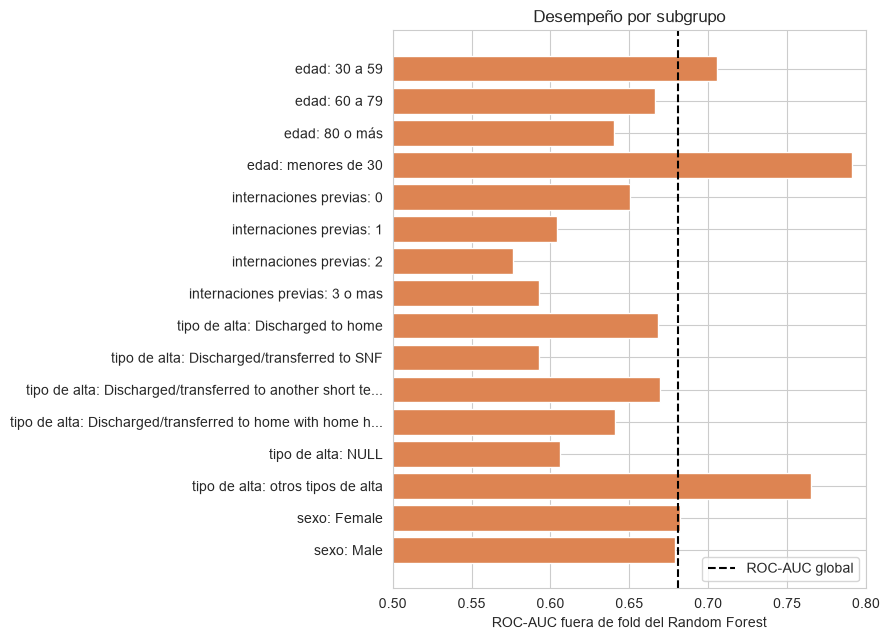

In [99]:
fig, ax = plt.subplots(figsize=(9, 6.5))
d = tabla_sub.reset_index()
etiquetas = [f"{g}: {n}" for g, n in zip(d["grupo"], d["nivel"])]
ax.barh(etiquetas[::-1], d["ROC-AUC"].to_numpy()[::-1], color="#DD8452")
ax.axvline(roc_auc_score(y_ent, p_sub), color="black", ls="--", label="ROC-AUC global")
ax.set_xlim(0.5, 0.8)
ax.set_xlabel("ROC-AUC fuera de fold del Random Forest")
ax.set_title("Desempeño por subgrupo")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las barras muestran el mismo patrón: el modelo discrimina mejor en los pacientes más
jóvenes y peor dentro de los niveles de internaciones previas y del alta a centros de enfermería. Los grupos más
pequeños (menores de 30 y otros tipos de alta) son los más inciertos. No aparece un subgrupo con desempeño
cercano al azar (0,5).

## 8.9 M9 — Evaluación final en el test

Es la **única** vez que se usa el test. Antes de abrirlo quedan congelados: las 18 variables y el
preprocesamiento (se ajusta con todo el train), los hiperparámetros ganadores de M5, los umbrales de M6 (elegidos
con predicciones fuera de fold del train), el basal y la regla de elección de M7, que señala a Random Forest. Los
cuatro algoritmos y el basal se evalúan una vez, con esas configuraciones, y no se vuelve a iterar sobre
el modelo mirando estos resultados.

Cada algoritmo se reentrena con **todo el train**. En XGBoost y CatBoost no hay un conjunto apartado para el early
stopping, así que la cantidad de árboles se toma del promedio de los 5 folds de M6 y se multiplica por 1,25,
porque el modelo final ve unas 1,25 veces más datos que el de cada fold (ajuste habitual; conocimiento general).

Las métricas se informan con **intervalo de confianza del 95 %** por *bootstrap* (conocimiento general). Se
remuestrean **pacientes**, no filas, porque las internaciones de un mismo paciente están correlacionadas y un
bootstrap por fila daría intervalos demasiado angostos. Con 1.000 réplicas se calcula también la mejora de cada
algoritmo sobre el basal.

In [100]:
# --- Abrir el test (única vez) ---
sellado = pd.read_pickle(ARTEFACTOS / "test_sellado.pkl")
Xm_test, y_test = sellado["X"], np.asarray(sellado["y"])
grupos_test = np.asarray(sellado["grupos"])
print(f"Test: {len(y_test)} filas, {len(set(grupos_test))} pacientes, tasa de reingreso {y_test.mean():.4f}")

# --- Preprocesamiento ajustado con TODO el train (target encoding fuera de fold para las filas de train) ---
prep_final = preprocesamiento()
Z_tr = prep_final.fit_transform(Xm_train, y_ent)
Z_te = prep_final.transform(Xm_test)
assert Z_tr.shape[1] == Z_te.shape[1] == 26

# --- Cantidad de árboles de los boosting: promedio de M6 por 1,25 ---
N_ARBOLES = {n: int(round(np.mean(ARBOLES[n]) * 1.25)) for n in ["XGBoost", "CatBoost"]}


def modelo_final(nombre):
    p = CONFIG_GANADORA[nombre]
    if nombre == "XGBoost":
        return XGBClassifier(n_estimators=N_ARBOLES[nombre], tree_method="hist", n_jobs=-1, random_state=SEMILLA, **p)
    if nombre == "CatBoost":
        return CatBoostClassifier(iterations=N_ARBOLES[nombre], random_seed=SEMILLA, verbose=0, thread_count=-1, **p)
    return construir(nombre, p, SEMILLA)


MODELOS_FINALES, p_test = {}, {}
for nombre in ALGORITMOS:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        MODELOS_FINALES[nombre] = modelo_final(nombre).fit(Z_tr, y_ent.to_numpy())
    p_test[nombre] = MODELOS_FINALES[nombre].predict_proba(Z_te)[:, 1]

# --- Basal: tabla de tasas con todo train y regla de decisión de M1 ---
tasas_basal = y_ent.groupby(Xm_train[VAR_BASAL].astype(object)).mean()
s_tr = Xm_train[VAR_BASAL].astype(object).map(tasas_basal).astype(float).to_numpy()
p_test["Basal"] = Xm_test[VAR_BASAL].astype(object).map(tasas_basal).fillna(y_ent.mean()).astype(float).to_numpy()
u_basal = (np.median(s_tr[y_ent == 0]) + np.median(s_tr[y_ent == 1])) / 2
if (p_test["Basal"] > u_basal).sum() == 0:
    u_basal = y_ent.mean()

UMBRAL_FINAL = {n: float(UMBRALES[int(np.argmax(curvas[n]))]) for n in ALGORITMOS}
UMBRAL_FINAL["Basal"] = float(u_basal)
pred_test = {n: ((p_test[n] > UMBRAL_FINAL[n]) if n == "Basal" else (p_test[n] >= UMBRAL_FINAL[n])).astype(int)
             for n in MODELOS}
print("Árboles finales:", N_ARBOLES, "| umbrales:", {k: round(v, 3) for k, v in UMBRAL_FINAL.items()})

Test: 30180 filas, 21455 pacientes, tasa de reingreso 0.1091


Árboles finales: {'XGBoost': 244, 'CatBoost': 549} | umbrales: {'Regresión logística': 0.13, 'Random Forest': 0.15, 'XGBoost': 0.145, 'CatBoost': 0.145, 'Basal': 0.108}


In [101]:
# --- Bootstrap por paciente: cada réplica remuestrea pacientes y pondera sus filas ---
codigo_pac, _ = pd.factorize(grupos_test)
n_pac = codigo_pac.max() + 1
rng = np.random.RandomState(SEMILLA)
N_BOOT = 1000
NOMBRES_MET = ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]


def met_pesadas(y, p, pred, w):
    tp = np.sum(w * ((pred == 1) & (y == 1))); fn = np.sum(w * ((pred == 0) & (y == 1)))
    fp = np.sum(w * ((pred == 1) & (y == 0))); tn = np.sum(w * ((pred == 0) & (y == 0)))
    rec = tp / (tp + fn) if tp + fn else 0.0
    pre = tp / (tp + fp) if tp + fp else 0.0
    return {"ROC-AUC": roc_auc_score(y, p, sample_weight=w), "AUC-PR": average_precision_score(y, p, sample_weight=w),
            "recall": rec, "precisión": pre, "F1": 2 * pre * rec / (pre + rec) if pre + rec else 0.0,
            "exactitud balanceada": (rec + tn / (tn + fp)) / 2}


puntual = {n: met_pesadas(y_test, p_test[n], pred_test[n], np.ones(len(y_test))) for n in MODELOS}
boot = {n: [] for n in MODELOS}
for _ in range(N_BOOT):
    cuenta = np.bincount(rng.randint(0, n_pac, n_pac), minlength=n_pac)
    w = cuenta[codigo_pac].astype(float)
    for n in MODELOS:
        boot[n].append(met_pesadas(y_test, p_test[n], pred_test[n], w))
boot = {n: pd.DataFrame(b) for n, b in boot.items()}

filas = {}
for n in MODELOS:
    filas[n] = {c: f"{puntual[n][c]:.3f} [{boot[n][c].quantile(0.025):.3f}; {boot[n][c].quantile(0.975):.3f}]"
                for c in NOMBRES_MET}
tabla_test = pd.DataFrame(filas).T.loc[["Basal"] + ALGORITMOS]
for n in MODELOS:
    registrar(fase="M9", algoritmo=n, **{c: puntual[n][c] for c in NOMBRES_MET})
guardar_registro()
tabla_test

,ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
Basal,0.603 [0.592; 0.613],0.153 [0.144; 0.163],0.488 [0.468; 0.507],0.162 [0.153; 0.170],0.244 [0.231; 0.254],0.590 [0.580; 0.600]
Regresión logística,0.665 [0.654; 0.676],0.201 [0.189; 0.215],0.427 [0.407; 0.446],0.201 [0.191; 0.211],0.274 [0.260; 0.287],0.610 [0.600; 0.620]
Random Forest,0.677 [0.666; 0.687],0.211 [0.199; 0.224],0.405 [0.385; 0.425],0.214 [0.203; 0.225],0.280 [0.266; 0.293],0.612 [0.602; 0.621]
XGBoost,0.679 [0.668; 0.689],0.218 [0.205; 0.232],0.445 [0.425; 0.464],0.205 [0.194; 0.215],0.281 [0.267; 0.294],0.617 [0.608; 0.626]
CatBoost,0.680 [0.669; 0.690],0.220 [0.206; 0.233],0.425 [0.404; 0.445],0.210 [0.199; 0.220],0.281 [0.267; 0.294],0.614 [0.605; 0.624]


**Lectura de la tabla.** En el test, evaluado una sola vez, los cuatro algoritmos superan al basal en el
ROC-AUC y en el AUC-PR: 0,665 la regresión logística, 0,677 Random Forest (el modelo que eligió la regla de M7),
0,679 XGBoost y 0,680 CatBoost, contra 0,603 del basal. Son unas 0,004 a 0,005 menos que en la validación
cruzada (0,6705, 0,6811, 0,6811 y 0,6828), una diferencia que cae dentro de los intervalos de confianza. Los
intervalos de los tres ensambles se superponen casi por completo ([0,666; 0,687], [0,668; 0,689] y [0,669;
0,690]), de modo que el test tampoco los distingue entre sí; la regresión logística (0,665) queda por debajo, y
en la validación cruzada esa diferencia sí fue significativa. Con los umbrales fijados en M6, el F1 va de 0,274 a
0,281 (basal 0,244), la precisión de 0,20 a 0,21 (basal 0,162), el recall de 0,41 a 0,45 (basal 0,488) y la
exactitud balanceada de 0,610 a 0,617 (basal 0,590): los algoritmos ganan precisión y F1 a costa de algo de
recall, igual que en la validación cruzada. El AUC-PR sube de 0,153 a entre 0,201 y 0,220, con una prevalencia
de 0,109 en el test.

In [102]:
# Mejora de cada algoritmo sobre el basal (diferencia con el mismo remuestreo de pacientes)
filas = []
for n in ALGORITMOS:
    for c in ["ROC-AUC", "AUC-PR", "F1"]:
        d = boot[n][c] - boot["Basal"][c]
        filas.append({"algoritmo": n, "métrica": c, "mejora sobre el basal": puntual[n][c] - puntual["Basal"][c],
                      "IC 95 % inferior": d.quantile(0.025), "IC 95 % superior": d.quantile(0.975)})
mejora_test = pd.DataFrame(filas).set_index(["algoritmo", "métrica"])
mejora_test.round(4)

mejora sobre el basal  IC 95 % inferior  \
algoritmo           métrica                                            
Regresión logística ROC-AUC                 0.0625            0.0548   
                    AUC-PR                  0.0478            0.0408   
                    F1                      0.0299            0.0214   
Random Forest       ROC-AUC                 0.0745            0.0662   
                    AUC-PR                  0.0581            0.0508   
                    F1                      0.0365            0.0266   
XGBoost             ROC-AUC                 0.0761            0.0675   
                    AUC-PR                  0.0649            0.0565   
                    F1                      0.0372            0.0282   
CatBoost            ROC-AUC                 0.0774            0.0692   
                    AUC-PR                  0.0663            0.0577   
                    F1                      0.0373            0.0279   

                             IC 95 % superior  
algoritmo           métrica                    
Regresión logística ROC-AUC            0.0702  
                    AUC-PR             0.0565  
                    F1                 0.0381  
Random Forest       ROC-AUC            0.0828  
                    AUC-PR             0.0654  
                    F1                 0.0461  
XGBoost             ROC-AUC            0.0847  
                    AUC-PR             0.0736  
                    F1                 0.0463  
CatBoost            ROC-AUC            0.0862  
                    AUC-PR             0.0749  
                    F1                 0.0461

**Lectura de la mejora sobre el basal.** La mejora de cada algoritmo es significativa, porque los intervalos
del 95 % de la diferencia no incluyen el cero: en ROC-AUC, +0,063 la regresión logística [0,055; 0,070], +0,075
Random Forest [0,066; 0,083], +0,076 XGBoost [0,068; 0,085] y +0,077 CatBoost [0,069; 0,086]; en AUC-PR,
entre +0,048 y +0,066; y en F1, entre +0,030 y +0,037. En términos absolutos la mejora es modesta: el mejor
modelo ordena correctamente alrededor del 68 % de los pares formados por un paciente que reingresa y otro que
no, contra el 60 % del basal.

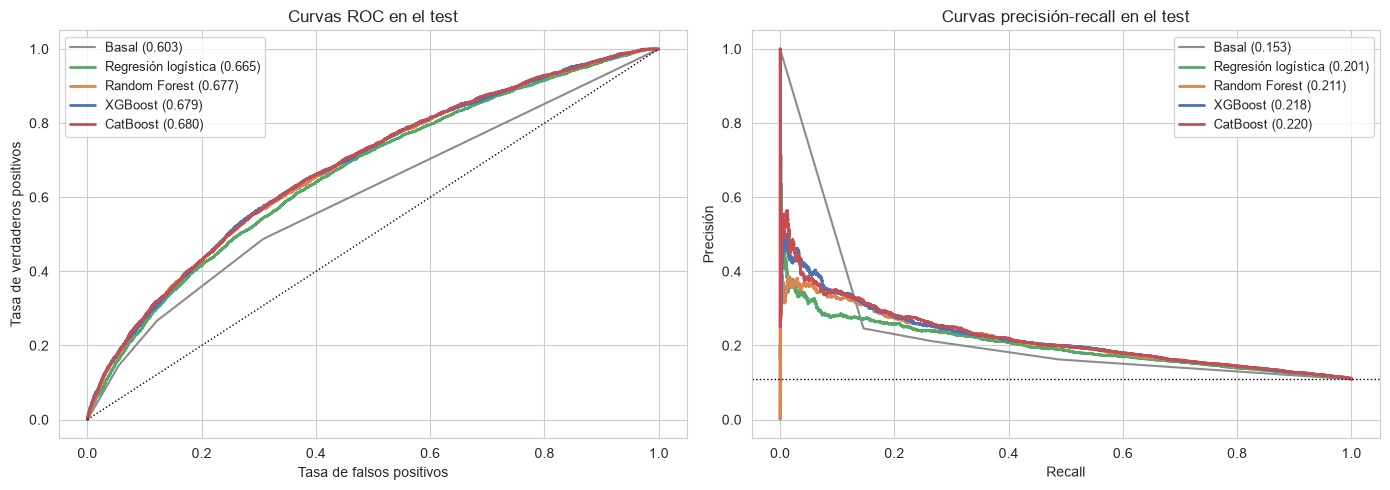

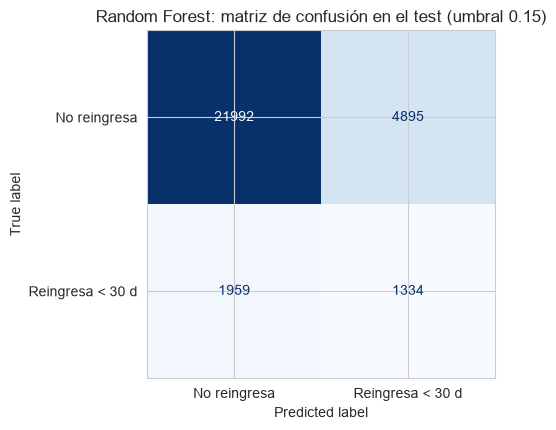

Verdaderos negativos 21992, falsos positivos 4895, falsos negativos 1959, verdaderos positivos 1334


In [103]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
colores_m = {"Basal": "#8C8C8C", "Regresión logística": "#55A868", "Random Forest": "#DD8452",
             "XGBoost": "#4C72B0", "CatBoost": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in MODELOS:
    fpr, tpr, _ = roc_curve(y_test, p_test[n])
    axes[0].plot(fpr, tpr, label=f"{n} ({puntual[n]['ROC-AUC']:.3f})", color=colores_m[n], lw=2 if n != "Basal" else 1.5)
    pre, rec, _ = precision_recall_curve(y_test, p_test[n])
    axes[1].plot(rec, pre, label=f"{n} ({puntual[n]['AUC-PR']:.3f})", color=colores_m[n], lw=2 if n != "Basal" else 1.5)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curvas ROC en el test")
axes[1].axhline(y_test.mean(), color="black", ls=":", lw=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
axes[1].set_title("Curvas precisión-recall en el test")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test[elegido]),
                       display_labels=["No reingresa", "Reingresa < 30 d"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{elegido}: matriz de confusión en el test (umbral {UMBRAL_FINAL[elegido]:.2f})")
plt.tight_layout()
plt.show()
cm = confusion_matrix(y_test, pred_test[elegido])
print(f"Verdaderos negativos {cm[0,0]}, falsos positivos {cm[0,1]}, falsos negativos {cm[1,0]}, verdaderos positivos {cm[1,1]}")

**Lectura de los gráficos.** Las curvas ROC de los tres ensambles son prácticamente indistinguibles, la de la
regresión logística queda algo por debajo en la zona media, y todas están por encima del basal, cuya curva solo
tiene tres tramos porque su puntaje toma cuatro valores. En las curvas de precisión-recall los cuatro modelos
superan la prevalencia (línea punteada, 0,109) y se parecen entre sí: la precisión cae rápido al exigir más
recall, y con un recall cercano a 0,4 es de alrededor de 0,2 en todos. La matriz de confusión del Random Forest
con el umbral 0,15 muestra que identifica 1.334 de los 3.293 reingresos (recall 0,405) y marca a 4.895 pacientes
que no reingresan, de 26.887 (18 %). En total marca al 21 % de los pacientes y, de cada 100 marcados, 21
reingresan (precisión 0,214), casi el doble de la tasa de la población (10,9 %).

In [104]:
# Artefactos: pipelines finales ajustados (preprocesamiento + modelos) y resultados del test
import joblib
joblib.dump({"preprocesamiento": prep_final, "modelos": MODELOS_FINALES, "umbrales": UMBRAL_FINAL,
             "arboles": N_ARBOLES, "elegido": elegido}, ARTEFACTOS / "pipelines_finales.joblib", compress=3)
pd.DataFrame(puntual).T.to_csv(ARTEFACTOS / "m9_resultados_test.csv")
pd.DataFrame([{"modelo": n, "metrica": c, "estimacion": puntual[n][c], "ic_inferior": boot[n][c].quantile(0.025),
               "ic_superior": boot[n][c].quantile(0.975)} for n in MODELOS for c in NOMBRES_MET]
             ).to_csv(ARTEFACTOS / "m9_resultados_test_ic.csv", index=False)
mejora_test.to_csv(ARTEFACTOS / "m9_mejora_sobre_basal.csv")
(ARTEFACTOS / "m9_matriz_confusion.json").write_text(json.dumps(
    {"modelo": elegido, "umbral": UMBRAL_FINAL[elegido], "matriz": confusion_matrix(y_test, pred_test[elegido]).tolist()}))
print("Guardado: pipelines_finales.joblib y los resultados del test en artefactos_ml/")

Guardado: pipelines_finales.joblib y los resultados del test en artefactos_ml/


## 8.10 M10 — Limitaciones, reflexión y reproducibilidad

### Resultado

Con las 18 variables del EDA, los cuatro algoritmos superan al basal. En el test, evaluado una sola vez, el
ROC-AUC va de 0,665 (regresión logística) a 0,680 (CatBoost), contra 0,603 del basal, es decir una mejora de
0,063 a 0,077 con intervalos del 95 % que excluyen el cero. Los tres ensambles (Random Forest, XGBoost y
CatBoost) no se distinguen entre sí ni en la validación cruzada ni en el test, y superan a la regresión logística
por unas 0,011 en la validación cruzada. La regla de elección declarada de antemano señala a Random Forest como
modelo final por parsimonia (ROC-AUC 0,677 en el test), pero CatBoost y XGBoost serían igualmente defendibles. Con
el umbral elegido sin mirar el test, los algoritmos ganan entre 0,04 y 0,05 de precisión y de 0,03 a 0,04 de F1
frente al basal, a costa de 0,04 a 0,08 de recall. Se cumple el criterio de éxito de M2 (la mejora supera el desvío entre
folds), aunque la mejora en términos absolutos es modesta.

### Por qué el desempeño es acotado: hipótesis

Los cuatro algoritmos, de tres familias distintas y con hiperparámetros ajustados por tres mecanismos, llegan a la
misma meseta de ROC-AUC (entre 0,67 y 0,68), y el ajuste de hiperparámetros apenas movió el resultado (+0,008 en
CatBoost, +0,0001 en la regresión logística). Cuando todos los modelos convergen al mismo valor, lo más probable es
que el límite lo ponga la información disponible y no el algoritmo, que es la advertencia de la cátedra: si tras
varios modelos y búsquedas la ganancia sobre el basal es chica, el problema probablemente es de datos. Las causas
posibles son que el reingreso dependa de factores ausentes en el registro (adherencia al tratamiento, apoyo social,
seguimiento ambulatorio posterior), que el diagnóstico venga agrupado por capítulo y no por código, que los
resultados de glucosa y de hemoglobina glicosilada falten en su mayoría, y que se mezclen 130 instituciones con
prácticas distintas.
Son hipótesis y no se verificaron en este trabajo.

### Limitaciones

- **Selección de variables fuera de los folds.** Las 18 variables se eligieron con todo el entrenamiento. El chequeo
  de la sección 8.3.1 muestra que cinco variables marginales cambian de decisión según la muestra, y ninguna es
  importante, de modo que el efecto sobre la validación se considera menor.
- **Validación cruzada sin anidar.** El puntaje de una carrera es optimista; al reevaluar a los ganadores con folds
  de otras semillas el optimismo fue de 0,000 a −0,001.
- **Costo de los errores no cuantificado.** No se definió un punto de operación; las métricas secundarias usan un
  umbral técnico (el que maximiza el F1) y no uno basado en costos o en capacidad de seguimiento.
- **Un solo conjunto de datos.** Los datos son de 1999 a 2008 y no incluyen el hospital, de modo que no se evaluó la
  validez externa por institución ni a períodos posteriores. La partición agrupa por paciente, pero no por hospital.
- **Historial del paciente.** `patient_nbr_ordinal` supone que el registro contiene todas las internaciones previas del paciente.
- **Implementación de CatBoost.** Solo tiene respaldo teórico en la cátedra; sus hiperparámetros y rangos son
  conocimiento general. Las pruebas pareadas, el bootstrap por paciente y la regla del error estándar también lo son.

### Nuevos caminos

- Sumar información que el registro no tiene: códigos de diagnóstico completos en lugar de capítulos, resultados
  de laboratorio, comorbilidades y el tiempo transcurrido desde el alta anterior.
- Modelar por separado a los pacientes de alto historial de internaciones, donde el desempeño del modelo es menor.
- Si se dispone de la capacidad de seguimiento o de los costos reales, fijar un punto de operación y calibrar las
  probabilidades.
- Validar por hospital y por período para medir la validez externa.
- Agregar interpretabilidad local por paciente.

### Reproducibilidad

El notebook se ejecuta de punta a punta en el entorno `ML` (Python 3.13, scikit-learn 1.9.1, XGBoost 3.4.2,
CatBoost 1.2.10, Optuna 5.0.0). Las semillas son 42 (global, split, carrera principal), 42 a 45 (folds) y 43 y 44
(repeticiones de la carrera). En la carpeta `artefactos_ml` quedan los índices del split y de los folds, la
configuración y los espacios de búsqueda, los resultados de las carreras (`m5_carrera_semilla*.pkl`, que el
notebook reutiliza si existen en lugar de recalcularlas; cada carrera tarda alrededor de una hora en 14 núcleos),
el registro de todos los experimentos (`registro_experimentos.csv`), los umbrales, los pipelines finales
serializados y los resultados del test. El test se guarda sellado (`test_sellado.pkl`) y solo se abre en 8.9.